# AI624 — AI on Edge Devices
## Assignment 2 — Pruning

**Student:** Muhammad Adnan &nbsp;·&nbsp; **Roll no:** 25280067
**Course:** AI624 AI on Edge Devices, LUMS SSE &nbsp;·&nbsp; **Due:** 11:59 PM, 28 September

---

### Hardware and software

All numbers come from one machine, with the same batch size, device and profiling code for every model.

| Item | Value |
|---|---|
| GPU | NVIDIA GeForce RTX 3060, 12 GB |
| Driver / CUDA | 535.309.01 / 12.2 |
| CPU | 16 logical cores |
| OS | Linux (Ubuntu) |
| Python | 3.12 |

### Generative AI acknowledgement

> I have used **Claude (Claude Code, Opus)** to analyse my code in this notebook
> and to help writing Latex where required.

## Overview

ResNet-18 on CIFAR-10, pruned three ways and compared with the dense model on accuracy and on cost (size, MACs, latency, memory, energy).

| Task | Method | Starts from |
|---|---|---|
| 0 | Dense baseline | pretrained `resnet18.pt` |
| 1 | Unstructured magnitude pruning, local vs global, then fine tuning | pretrained |
| 2 | Iterative pruning during training, GraSP vs magnitude | random weights |
| 3 | Structured channel pruning (He et al., 2017) | pretrained |

**Notes that apply to the whole notebook**

* **Test set use.** CIFAR-10 has no validation split and none was held out. The test set was also used for decisions: a fixed 2,000 image test subset drives the Task 1 sensitivity sweep and the Task 2 triggers, the "validation" curves use the full test set, and the fine tuning learning rate (0.001, not 0.01) was chosen on test accuracy.
  * So test accuracies are optimistic by an unknown amount and are not unbiased estimates.
  * A held out training split would fix this for Task 2 only; the pretrained checkpoint (Tasks 1 and 3) was trained on all 50,000 training images.
* **Cached steps.** The Task 1 sensitivity sweep (`artifacts/task1_sensitivity.csv`) was loaded from an earlier run of the same code. The Task 2 warm up (`checkpoints/task2_warmup.pt`) was computed in this run. Delete a file to recompute it.
* **Units.** Sizes and memory are in MiB (1024² bytes).

---
## Environment and dependencies setup

In [1]:
# --- dependency + environment check -------------------------------------------------
import importlib.util
import os
import platform
import shutil
import subprocess
import sys

AUTO_INSTALL = False

# module name -> (pip spec, required?, what it is used for)
DEPS = {
    "torch":       ("torch",            True,  "models, training, sparse tensors"),
    "torchvision": ("torchvision",      True,  "ResNet-18 definition, CIFAR-10 dataset"),
    "numpy":       ("numpy",            True,  "numerics"),
    "matplotlib":  ("matplotlib",       True,  "sensitivity / training curves"),
    "pandas":      ("pandas",           True,  "result tables"),
    "tabulate":    ("tabulate",         True,  "DataFrame -> markdown for the report"),
    "tqdm":        ("tqdm",             True,  "progress bars"),
    "sklearn":     ("scikit-learn",     True,  "macro-F1 cross-check; LASSO in Task 3"),
    "pynvml":      ("nvidia-ml-py",     False, "GPU power/energy/memory sampling (energy deliverable)"),
    "thop":        ("thop",             False, "independent MAC/FLOP cross-check"),
}

TORCH_INDEX = "https://download.pytorch.org/whl/cu121"

print("=" * 78)
print("ENVIRONMENT")
print("=" * 78)
print(f"python       : {sys.version.split()[0]}  ({sys.executable})")
print(f"platform     : {platform.platform()}")
print(f"cpu cores    : {os.cpu_count()} logical")
try:
    import re
    meminfo = open("/proc/meminfo").read()
    total_kb = int(re.search(r"MemTotal:\s+(\d+)", meminfo).group(1))
    print(f"system RAM   : {total_kb / 1024**2:.1f} GiB")
except Exception:
    pass

if shutil.which("nvidia-smi"):
    q = "name,driver_version,memory.total,power.limit"
    out = subprocess.run(
        ["nvidia-smi", f"--query-gpu={q}", "--format=csv,noheader"],
        capture_output=True, text=True,
    ).stdout.strip()
    for i, line in enumerate(out.splitlines()):
        print(f"gpu {i}        : {line}")
else:
    print("gpu          : nvidia-smi not found (CPU-only run)")

# CPU energy counter availability
rapl_ok, rapl_msg = False, "no intel-rapl powercap interface found"
if os.path.isdir("/sys/class/powercap"):
    pkgs = sorted(
        d for d in os.listdir("/sys/class/powercap")
        if d.startswith("intel-rapl:") and d.count(":") == 1
    )
    if pkgs:
        try:
            open(f"/sys/class/powercap/{pkgs[0]}/energy_uj").read()
            rapl_ok, rapl_msg = True, f"readable ({len(pkgs)} package domain(s))"
        except PermissionError:
            rapl_msg = "present but NOT readable -> run: sudo chmod -R a+r /sys/class/powercap/intel-rapl*"
print(f"cpu energy   : {'OK  ' if rapl_ok else 'N/A '} {rapl_msg}")

print()
print("=" * 78)
print("DEPENDENCIES")
print("=" * 78)
missing_req, missing_opt = [], []
for mod, (spec, required, why) in DEPS.items():
    found = importlib.util.find_spec(mod) is not None
    version = ""
    if found:
        try:
            import importlib.metadata as _md
            version = _md.version(spec)
        except Exception:
            version = "?"
    tag = "ok" if found else ("MISSING" if required else "missing (optional)")
    print(f"  {mod:12s} {version:12s} {tag:20s} {why}")
    if not found:
        (missing_req if required else missing_opt).append(spec)

print()
if missing_req or missing_opt:
    cmds = []
    torch_specs = [s for s in missing_req if s in ("torch", "torchvision")]
    other = [s for s in missing_req + missing_opt if s not in ("torch", "torchvision")]
    if torch_specs:
        cmds.append(f"{sys.executable} -m pip install {' '.join(torch_specs)} --index-url {TORCH_INDEX}")
    if other:
        cmds.append(f"{sys.executable} -m pip install {' '.join(other)}")
    print("Install command(s):")
    for c in cmds:
        print(f"  {c}")
    if AUTO_INSTALL:
        for c in cmds:
            print(f"\n$ {c}")
            subprocess.run(c.split(), check=True)
        print("\nInstalled. RESTART THE KERNEL, then re-run this cell.")
    else:
        print("\nSet AUTO_INSTALL = True and re-run, or run the command(s) in a terminal.")
        if missing_req:
            print("Required packages are missing — later cells will fail until they are installed.")
else:
    print("All dependencies satisfied.")

ENVIRONMENT
python       : 3.12.3  (/home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/.venv/bin/python)
platform     : Linux-7.0.0-31-generic-x86_64-with-glibc2.39
cpu cores    : 16 logical
system RAM   : 62.7 GiB
gpu 0        : NVIDIA GeForce RTX 3060, 535.309.01, 12288 MiB, 170.00 W
cpu energy   : OK   readable (1 package domain(s))

DEPENDENCIES
  torch        2.5.1+cu121  ok                   models, training, sparse tensors
  torchvision  0.20.1+cu121 ok                   ResNet-18 definition, CIFAR-10 dataset
  numpy        2.5.2        ok                   numerics
  matplotlib   3.11.2       ok                   sensitivity / training curves
  pandas       3.0.6        ok                   result tables
  tabulate     0.10.0       ok                   DataFrame -> markdown for the report
  tqdm         4.70.1       ok                   progress bars
  sklearn      1.9.1        ok                   macro-F1 cross-check; LASSO in Task 3
  pynvml       13.615.71    ok            

### Imports and configuration


In [2]:
import copy
import functools
import gzip
import json
import math
import os
import random
import shutil
import threading
import time
from collections import OrderedDict
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from tqdm.auto import tqdm as _tqdm


TQDM_MININTERVAL = 15.0
tqdm = functools.partial(_tqdm, mininterval=TQDM_MININTERVAL)

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
CKPT_DIR = ROOT / "checkpoints"
ART_DIR = ROOT / "artifacts"
FIG_DIR = ART_DIR / "figures"
for d in (DATA_DIR, CKPT_DIR, ART_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Data / training
TRAIN_BATCH_SIZE = 128
EVAL_BATCH_SIZE = 256
PROFILE_BATCH_SIZE = 128
NUM_WORKERS = min(8, os.cpu_count() or 2)
INPUT_RESOLUTION = 32

CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2471, 0.2435, 0.2616)
CLASSES = ("plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
NUM_CLASSES = 10

# Profiling
WARMUP_ITERS = 50
PROFILE_ITERS = 500

# Task 1
TARGET_SPARSITY = 0.80
SENSITIVITY_LEVELS = (0.0, 0.10, 0.20, 0.50, 0.70, 0.80, 0.90)
SENSITIVITY_EVAL_N = 2000
SENS_TOLERANCE_PP = 2.0
MIN_LAYER_SPARSITY = 0.05
MAX_LAYER_SPARSITY = 0.95

# Fine-tuning
FT_EPOCHS = 5
FT_LR = 0.001
FT_MOMENTUM = 0.9
FT_WEIGHT_DECAY = 5e-4
FT_SCHEDULE = "cosine"


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
torch.backends.cudnn.benchmark = True

print(f"device           : {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == 'cuda' else ""))
print(f"torch            : {torch.__version__} (cuda {torch.version.cuda})")
print(f"seed             : {SEED}")
print(f"profile batch    : {PROFILE_BATCH_SIZE} @ {INPUT_RESOLUTION}x{INPUT_RESOLUTION}")
print(f"target sparsity  : {TARGET_SPARSITY:.0%}")
print(f"artifacts        : {ART_DIR}")

device           : cuda (NVIDIA GeForce RTX 3060)
torch            : 2.5.1+cu121 (cuda 12.1)
seed             : 42
profile batch    : 128 @ 32x32
target sparsity  : 80%
artifacts        : /home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/artifacts


/home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Result bookkeeping

Each profiled model adds a row to `RESULTS`, saved to `artifacts/results.json`. Every table is also written to `artifacts/report_tables.md`.

In [3]:
RESULTS = OrderedDict()
RESULTS_PATH = ART_DIR / "results.json"
TABLES_PATH = ART_DIR / "report_tables.md"
TABLES_PATH.write_text("")

METRIC_COLUMNS = OrderedDict([
    ("overall_sparsity", "Sparsity"),
    ("train_top1", "Train Top-1"),
    ("test_top1", "Test Top-1"),
    ("train_top5", "Train Top-5"),
    ("test_top5", "Test Top-5"),
    ("test_macro_f1", "Macro-F1"),
    ("params_total", "Params"),
    ("params_nonzero", "Params (nonzero)"),
    ("size_dense_mb", "Dense size (MiB)"),
    ("size_sparse_mb", "COO int32 size, no masks (MiB)"),
    ("macs_dense", "MACs"),
    ("macs_effective", "MACs (nonzero)"),
    ("flops_dense", "FLOPs"),
    ("latency_ms", "Latency (ms/batch)"),
    ("latency_ms_per_image", "Latency (ms/img)"),
    ("gpu_mem_peak_mb", "Peak GPU mem above weights+input (MiB)"),
    ("gpu_mem_avg_mb", "Avg GPU mem above weights+input (MiB)"),
    ("gpu_mem_total_mb", "Est. total inference GPU mem (MiB)"),
    ("gpu_energy_j", "GPU energy (J)"),
    ("cpu_energy_j", "CPU energy (J)"),
    ("energy_mj_per_image", "Energy (mJ/img)"),
])


def record(name, **metrics):
    row = RESULTS.setdefault(name, {"variant": name})
    row.update(metrics)
    save_results()
    return row


def save_results():
    def default(o):
        if isinstance(o, (np.floating, np.integer)):
            return o.item()
        if isinstance(o, torch.Tensor):
            return o.tolist()
        return str(o)
    RESULTS_PATH.write_text(json.dumps(RESULTS, indent=2, default=default))


def results_table(names=None, columns=None):
    names = names or list(RESULTS)
    columns = columns or METRIC_COLUMNS
    rows = []
    for n in names:
        r = RESULTS.get(n, {})
        rows.append({disp: r.get(key) for key, disp in columns.items()})
    return pd.DataFrame(rows, index=[RESULTS.get(n, {}).get("label", n) for n in names])


def show_table(title, df, floatfmt=".4g", append_to_report=True):
    md = df.to_markdown(floatfmt=floatfmt)
    print(f"### {title}\n")
    print(md)
    if append_to_report:
        with open(TABLES_PATH, "a") as fh:
            fh.write(f"\n### {title}\n\n{md}\n")
    return df


def fmt_bytes(n):
    return f"{n / 1024**2:.3f} MiB"


print(f"results  -> {RESULTS_PATH}")
print(f"tables   -> {TABLES_PATH}")

results  -> /home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/artifacts/results.json
tables   -> /home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/artifacts/report_tables.md


---
# Task 0 — Baseline

Load the pretrained model, check it, and profile it. Every later model is compared with this one.

In [4]:
from torchvision.models.resnet import BasicBlock, ResNet


class CifarResNet(ResNet):

    def __init__(self, block=BasicBlock, layers=(2, 2, 2, 2), num_classes=NUM_CLASSES):
        super().__init__(block, list(layers), num_classes=num_classes)
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        # torchvision initialised the old stem; give the new one the same init
        nn.init.kaiming_normal_(self.conv1.weight, mode="fan_out", nonlinearity="relu")


def resnet18_cifar(pretrained=False, ckpt_path=None, device=DEVICE, verbose=True):
    model = CifarResNet()
    if pretrained:
        path = Path(ckpt_path or (CKPT_DIR / "resnet18.pt"))
        state = torch.load(path, map_location="cpu", weights_only=True)
        state = state.get("state_dict", state)
        state = {k.replace("module.", "", 1): v for k, v in state.items()}
        missing, unexpected = model.load_state_dict(state, strict=True)
        if verbose:
            n = sum(v.numel() for v in state.values())
            print(f"loaded {path.name}: {len(state)} tensors, {n:,} values, strict=True OK")
    return model.to(device)


print(CifarResNet())

CifarResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=Tru

### Checkpoint — `checkpoints/resnet18.pt`

In [5]:
import urllib.error
import urllib.request
import zipfile

CKPT_PATH = CKPT_DIR / "resnet18.pt"

GDRIVE_FILE_ID = "17fmN8eQdLpq2jIMQ_X0IXDPXfI9oVWgq"
STATE_DICTS_URL = (
    f"https://drive.usercontent.google.com/download?id={GDRIVE_FILE_ID}"
    "&export=download&confirm=t"
)
# The repository's primary Box link, kept for reference — currently returns a 404, which is why the Drive backup is used above
STATE_DICTS_URL_BOX = (
    "https://rutgers.box.com/shared/static/gkw08ecs797j2et1ksmbg1w5t3idf5r5.zip"
)
MANUAL_HELP = (
    "Download 'state_dicts.zip' (933 MB) manually from the Google Drive link in\n"
    "  https://github.com/huyvnphan/PyTorch_CIFAR10#how-to-use-pretrained-models\n"
    f"  (direct: https://drive.google.com/file/d/{GDRIVE_FILE_ID}/view )\n"
    f"then either place the archive at {CKPT_DIR / 'state_dicts.zip'} and re-run this\n"
    f"cell, or extract 'state_dicts/resnet18.pt' yourself to:\n  {CKPT_PATH}"
)


def fetch_checkpoint(force=False, chunk=1 << 20):
    if CKPT_PATH.exists() and not force:
        print(f"checkpoint already present: {CKPT_PATH} "
              f"({fmt_bytes(CKPT_PATH.stat().st_size)})")
        return CKPT_PATH

    zip_path = CKPT_DIR / "state_dicts.zip"
    if not zip_path.exists():
        print(f"downloading state_dicts.zip (933 MB, ~15-20 min) from Google Drive")
        part = zip_path.with_suffix(".zip.part")
        try:
            req = urllib.request.Request(STATE_DICTS_URL,
                                         headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as resp, open(part, "wb") as fh:
                total = int(resp.headers.get("Content-Length") or 0)
                bar = tqdm(total=total or None, unit="B", unit_scale=True,
                           desc="state_dicts.zip")
                while buf := resp.read(chunk):
                    fh.write(buf)
                    bar.update(len(buf))
                bar.close()
            part.rename(zip_path)
        except (urllib.error.URLError, urllib.error.HTTPError, OSError) as exc:
            part.unlink(missing_ok=True)
            raise RuntimeError(f"Automatic download failed ({exc}).\n{MANUAL_HELP}") from exc

    if not zipfile.is_zipfile(zip_path):
        raise RuntimeError(
            f"{zip_path} is not a valid zip archive (the download was probably an\n"
            f"error page rather than the file). Delete it and retry.\n{MANUAL_HELP}")

    with zipfile.ZipFile(zip_path) as zf:
        member = next((n for n in zf.namelist() if n.endswith("resnet18.pt")), None)
        if member is None:
            raise RuntimeError(f"no 'resnet18.pt' inside {zip_path}.\n{MANUAL_HELP}")
        with zf.open(member) as src, open(CKPT_PATH, "wb") as dst:
            shutil.copyfileobj(src, dst)
    print(f"extracted {member} -> {CKPT_PATH} ({fmt_bytes(CKPT_PATH.stat().st_size)})")
    return CKPT_PATH


fetch_checkpoint()
dense_model = resnet18_cifar(pretrained=True)
DENSE_STATE = copy.deepcopy(dense_model.state_dict())
print(f"\nparameters: {sum(p.numel() for p in dense_model.parameters()):,}")

checkpoint already present: /home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/checkpoints/resnet18.pt (42.701 MiB)
loaded resnet18.pt: 122 tensors, 11,183,582 values, strict=True OK

parameters: 11,173,962


### Data

Inputs are normalized with the CIFAR-10 training mean and standard deviation used by the checkpoint.

* `train_loader`: random crop (4 pixel padding) and horizontal flip; used for training only.
* `train_eval_loader`: training set without augmentation; used to report train Top-1.
* `test_loader`: 10,000 test images, no augmentation.

In [6]:
import torchvision.transforms as T
from torchvision.datasets import CIFAR10

eval_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])
train_transform = T.Compose([
    T.RandomCrop(INPUT_RESOLUTION, padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

train_set = CIFAR10(DATA_DIR, train=True, download=True, transform=train_transform)
train_eval_set = CIFAR10(DATA_DIR, train=True, download=True, transform=eval_transform)
test_set = CIFAR10(DATA_DIR, train=False, download=True, transform=eval_transform)

_loader_kw = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
                  persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_set, batch_size=TRAIN_BATCH_SIZE, shuffle=True,
                          drop_last=False, **_loader_kw)
train_eval_loader = DataLoader(train_eval_set, batch_size=EVAL_BATCH_SIZE, shuffle=False,
                               **_loader_kw)
test_loader = DataLoader(test_set, batch_size=EVAL_BATCH_SIZE, shuffle=False, **_loader_kw)


# Training runs that are compared with each other each get a fresh loader seeded from
# its own generator. The shuffle order and the worker seeds (and so the random crops
# and flips) then come from that generator alone, so two runs with the same seed see
# exactly the same augmented batches. The shared persistent-worker loader above keeps
# its workers' RNG state between runs, so it cannot guarantee this.
def make_train_loader(seed=SEED):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(train_set, batch_size=TRAIN_BATCH_SIZE, shuffle=True, drop_last=False,
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
                      persistent_workers=False, generator=g)

DATA_CONFIG = {
    "dataset": "CIFAR-10",
    "train_images": len(train_set),
    "test_images": len(test_set),
    "input_resolution": f"{INPUT_RESOLUTION}x{INPUT_RESOLUTION}x3",
    "train_batch_size": TRAIN_BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "profile_batch_size": PROFILE_BATCH_SIZE,
    "normalization_mean": CIFAR10_MEAN,
    "normalization_std": CIFAR10_STD,
    "train_augmentation": "RandomCrop(32, padding=4) + RandomHorizontalFlip()",
    "eval_augmentation": "none (ToTensor + Normalize only)",
    "dataloader_workers": NUM_WORKERS,
}
(ART_DIR / "data_config.json").write_text(json.dumps(DATA_CONFIG, indent=2))
show_table("Task 0 — data and preprocessing configuration",
           pd.DataFrame({"value": {k: str(v) for k, v in DATA_CONFIG.items()}}))

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
### Task 0 — data and preprocessing configuration

|                    | value                                              |
|:-------------------|:---------------------------------------------------|
| dataset            | CIFAR-10                                           |
| train_images       | 50000                                              |
| test_images        | 10000                                              |
| input_resolution   | 32x32x3                                            |
| train_batch_size   | 128                                                |
| eval_batch_size    | 256                                                |
| profile_batch_size | 128                                                |
| normalization_mean | (0.4914, 0.4822, 0.4465)                           |
| normalization_std  | (0.2471, 0.2435, 0.2616)                           |

,value
dataset,CIFAR-10
train_images,50000
test_images,10000
input_resolution,32x32x3
train_batch_size,128
eval_batch_size,256
profile_batch_size,128
normalization_mean,"(0.4914, 0.4822, 0.4465)"
normalization_std,"(0.2471, 0.2435, 0.2616)"
train_augmentation,"RandomCrop(32, padding=4) + RandomHorizontalFl..."


### Evaluation

One function returns Top-1, Top-5, macro-F1 and loss. Macro-F1 comes from a confusion matrix on the GPU and is checked once against `sklearn`.

In [7]:
@torch.no_grad()
def evaluate(model, loader, desc=None, max_batches=None, num_classes=NUM_CLASSES):
    model.eval()
    conf = torch.zeros(num_classes, num_classes, dtype=torch.long, device=DEVICE)
    loss_sum, n, top1, top5 = 0.0, 0, 0, 0

    it = loader
    if desc:
        it = tqdm(loader, desc=desc, leave=False,
                  total=max_batches or (len(loader) if hasattr(loader, "__len__") else None))
    for i, (x, y) in enumerate(it):
        if max_batches is not None and i >= max_batches:
            break
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        logits = model(x)
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
        _, pred = logits.topk(5, dim=1)
        top1 += (pred[:, 0] == y).sum().item()
        top5 += (pred == y.unsqueeze(1)).any(dim=1).sum().item()
        conf += torch.bincount(y * num_classes + pred[:, 0],
                               minlength=num_classes ** 2).view(num_classes, num_classes)
        n += y.numel()

    tp = conf.diag().float()
    fp = conf.sum(0).float() - tp
    fn = conf.sum(1).float() - tp
    per_class_f1 = (2 * tp / (2 * tp + fp + fn).clamp(min=1.0)).cpu()
    return {
        "top1": 100.0 * top1 / n,
        "top5": 100.0 * top5 / n,
        "macro_f1": per_class_f1.mean().item(),
        "loss": loss_sum / n,
        "n": n,
        "per_class_f1": per_class_f1.tolist(),
        "confusion": conf.cpu().tolist(),
    }


def evaluate_both(model, name=None, label=None, desc=""):
    tr = evaluate(model, train_eval_loader, desc=f"{desc} train" if desc else "train")
    te = evaluate(model, test_loader, desc=f"{desc} test" if desc else "test")
    metrics = {
        "train_top1": tr["top1"], "train_top5": tr["top5"],
        "train_macro_f1": tr["macro_f1"], "train_loss": tr["loss"],
        "test_top1": te["top1"], "test_top5": te["top5"],
        "test_macro_f1": te["macro_f1"], "test_loss": te["loss"],
        "test_per_class_f1": te["per_class_f1"],
    }
    if name:
        record(name, label=label or name, **metrics)
    print(f"{label or name or 'model':28s} "
          f"train top1 {tr['top1']:6.2f} | test top1 {te['top1']:6.2f} | "
          f"test top5 {te['top5']:6.2f} | macro-F1 {te['macro_f1']:.4f}")
    return metrics, tr, te


# fixed test subset reused by the Task 1 sensitivity sweep, cached on device so tha 147 evaluations are not expensive
def _make_cached_subset(n=SENSITIVITY_EVAL_N, batch=EVAL_BATCH_SIZE):
    g = torch.Generator().manual_seed(SEED)
    idx = torch.randperm(len(test_set), generator=g)[:n].tolist()
    loader = DataLoader(Subset(test_set, idx), batch_size=batch, shuffle=False, num_workers=2)
    return [(x.to(DEVICE), y.to(DEVICE)) for x, y in loader]


SENSITIVITY_SUBSET = _make_cached_subset()
print(f"cached sensitivity subset: {sum(y.numel() for _, y in SENSITIVITY_SUBSET)} test images "
      f"in {len(SENSITIVITY_SUBSET)} batches")

cached sensitivity subset: 2000 test images in 8 batches


### Size, parameters and MACs

* **Parameters:** total and nonzero.
* **Size:** real `torch.save` file size, in MiB.
* **MACs:** counted with hooks on every `Conv2d` and `Linear`: $C_\text{out} H_\text{out} W_\text{out} \cdot (C_\text{in}/g)\,k_h k_w$ per convolution, $d_\text{in} d_\text{out}$ per linear layer. BatchNorm, ReLU, additions and pooling are not counted. FLOPs $= 2 \times$ MACs.
* **Effective MACs:** each layer's MACs times the fraction of nonzero weights, i.e. the work left *if* zeros were skipped. Dense kernels do not skip them.

In [8]:
def weight_info(mod):
    if isinstance(mod, nn.Conv2d):
        w = mod.weight.detach()
        return "conv", tuple(w.shape), w.numel(), int((w != 0).sum().item())
    if isinstance(mod, nn.Linear):
        w = mod.weight.detach()
        return "linear", tuple(w.shape), w.numel(), int((w != 0).sum().item())
    if hasattr(mod, "w_sparse"):
        sp = mod.w_sparse
        shape = tuple(sp.shape)
        return ("conv" if sp.dim() == 4 else "linear"), shape, math.prod(shape), sp._nnz()
    return None, None, 0, 0


def weight_layers(model):
    out = OrderedDict()
    for name, mod in model.named_modules():
        kind, *_ = weight_info(mod)
        if kind is not None:
            out[name] = mod
    return out


def count_parameters(model):
    total = nonzero = 0
    for p in model.parameters():
        total += p.numel()
        nonzero += int((p != 0).sum().item())
    for _, b in model.named_buffers():
        if b.is_sparse:
            total += math.prod(tuple(b.shape))
            nonzero += b._nnz()
    return total, nonzero


def serialized_size_mb(model_or_state, path=None, gzip_too=False):
    state = model_or_state.state_dict() if isinstance(model_or_state, nn.Module) else model_or_state
    tmp = Path(path or (ART_DIR / "_tmp_size.pt"))
    torch.save(state, tmp)
    raw = tmp.stat().st_size
    out = {"size_mb": raw / 1024 ** 2, "size_bytes": raw}
    if gzip_too:
        gz = tmp.with_suffix(".pt.gz")
        with open(tmp, "rb") as fi, gzip.open(gz, "wb", compresslevel=9) as fo:
            shutil.copyfileobj(fi, fo)
        out["size_gzip_mb"] = gz.stat().st_size / 1024 ** 2
        gz.unlink()
    if path is None:
        tmp.unlink()
    return out


@torch.no_grad()
def count_macs(model, batch_size=1, resolution=INPUT_RESOLUTION, device=DEVICE):
    per_layer, handles = OrderedDict(), []

    def make_hook(name):
        def hook(module, inputs, output):
            kind, shape, numel, nnz = weight_info(module)
            if kind == "conv":
                out_per_img = output[0].numel()
                # conv weight shape is (C_out, C_in/groups, k_h, k_w), so the
                # per-output-element MAC count is already shape[1] * k_h * k_w
                dense = out_per_img * shape[1] * shape[2] * shape[3]
            else:
                dense = shape[0] * shape[1]
            density = nnz / numel if numel else 0.0
            per_layer[name] = {"macs_dense": float(dense),
                               "macs_effective": float(dense) * density,
                               "density": density}
        return hook

    for name, mod in weight_layers(model).items():
        handles.append(mod.register_forward_hook(make_hook(name)))

    was_training = model.training
    model.eval()
    model(torch.zeros(batch_size, 3, resolution, resolution, device=device))
    for h in handles:
        h.remove()
    model.train(was_training)

    dense = sum(v["macs_dense"] for v in per_layer.values())
    eff = sum(v["macs_effective"] for v in per_layer.values())
    return {"macs_dense": dense, "macs_effective": eff,
            "flops_dense": 2 * dense, "flops_effective": 2 * eff,
            "per_layer": per_layer}


# sanity-check the hook counter against thop, if available
_mac_check = count_macs(dense_model)
print(f"MACs / image  : {_mac_check['macs_dense']:,.0f}")
print(f"FLOPs / image : {_mac_check['flops_dense']:,.0f}  (= 2 x MACs)")
try:
    from thop import profile as thop_profile
    _m = copy.deepcopy(dense_model)
    _macs, _params = thop_profile(_m, inputs=(torch.zeros(1, 3, 32, 32, device=DEVICE),),
                                  verbose=False)
    print(f"thop cross-check: {_macs:,.0f} MACs, {_params:,.0f} params "
          f"(ratio vs hooks: {_macs / _mac_check['macs_dense']:.4f})")
    del _m
except ImportError:
    print("thop not installed — skipping independent MAC cross-check (optional).")

MACs / image  : 140,186,624
FLOPs / image : 280,373,248  (= 2 x MACs)
thop cross-check: 141,000,192 MACs, 11,173,962 params (ratio vs hooks: 1.0058)


### Profiler

`profile_model()` is used for every model: batch 128, `WARMUP_ITERS` untimed iterations, then `PROFILE_ITERS` timed ones with CUDA synchronization. A background thread samples memory and power 20 times per second.

| Quantity | Source |
|---|---|
| Latency | mean (and median) over the timed iterations |
| Peak / average GPU memory above weights and input | PyTorch allocator, minus what was allocated on entry |
| Estimated total inference memory | weights + input + peak above them |
| GPU energy | NVML energy counter |
| CPU energy | Intel RAPL package counter |

* Energy is also given per image (mJ/image).
* Allocator figures cover this process only. NVML memory is for the whole GPU and is kept for reference only.

In [9]:
class _Sampler(threading.Thread):
    def __init__(self, handle, interval=0.02):
        super().__init__(daemon=True)
        self.handle, self.interval = handle, interval
        # NB: must not be called `_stop` — threading.Thread uses that name for an
        # internal method, and shadowing it breaks Thread.join().
        self._stop_evt = threading.Event()
        self.t, self.power_w, self.mem_mb, self.alloc_mb = [], [], [], []

    def run(self):
        while not self._stop_evt.is_set():
            now = time.perf_counter()
            if self.handle is not None:
                try:
                    self.power_w.append(pynvml.nvmlDeviceGetPowerUsage(self.handle) / 1000.0)
                    self.mem_mb.append(
                        pynvml.nvmlDeviceGetMemoryInfo(self.handle).used / 1024 ** 2)
                except Exception:
                    pass
            if torch.cuda.is_available():
                self.alloc_mb.append(torch.cuda.memory_allocated() / 1024 ** 2)
            self.t.append(now)
            self._stop_evt.wait(self.interval)

    def stop(self):
        self._stop_evt.set()
        self.join(timeout=2.0)


def _rapl_packages():
    base = Path("/sys/class/powercap")
    if not base.is_dir():
        return []
    out = []
    for d in sorted(base.glob("intel-rapl:*")):
        if d.name.count(":") != 1:
            continue
        try:
            (d / "energy_uj").read_text()
            out.append(d)
        except (PermissionError, FileNotFoundError):
            continue
    return out


RAPL_PACKAGES = _rapl_packages()


def _rapl_read():
    return {d.name: (int((d / "energy_uj").read_text()),
                     int((d / "max_energy_range_uj").read_text()))
            for d in RAPL_PACKAGES}


def _rapl_delta(start, end):
    total_uj = 0
    for k, (e0, rng) in start.items():
        e1 = end[k][0]
        total_uj += (e1 - e0) if e1 >= e0 else (rng - e0 + e1)
    return total_uj / 1e6


try:
    import pynvml
    pynvml.nvmlInit()
    NVML_HANDLE = pynvml.nvmlDeviceGetHandleByIndex(
        torch.cuda.current_device() if torch.cuda.is_available() else 0)
    NVML_OK = True
except Exception as _exc:
    pynvml, NVML_HANDLE, NVML_OK = None, None, False
    print(f"NVML unavailable ({_exc}) — GPU energy will be reported as None.")

print(f"NVML          : {'available' if NVML_OK else 'unavailable'}")
print(f"RAPL packages : {[d.name for d in RAPL_PACKAGES] or 'none readable'}"
      + ("" if RAPL_PACKAGES else "  -> CPU energy will be None; see the note above"))


@torch.no_grad()
def profile_model(model, name=None, label=None, batch_size=PROFILE_BATCH_SIZE,
                  resolution=INPUT_RESOLUTION, warmup=WARMUP_ITERS, iters=PROFILE_ITERS,
                  state_for_size=None, verbose=True):
    model.eval().to(DEVICE)
    x = torch.randn(batch_size, 3, resolution, resolution, device=DEVICE)

    # Memory accounting: torch.cuda.max_memory_allocated() is process-wide, so by the
    # time later variants are profiled the notebook is already holding several models,
    # their masks and optimizer state. Measuring the peak *relative to what is resident
    # on entry* isolates the memory this forward pass actually costs, which is the only
    # figure comparable across variants. The absolute and resident values are recorded
    # alongside it so the contamination stays visible rather than silently inflating.
    model_bytes = (sum(p.numel() * p.element_size() for p in model.parameters())
                   + sum(b.numel() * b.element_size() if not b.is_sparse
                         else (b.values().numel() * b.values().element_size()
                               + b.indices().numel() * b.indices().element_size())
                         for b in model.buffers()))
    for _ in range(warmup):
        model(x)
    mem_entry = 0
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.empty_cache()
        mem_entry = torch.cuda.memory_allocated()
        torch.cuda.reset_peak_memory_stats()

    sampler = _Sampler(NVML_HANDLE if NVML_OK else None)
    nvml_e0 = None
    if NVML_OK:
        try:
            nvml_e0 = pynvml.nvmlDeviceGetTotalEnergyConsumption(NVML_HANDLE)
        except Exception:
            nvml_e0 = None
    rapl0 = _rapl_read() if RAPL_PACKAGES else None

    sampler.start()
    per_iter = []
    t0 = time.perf_counter()
    for _ in range(iters):
        ti = time.perf_counter()
        model(x)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        per_iter.append((time.perf_counter() - ti) * 1000.0)
    wall = time.perf_counter() - t0
    sampler.stop()

    gpu_energy_j = None
    if NVML_OK and nvml_e0 is not None:
        try:
            gpu_energy_j = (pynvml.nvmlDeviceGetTotalEnergyConsumption(NVML_HANDLE)
                            - nvml_e0) / 1000.0
        except Exception:
            gpu_energy_j = None
    if gpu_energy_j is None and sampler.power_w:
        gpu_energy_j = float(np.mean(sampler.power_w)) * wall
    cpu_energy_j = _rapl_delta(rapl0, _rapl_read()) if rapl0 else None

    lat = np.array(per_iter)
    n_images = iters * batch_size
    params_total, params_nonzero = count_parameters(model)
    macs = count_macs(model, batch_size=1, resolution=resolution)
    size = serialized_size_mb(state_for_size if state_for_size is not None else model,
                              gzip_too=True)

    total_energy_j = (gpu_energy_j or 0.0) + (cpu_energy_j or 0.0)
    metrics = {
        "batch_size": batch_size,
        "profile_iters": iters,
        "latency_ms": float(lat.mean()),
        "latency_ms_std": float(lat.std()),
        "latency_ms_p50": float(np.percentile(lat, 50)),
        "latency_ms_p95": float(np.percentile(lat, 95)),
        "latency_ms_per_image": float(lat.mean()) / batch_size,
        "throughput_img_s": n_images / wall,
        "params_total": params_total,
        "params_nonzero": params_nonzero,
        "size_dense_mb": size["size_mb"],
        "size_gzip_mb": size.get("size_gzip_mb"),
        "macs_dense": macs["macs_dense"],
        "macs_effective": macs["macs_effective"],
        "flops_dense": macs["flops_dense"],
        "flops_effective": macs["flops_effective"],
        # peak/avg attributable to this forward pass (comparable across variants)
        "gpu_mem_peak_mb": ((torch.cuda.max_memory_allocated() - mem_entry) / 1024 ** 2
                            if DEVICE.type == "cuda" else None),
        "gpu_mem_avg_mb": (float(np.mean(sampler.alloc_mb)) - mem_entry / 1024 ** 2
                           if sampler.alloc_mb else None),
        # absolute / contextual figures, kept so the contamination stays visible
        "gpu_mem_peak_abs_mb": (torch.cuda.max_memory_allocated() / 1024 ** 2
                                if DEVICE.type == "cuda" else None),
        "gpu_mem_resident_on_entry_mb": mem_entry / 1024 ** 2,
        "gpu_mem_model_weights_mb": model_bytes / 1024 ** 2,
        "gpu_mem_total_mb": ((model_bytes + x.numel() * x.element_size()
                              + torch.cuda.max_memory_allocated() - mem_entry) / 1024 ** 2
                             if DEVICE.type == "cuda" else None),
        "gpu_mem_peak_nvml_mb": float(np.max(sampler.mem_mb)) if sampler.mem_mb else None,
        "gpu_mem_avg_nvml_mb": float(np.mean(sampler.mem_mb)) if sampler.mem_mb else None,
        "gpu_power_avg_w": float(np.mean(sampler.power_w)) if sampler.power_w else None,
        "gpu_energy_j": gpu_energy_j,
        "cpu_energy_j": cpu_energy_j,
        "energy_mj_per_image": (total_energy_j * 1000.0 / n_images) if total_energy_j else None,
        "profile_window_s": wall,
    }
    if name:
        record(name, label=label or name, **metrics)
    if verbose:
        print(f"{label or name or 'model':28s} "
              f"lat {metrics['latency_ms']:7.2f} +- {metrics['latency_ms_std']:.2f} ms/batch "
              f"({metrics['latency_ms_per_image'] * 1000:6.1f} us/img) | "
              f"peak {metrics['gpu_mem_peak_mb'] or float('nan'):7.1f} MiB | "
              f"GPU {gpu_energy_j if gpu_energy_j is not None else float('nan'):6.2f} J | "
              f"CPU {cpu_energy_j if cpu_energy_j is not None else float('nan'):6.2f} J")
    del x
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return metrics

NVML          : available
RAPL packages : ['intel-rapl:0']


### Run the baseline

The checkpoint's repository reports 93.07 % test Top-1. Matching it confirms the model, weights and preprocessing.

In [10]:
BASELINE = "dense_baseline"
set_seed()
_ = evaluate_both(dense_model, name=BASELINE, label="Dense FP32 baseline", desc="baseline")
_ = profile_model(dense_model, name=BASELINE, label="Dense FP32 baseline")

# cross-check macro-F1 with sklearn, once, on the test set
try:
    from sklearn.metrics import f1_score
    dense_model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for x, y in test_loader:
            preds.append(dense_model(x.to(DEVICE)).argmax(1).cpu())
            targets.append(y)
    sk = f1_score(torch.cat(targets), torch.cat(preds), average="macro")
    print(f"\nmacro-F1: ours {RESULTS[BASELINE]['test_macro_f1']:.6f} | sklearn {sk:.6f}")
except ImportError:
    print("scikit-learn not installed — skipping macro-F1 cross-check.")

Dense FP32 baseline          train top1  99.87 | test top1  93.07 | test top5  99.74 | macro-F1 0.9307
Dense FP32 baseline          lat    6.61 +- 0.10 ms/batch (  51.7 us/img) | peak    64.0 MiB | GPU 437.69 J | CPU 109.95 J

macro-F1: ours 0.930700 | sklearn 0.930700


In [11]:
BASE_COLUMNS = OrderedDict([
    ("train_top1", "Train Top-1 (%)"),
    ("test_top1", "Test Top-1 (%)"),
    ("test_top5", "Test Top-5 (%)"),
    ("test_macro_f1", "Test macro-F1"),
    ("params_total", "Parameters"),
    ("size_dense_mb", "Model size (MiB)"),
    ("macs_dense", "MACs / image"),
    ("flops_dense", "FLOPs / image"),
    ("latency_ms", "Latency (ms / batch of 128)"),
    ("latency_ms_per_image", "Latency (ms / image)"),
    ("gpu_mem_peak_mb", "Peak GPU memory above weights+input (MiB)"),
    ("gpu_mem_avg_mb", "Avg GPU memory above weights+input (MiB)"),
    ("gpu_mem_model_weights_mb", "Model weights resident (MiB)"),
    ("gpu_mem_total_mb", "Est. total inference GPU memory (MiB)"),
    ("gpu_energy_j", f"GPU energy (J / {PROFILE_ITERS} batches)"),
    ("cpu_energy_j", f"CPU energy (J / {PROFILE_ITERS} batches)"),
    ("energy_mj_per_image", "Energy (mJ / image)"),
])
show_table("Task 0 — dense FP32 baseline", results_table([BASELINE], BASE_COLUMNS).T)

# per-layer MAC / parameter breakdown, useful for reading the Task 1 sensitivity plots
_macs = count_macs(dense_model)
_layer_rows = []
for name, mod in dense_model.named_modules():
    if isinstance(mod, (nn.Conv2d, nn.Linear)) and name in _macs["per_layer"]:
        _layer_rows.append({
            "layer": name,
            "type": type(mod).__name__,
            "shape": tuple(mod.weight.shape),
            "params": mod.weight.numel(),
            "% of prunable params": None,
            "MACs / image": _macs["per_layer"][name]["macs_dense"],
        })
_layer_df = pd.DataFrame(_layer_rows).set_index("layer")
_layer_df["% of prunable params"] = 100 * _layer_df["params"] / _layer_df["params"].sum()
show_table("Task 0 — per-layer parameter and MAC breakdown", _layer_df)

### Task 0 — dense FP32 baseline

|                                           |   Dense FP32 baseline |
|:------------------------------------------|----------------------:|
| Train Top-1 (%)                           |            99.87      |
| Test Top-1 (%)                            |            93.07      |
| Test Top-5 (%)                            |            99.74      |
| Test macro-F1                             |             0.9307    |
| Parameters                                |             1.117e+07 |
| Model size (MiB)                          |            42.7       |
| MACs / image                              |             1.402e+08 |
| FLOPs / image                             |             2.804e+08 |
| Latency (ms / batch of 128)               |             6.615     |
| Latency (ms / image)                      |             0.05168   |
| Peak GPU memory above weights+input (MiB) |            64         |
| Avg GPU memory above weights+input (MiB)  |           

,type,shape,params,% of prunable params,MACs / image
layer,,,,,
conv1,Conv2d,"(64, 3, 3, 3)",1728,0.015478,1769472.0
layer1.0.conv1,Conv2d,"(64, 64, 3, 3)",36864,0.330194,9437184.0
layer1.0.conv2,Conv2d,"(64, 64, 3, 3)",36864,0.330194,9437184.0
layer1.1.conv1,Conv2d,"(64, 64, 3, 3)",36864,0.330194,9437184.0
layer1.1.conv2,Conv2d,"(64, 64, 3, 3)",36864,0.330194,9437184.0
layer2.0.conv1,Conv2d,"(128, 64, 3, 3)",73728,0.660388,4718592.0
layer2.0.conv2,Conv2d,"(128, 128, 3, 3)",147456,1.320775,9437184.0
layer2.0.downsample.0,Conv2d,"(128, 64, 1, 1)",8192,0.073376,524288.0
layer2.1.conv1,Conv2d,"(128, 128, 3, 3)",147456,1.320775,9437184.0


### Task 0 — results

* **Check passed:** strict load worked and test Top-1 is **93.07 %**, as reported by the repository.
* **Accuracy:** train Top-1 99.87 %, test Top-1 93.07 %, Top-5 99.74 % (near 100 % because there are only 10 classes).
* **Cost:** 11.17 M parameters, 42.70 MiB, 140.2 M MACs (280.4 M FLOPs) per image, 6.61 ms per batch of 128 (median 6.60 ms), 8.56 mJ per image.
* **Memory:** 42.7 MiB of weights plus 64.0 MiB for the forward pass, about 108 MiB in total.
* **Where the parameters are:** `layer4` holds about 75 % of the prunable weights but only about a quarter of the MACs, because each 3×3 convolution costs about 9.4 M MACs at every stage. This explains why local and global pruning behave so differently in Task 1.

---
# Task 1 — Unstructured Pruning After Training

* Start from the pretrained model and set individual weights to zero. Tensor shapes stay the same.
* Only `Conv2d` and `Linear` weights are pruned. Biases and BatchNorm (under 0.5 % of the model) stay dense.
* $N_\ell$ is the number of prunable weights in layer $\ell$; the target sparsity is $s^\star = 0.80$.

In [12]:
def prunable_modules(model):
    return OrderedDict((n, m) for n, m in model.named_modules()
                       if isinstance(m, (nn.Conv2d, nn.Linear)))


def eligible_sizes(model):
    return OrderedDict((n, m.weight.numel()) for n, m in prunable_modules(model).items())


def magnitude_mask(weight, sparsity):
    n = weight.numel()
    k = int(round(float(sparsity) * n))
    mask = torch.ones(n, dtype=torch.bool, device=weight.device)
    if k > 0:
        order = weight.detach().abs().flatten().argsort()
        mask[order[:k]] = False
    return mask.view_as(weight)


def local_magnitude_masks(model, ratios):
    return OrderedDict((n, magnitude_mask(m.weight, ratios.get(n, 0.0)))
                       for n, m in prunable_modules(model).items())


def global_magnitude_masks(model, overall_sparsity):
    mods = prunable_modules(model)
    flat = torch.cat([m.weight.detach().abs().flatten() for m in mods.values()])
    k = int(round(float(overall_sparsity) * flat.numel()))
    keep = torch.ones(flat.numel(), dtype=torch.bool, device=flat.device)
    if k > 0:
        keep[flat.argsort()[:k]] = False
    masks, off = OrderedDict(), 0
    for n, m in mods.items():
        sz = m.weight.numel()
        masks[n] = keep[off:off + sz].view_as(m.weight).clone()
        off += sz
    del flat, keep
    return masks


@torch.no_grad()
def apply_masks(model, masks):
    mods = prunable_modules(model)
    for n, mask in masks.items():
        mods[n].weight.mul_(mask.to(mods[n].weight.device, mods[n].weight.dtype))
    return model


class MaskEnforcer:
    def __init__(self, model, masks):
        self.model = model
        self.mods = prunable_modules(model)
        self.masks = OrderedDict(
            (n, m.to(self.mods[n].weight.device)) for n, m in masks.items())
        self.reapply()

    @torch.no_grad()
    def reapply(self):
        for n, mask in self.masks.items():
            self.mods[n].weight.mul_(mask.to(self.mods[n].weight.dtype))

    def zero_masked_grads(self):
        for n, mask in self.masks.items():
            g = self.mods[n].weight.grad
            if g is not None:
                g.mul_(mask.to(g.dtype))


def sparsity_report(model, masks=None):
    mods = prunable_modules(model)
    rows, kept_mask, kept_w, total = [], 0, 0, 0
    for n, m in mods.items():
        w = m.weight.detach()
        n_total = w.numel()
        n_zero_w = int((w == 0).sum().item())
        row = {
            "layer": n,
            "shape": tuple(w.shape),
            "params": n_total,
            "sparsity_measured": n_zero_w / n_total,
            "nonzero": n_total - n_zero_w,
        }
        if masks is not None and n in masks:
            n_kept = int(masks[n].sum().item())
            row["sparsity_mask"] = 1.0 - n_kept / n_total
            row["mask_vs_weight_delta"] = abs(row["sparsity_mask"] - row["sparsity_measured"])
            kept_mask += n_kept
        else:
            row["sparsity_mask"] = None
            row["mask_vs_weight_delta"] = None
            kept_mask += n_total - n_zero_w
        kept_w += n_total - n_zero_w
        total += n_total
        rows.append(row)
    df = pd.DataFrame(rows).set_index("layer")
    overall = {
        "overall_sparsity_mask": 1.0 - kept_mask / total,
        "overall_sparsity_measured": 1.0 - kept_w / total,
        "eligible_weights": total,
        "nonzero_eligible": kept_w,
    }
    return df, overall


def verify_masks(model, masks, tag="", atol=0.0):
    mods = prunable_modules(model)
    problems = []
    for n, mask in masks.items():
        w = mods[n].weight.detach()
        pruned_vals = w[~mask.to(w.device)]
        max_abs = float(pruned_vals.abs().max().item()) if pruned_vals.numel() else 0.0
        if max_abs > atol:
            problems.append(f"{n}: max |w| at masked position = {max_abs:.3e}")
        if int(mask.sum().item()) == 0:
            problems.append(f"{n}: layer completely pruned")
    df, overall = sparsity_report(model, masks)
    worst = df["mask_vs_weight_delta"].max()
    print(f"[verify{' ' + tag if tag else ''}] "
          f"masked positions exactly zero: {'FAIL' if problems else 'PASS'} | "
          f"overall sparsity mask {overall['overall_sparsity_mask']:.4%} vs "
          f"measured {overall['overall_sparsity_measured']:.4%} | "
          f"max per-layer |mask - measured| = {worst:.2e} | "
          f"min layer density {(1 - df['sparsity_measured']).min():.4f}")
    for p in problems:
        print("   !", p)
    return not problems, df, overall


print(f"prunable layers: {len(prunable_modules(dense_model))}")
print(f"eligible weights: {sum(eligible_sizes(dense_model).values()):,} "
      f"of {sum(p.numel() for p in dense_model.parameters()):,} total parameters")

prunable layers: 21
eligible weights: 11,164,352 of 11,173,962 total parameters


## 1.1 Layer sensitivity

* Each layer is pruned alone to each level in `SENSITIVITY_LEVELS`, with the rest dense.
* 21 layers × 7 levels = 147 evaluations, each on the same fixed 2,000 image test subset (about ±1 pp sampling noise). Final accuracies use the full test set.

In [13]:
@torch.no_grad()
def eval_cached(model, batches=SENSITIVITY_SUBSET):
    model.eval()
    correct = n = 0
    for x, y in batches:
        correct += (model(x).argmax(1) == y).sum().item()
        n += y.numel()
    return 100.0 * correct / n


def sensitivity_analysis(model, levels=SENSITIVITY_LEVELS, cache_path=ART_DIR / "task1_sensitivity.csv"):
    if cache_path and Path(cache_path).exists():
        df = pd.read_csv(cache_path)
        print(f"loaded cached sensitivity sweep from {cache_path}")
        return df

    mods = prunable_modules(model)
    originals = {n: m.weight.detach().clone() for n, m in mods.items()}
    rows = []
    bar = tqdm(total=len(mods) * len(levels), desc="sensitivity sweep")
    for name, mod in mods.items():
        w0 = originals[name]
        for s in levels:
            with torch.no_grad():
                if s == 0.0:
                    mod.weight.copy_(w0)
                else:
                    mod.weight.copy_(w0 * magnitude_mask(w0, s))
            rows.append({"layer": name, "sparsity": s, "top1": eval_cached(model),
                         "params": w0.numel()})
            bar.update(1)
        with torch.no_grad():
            mod.weight.copy_(w0)
        bar.set_postfix_str(name)
    bar.close()

    # confirm the model is byte-identical to the checkpoint after the sweep
    max_dev = max(float((mods[n].weight.detach() - w).abs().max().item())
                  for n, w in originals.items())
    print(f"model restored after sweep: max |W - W_orig| = {max_dev:.3e}")

    df = pd.DataFrame(rows)
    if cache_path:
        df.to_csv(cache_path, index=False)
        print(f"saved {cache_path}")
    return df


set_seed()
sens_df = sensitivity_analysis(dense_model)
dense_ref_top1 = float(sens_df.loc[sens_df.sparsity == 0.0, "top1"].iloc[0])
print(f"\nreference Top-1 on the sweep subset (0% sparsity): {dense_ref_top1:.2f}%")
sens_pivot = sens_df.pivot(index="layer", columns="sparsity", values="top1")
sens_pivot = sens_pivot.loc[list(prunable_modules(dense_model))]
show_table("Task 1.1 — layer-wise sensitivity: Top-1 (%) vs per-layer sparsity, no fine-tuning",
           sens_pivot, floatfmt=".2f")

loaded cached sensitivity sweep from /home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/artifacts/task1_sensitivity.csv

reference Top-1 on the sweep subset (0% sparsity): 93.65%
### Task 1.1 — layer-wise sensitivity: Top-1 (%) vs per-layer sparsity, no fine-tuning

| layer                 |   0.0 |   0.1 |   0.2 |   0.5 |   0.7 |   0.8 |   0.9 |
|:----------------------|------:|------:|------:|------:|------:|------:|------:|
| conv1                 | 93.65 | 93.65 | 93.65 | 92.25 | 78.65 | 43.00 | 22.90 |
| layer1.0.conv1        | 93.65 | 93.65 | 93.65 | 93.50 | 92.95 | 91.80 | 88.70 |
| layer1.0.conv2        | 93.65 | 93.65 | 93.65 | 93.40 | 92.90 | 92.50 | 89.25 |
| layer1.1.conv1        | 93.65 | 93.65 | 93.75 | 93.60 | 92.10 | 91.00 | 89.55 |
| layer1.1.conv2        | 93.65 | 93.65 | 93.70 | 93.65 | 93.35 | 92.85 | 91.30 |
| layer2.0.conv1        | 93.65 | 93.70 | 93.85 | 93.55 | 92.15 | 87.85 | 61.70 |
| layer2.0.conv2        | 93.65 | 93.70 | 93.65 | 93.50 | 93.30 | 92.75 | 88.

sparsity,0.0,0.1,0.2,0.5,0.7,0.8,0.9
layer,,,,,,,
conv1,93.65,93.65,93.65,92.25,78.65,43.00,22.90
layer1.0.conv1,93.65,93.65,93.65,93.50,92.95,91.80,88.70
layer1.0.conv2,93.65,93.65,93.65,93.40,92.90,92.50,89.25
layer1.1.conv1,93.65,93.65,93.75,93.60,92.10,91.00,89.55
layer1.1.conv2,93.65,93.65,93.70,93.65,93.35,92.85,91.30
layer2.0.conv1,93.65,93.70,93.85,93.55,92.15,87.85,61.70
layer2.0.conv2,93.65,93.70,93.65,93.50,93.30,92.75,88.80
layer2.0.downsample.0,93.65,93.65,93.70,93.50,93.00,92.90,92.10
layer2.1.conv1,93.65,93.75,93.65,93.55,91.50,90.65,82.85


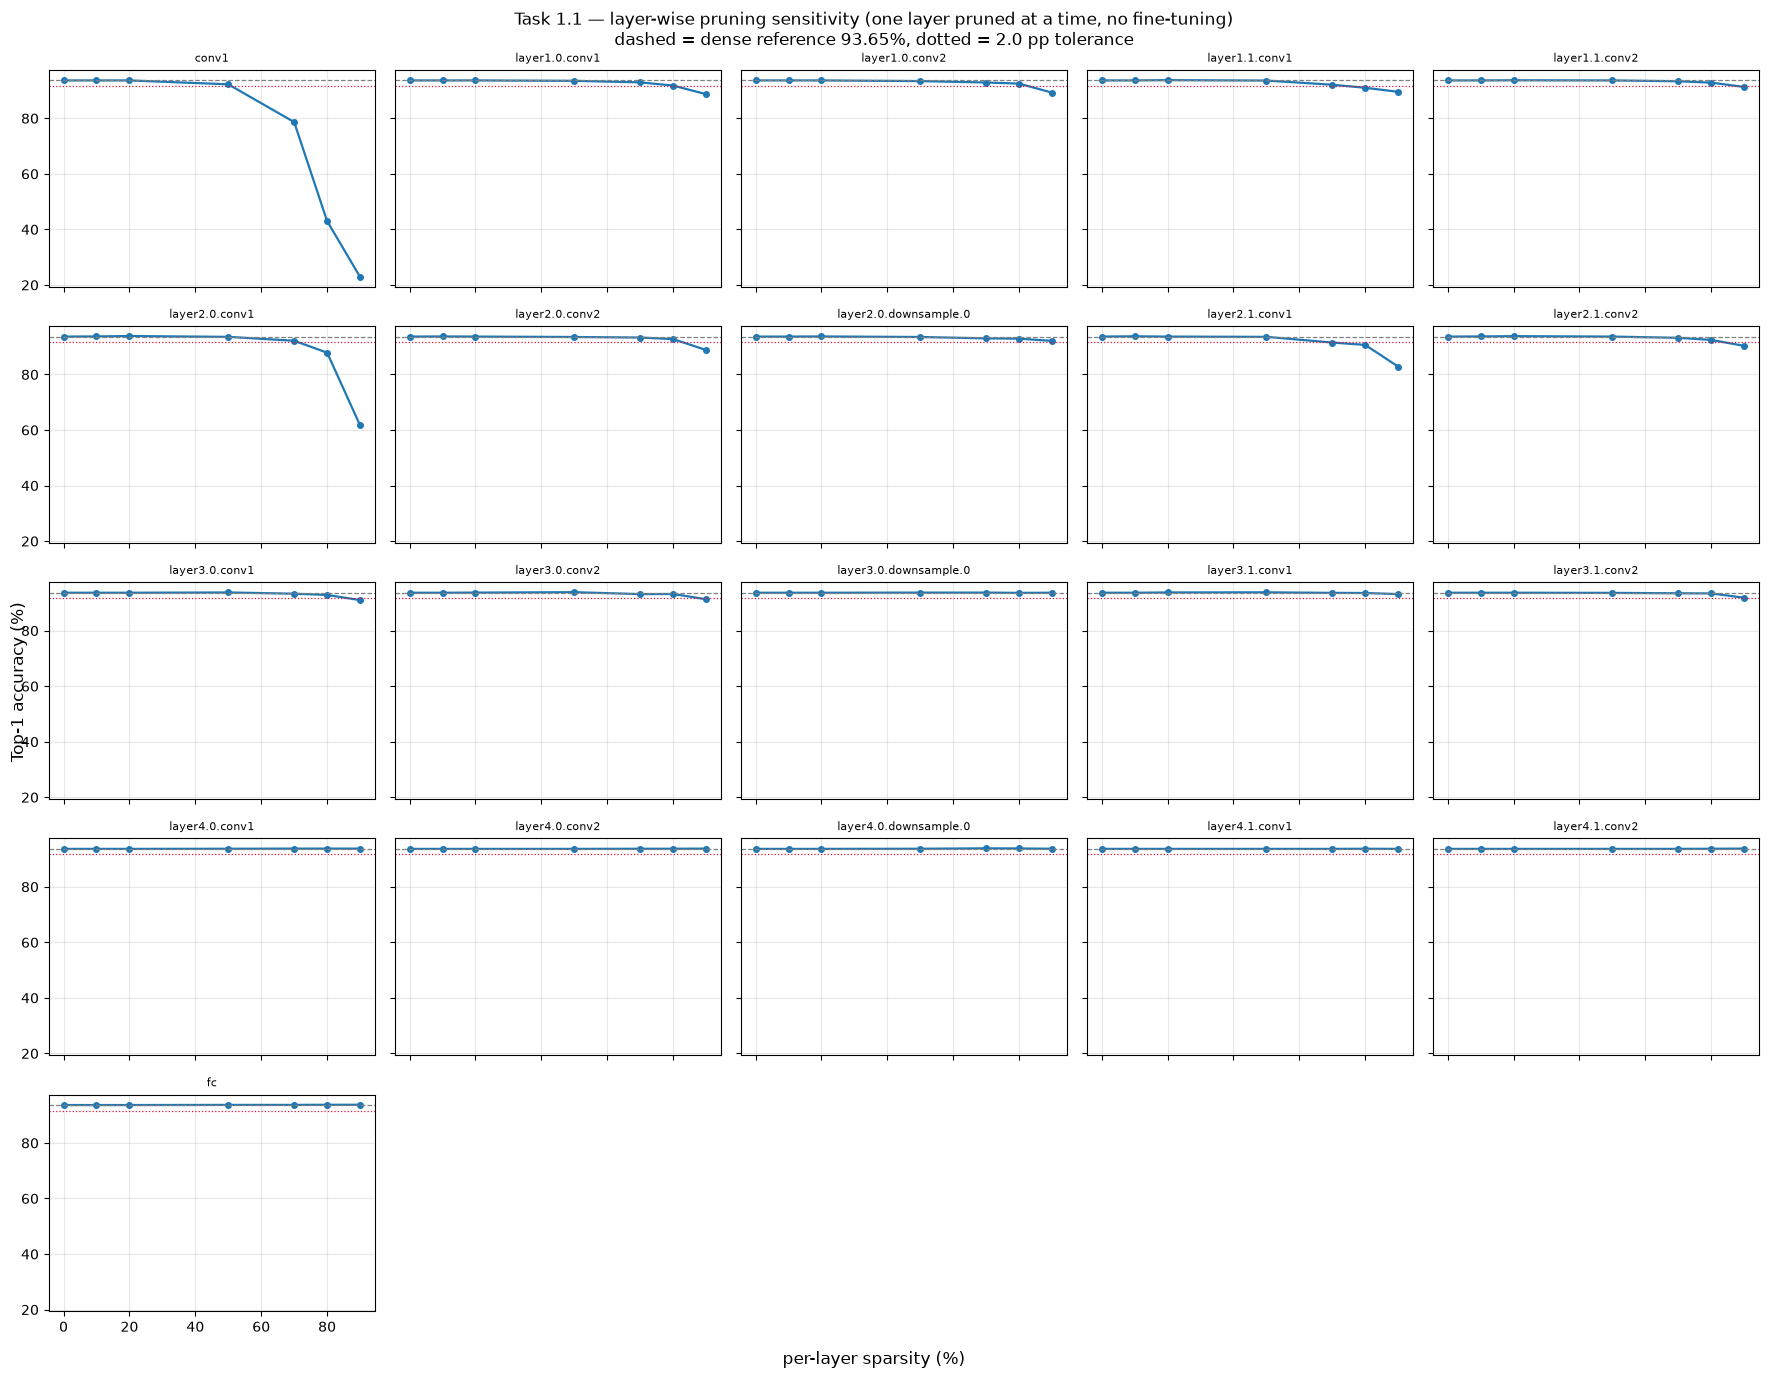

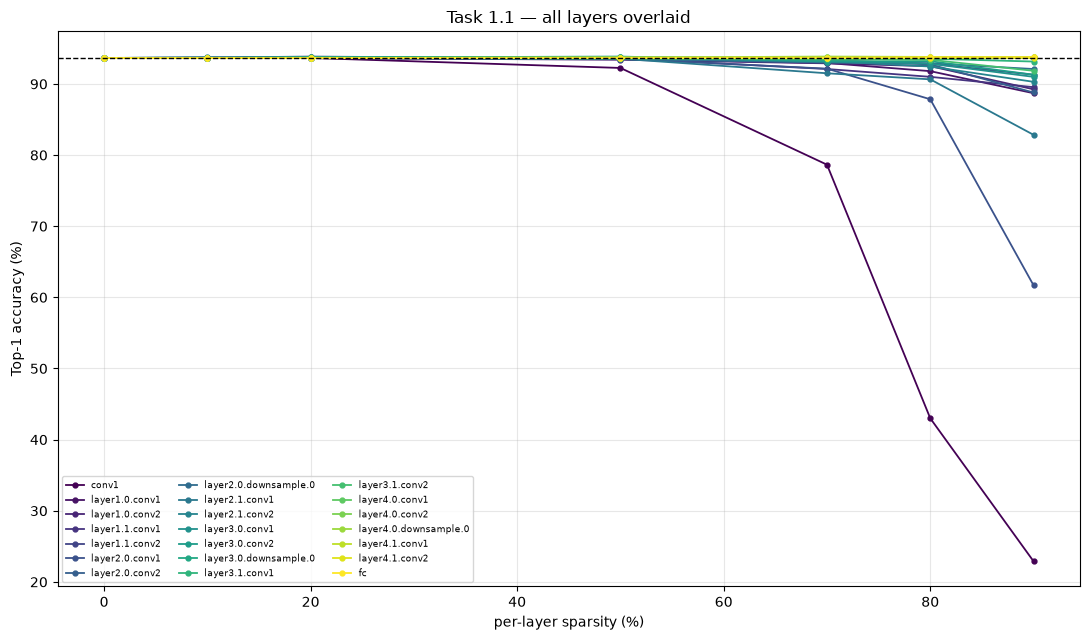

### Task 1.1 — accuracy drop (pp) at 90% single-layer sparsity, most sensitive first

| layer                 |   Top-1 drop (pp) |
|:----------------------|------------------:|
| conv1                 |             70.75 |
| layer2.0.conv1        |             31.95 |
| layer2.1.conv1        |             10.80 |
| layer1.0.conv1        |              4.95 |
| layer2.0.conv2        |              4.85 |
| layer1.0.conv2        |              4.40 |
| layer1.1.conv1        |              4.10 |
| layer2.1.conv2        |              3.35 |
| layer3.0.conv1        |              2.65 |
| layer1.1.conv2        |              2.35 |
| layer3.0.conv2        |              2.35 |
| layer3.1.conv2        |              1.80 |
| layer2.0.downsample.0 |              1.55 |
| layer3.1.conv1        |              0.50 |
| layer3.0.downsample.0 |              0.00 |
| layer4.1.conv1        |              0.00 |
| layer4.0.downsample.0 |             -0.05 |
| layer4.0.conv1        |             -0

,Top-1 drop (pp)
layer,
conv1,70.75
layer2.0.conv1,31.95
layer2.1.conv1,10.80
layer1.0.conv1,4.95
layer2.0.conv2,4.85
layer1.0.conv2,4.40
layer1.1.conv1,4.10
layer2.1.conv2,3.35
layer3.0.conv1,2.65


In [14]:
# --- sensitivity plots -------------------------------------------------------------
layers = list(sens_pivot.index)
levels = list(sens_pivot.columns)

fig, axes = plt.subplots(5, 5, figsize=(18, 14), sharex=True, sharey=True)
for ax, layer in zip(axes.ravel(), layers):
    y = sens_pivot.loc[layer].values
    ax.plot([100 * l for l in levels], y, "o-", lw=1.6, ms=4)
    ax.axhline(dense_ref_top1, color="grey", ls="--", lw=0.9)
    ax.axhline(dense_ref_top1 - SENS_TOLERANCE_PP, color="crimson", ls=":", lw=0.9)
    ax.set_title(layer, fontsize=8)
    ax.grid(alpha=0.3)
for ax in axes.ravel()[len(layers):]:
    ax.axis("off")
fig.suptitle("Task 1.1 — layer-wise pruning sensitivity (one layer pruned at a time, "
             f"no fine-tuning)\ndashed = dense reference {dense_ref_top1:.2f}%, "
             f"dotted = {SENS_TOLERANCE_PP} pp tolerance", fontsize=12)
fig.supxlabel("per-layer sparsity (%)")
fig.supylabel("Top-1 accuracy (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "task1_sensitivity_grid.png", dpi=140, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(11, 6.5))
colors = plt.cm.viridis(np.linspace(0, 1, len(layers)))
for i, layer in enumerate(layers):
    ax.plot([100 * l for l in levels], sens_pivot.loc[layer].values, "o-",
            color=colors[i], lw=1.3, ms=3.5, label=layer)
ax.axhline(dense_ref_top1, color="k", ls="--", lw=1)
ax.set(xlabel="per-layer sparsity (%)", ylabel="Top-1 accuracy (%)",
       title="Task 1.1 — all layers overlaid")
ax.grid(alpha=0.3)
ax.legend(fontsize=6.5, ncol=3, loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "task1_sensitivity_overlay.png", dpi=140, bbox_inches="tight")
plt.show()

# rank layers by the accuracy lost at 90% sparsity
drop90 = (dense_ref_top1 - sens_pivot[0.90]).sort_values(ascending=False)
show_table("Task 1.1 — accuracy drop (pp) at 90% single-layer sparsity, most sensitive first",
           drop90.to_frame("Top-1 drop (pp)"), floatfmt=".2f")

## 1.2 Local magnitude pruning

* Each layer gets a tolerable sparsity $a_\ell$: the highest tested level with at most a 2 pp drop.
* One scale factor $\alpha$, found by bisection, makes the overall sparsity exactly $s^\star$:

$$r_\ell = \mathrm{clip}(\alpha\, a_\ell,\; 0.05,\; 0.95), \qquad \frac{\sum_\ell r_\ell N_\ell}{\sum_\ell N_\ell} = s^\star .$$

* Sensitive layers are pruned less; no layer is pruned above 95 %.
* In each layer, the $r_\ell$ fraction of smallest weights is removed.

In [15]:
def tolerable_sparsity(sens_pivot, reference_top1, tolerance_pp=SENS_TOLERANCE_PP):
    out = OrderedDict()
    for layer, row in sens_pivot.iterrows():
        ok = [s for s in row.index if reference_top1 - row[s] <= tolerance_pp]
        out[layer] = max(ok) if ok else 0.0
    return out


def scale_ratios_to_target(allowable, sizes, target, lo=MIN_LAYER_SPARSITY, hi=MAX_LAYER_SPARSITY):
    total = sum(sizes.values())

    def ratios_for(alpha):
        return OrderedDict(
            (l, float(np.clip(alpha * max(allowable[l], lo), lo, hi))) for l in sizes)

    def overall(alpha):
        r = ratios_for(alpha)
        return sum(r[l] * sizes[l] for l in sizes) / total

    if overall(1e6) < target - 1e-6:
        raise ValueError(f"target {target:.3f} unreachable with max layer sparsity {hi}")
    a_lo, a_hi = 0.0, 1e6
    for _ in range(200):
        a_mid = 0.5 * (a_lo + a_hi)
        if overall(a_mid) < target:
            a_lo = a_mid
        else:
            a_hi = a_mid
    alpha = 0.5 * (a_lo + a_hi)
    return ratios_for(alpha), alpha, overall(alpha)


sizes = eligible_sizes(dense_model)
allowable = tolerable_sparsity(sens_pivot, dense_ref_top1)
LOCAL_RATIOS, alpha, achieved = scale_ratios_to_target(allowable, sizes, TARGET_SPARSITY)
print(f"scale factor alpha = {alpha:.4f}  ->  overall sparsity {achieved:.4%} "
      f"(target {TARGET_SPARSITY:.2%})")

ratio_df = pd.DataFrame({
    "params": pd.Series(sizes),
    "tolerable (sweep)": pd.Series(allowable),
    "local ratio r_l": pd.Series(LOCAL_RATIOS),
})
ratio_df["weights pruned"] = (ratio_df["params"] * ratio_df["local ratio r_l"]).round().astype(int)
show_table("Task 1.2 — per-layer sparsity chosen for local pruning", ratio_df, floatfmt=".4g")

# build the locally pruned model
local_model = resnet18_cifar(pretrained=True, verbose=False)
LOCAL_MASKS = local_magnitude_masks(local_model, LOCAL_RATIOS)
apply_masks(local_model, LOCAL_MASKS)
ok, local_sp_df, local_overall = verify_masks(local_model, LOCAL_MASKS, tag="local, pre-FT")
OVERALL_SPARSITY = local_overall["overall_sparsity_mask"]
print(f"\nlocal pruning overall sparsity: {OVERALL_SPARSITY:.4%}  "
      f"(this exact value is reused for global pruning)")

scale factor alpha = 0.9079  ->  overall sparsity 80.0000% (target 80.00%)
### Task 1.2 — per-layer sparsity chosen for local pruning

|                       |       params |   tolerable (sweep) |   local ratio r_l |   weights pruned |
|:----------------------|-------------:|--------------------:|------------------:|-----------------:|
| conv1                 | 1728         |                 0.5 |            0.454  |      784         |
| layer1.0.conv1        |    3.686e+04 |                 0.8 |            0.7264 |        2.678e+04 |
| layer1.0.conv2        |    3.686e+04 |                 0.8 |            0.7264 |        2.678e+04 |
| layer1.1.conv1        |    3.686e+04 |                 0.7 |            0.6356 |        2.343e+04 |
| layer1.1.conv2        |    3.686e+04 |                 0.8 |            0.7264 |        2.678e+04 |
| layer2.0.conv1        |    7.373e+04 |                 0.7 |            0.6356 |        4.686e+04 |
| layer2.0.conv2        |    1.475e+05 |         

## 1.3 Global magnitude pruning

* One magnitude threshold for all layers, set so the overall sparsity is also 80 %.
* Per layer sparsity is not chosen; it is measured afterwards.

[verify global, pre-FT] masked positions exactly zero: PASS | overall sparsity mask 80.0000% vs measured 80.0000% | max per-layer |mask - measured| = 5.55e-17 | min layer density 0.0059

layers completely pruned by global thresholding: none (requirement satisfied)
### Task 1.3 — sparsity allocation at the same overall sparsity (80.00%): local (chosen) vs global (emergent)

|                       |       params |   local sparsity |   global sparsity |   tolerable (sweep) |   global - local (pp) |
|:----------------------|-------------:|-----------------:|------------------:|--------------------:|----------------------:|
| conv1                 | 1728         |           0.454  |          0.1701   |                 0.5 |               -28.38  |
| layer1.0.conv1        |    3.686e+04 |           0.7264 |          0.2692   |                 0.8 |               -45.72  |
| layer1.0.conv2        |    3.686e+04 |           0.7264 |          0.1076   |                 0.8 |               -61.

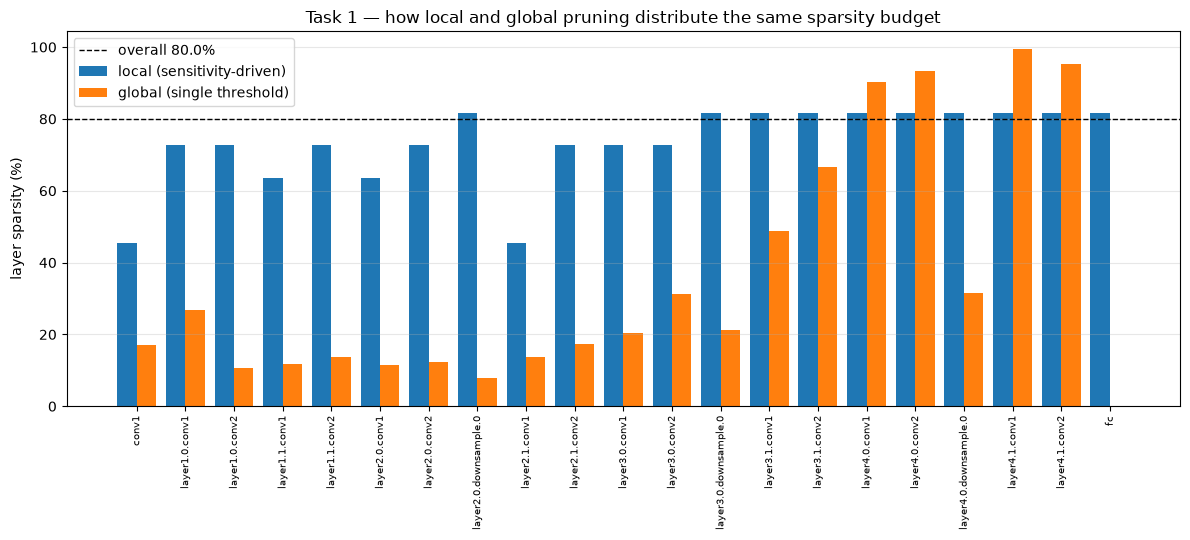

In [16]:
global_model = resnet18_cifar(pretrained=True, verbose=False)
GLOBAL_MASKS = global_magnitude_masks(global_model, OVERALL_SPARSITY)
apply_masks(global_model, GLOBAL_MASKS)
ok_g, global_sp_df, global_overall = verify_masks(global_model, GLOBAL_MASKS,
                                                  tag="global, pre-FT")

collapsed = [n for n, m in GLOBAL_MASKS.items() if int(m.sum().item()) == 0]
print(f"\nlayers completely pruned by global thresholding: "
      f"{collapsed if collapsed else 'none (requirement satisfied)'}")

alloc = pd.DataFrame({
    "params": pd.Series(sizes),
    "local sparsity": pd.Series(LOCAL_RATIOS),
    "global sparsity": global_sp_df["sparsity_mask"],
    "tolerable (sweep)": pd.Series(allowable),
})
alloc["global - local (pp)"] = 100 * (alloc["global sparsity"] - alloc["local sparsity"])
show_table(f"Task 1.3 — sparsity allocation at the same overall sparsity "
           f"({OVERALL_SPARSITY:.2%}): local (chosen) vs global (emergent)",
           alloc, floatfmt=".4g")

fig, ax = plt.subplots(figsize=(12, 5.5))
xs = np.arange(len(alloc))
ax.bar(xs - 0.2, 100 * alloc["local sparsity"], 0.4, label="local (sensitivity-driven)")
ax.bar(xs + 0.2, 100 * alloc["global sparsity"], 0.4, label="global (single threshold)")
ax.axhline(100 * OVERALL_SPARSITY, color="k", ls="--", lw=1,
           label=f"overall {OVERALL_SPARSITY:.1%}")
ax.set_xticks(xs)
ax.set_xticklabels(alloc.index, rotation=90, fontsize=7)
ax.set(ylabel="layer sparsity (%)",
       title="Task 1 — how local and global pruning distribute the same sparsity budget")
ax.legend()
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(FIG_DIR / "task1_sparsity_allocation.png", dpi=140, bbox_inches="tight")
plt.show()

### Accuracy right after pruning

Damage done by pruning alone, before any fine tuning.

In [17]:
set_seed()
local_pre, _, _ = evaluate_both(local_model, name="local_prune_preft",
                                label=f"Local prune {OVERALL_SPARSITY:.0%} (no FT)",
                                desc="local pre-FT")
record("local_prune_preft", overall_sparsity=OVERALL_SPARSITY)
global_pre, _, _ = evaluate_both(global_model, name="global_prune_preft",
                                 label=f"Global prune {OVERALL_SPARSITY:.0%} (no FT)",
                                 desc="global pre-FT")
record("global_prune_preft", overall_sparsity=OVERALL_SPARSITY)

base_top1 = RESULTS[BASELINE]["test_top1"]
print(f"\ndense baseline test Top-1      : {base_top1:.2f}%")
print(f"local  pruned, no fine-tuning  : {local_pre['test_top1']:.2f}%  "
      f"({local_pre['test_top1'] - base_top1:+.2f} pp)")
print(f"global pruned, no fine-tuning  : {global_pre['test_top1']:.2f}%  "
      f"({global_pre['test_top1'] - base_top1:+.2f} pp)")

Local prune 80% (no FT)      train top1  87.21 | test top1  82.42 | test top5  98.66 | macro-F1 0.8274
Global prune 80% (no FT)     train top1  99.85 | test top1  93.11 | test top5  99.75 | macro-F1 0.9312

dense baseline test Top-1      : 93.07%
local  pruned, no fine-tuning  : 82.42%  (-10.65 pp)
global pruned, no fine-tuning  : 93.11%  (+0.04 pp)


## 1.4 Fine tuning

* Same settings for both models: SGD, lr 0.001 with cosine decay, momentum 0.9, weight decay 5e-4, 5 epochs, batch 128, seed 42.
* Each run gets a freshly seeded data loader, so both see exactly the same batches. Only the mask differs.
* After every step the mask is applied again, $W^{(\ell)} \leftarrow M^{(\ell)} \odot W^{(\ell)}$, so pruned weights stay zero.
* lr 0.001 was chosen after an earlier run with 0.01 hurt accuracy (judged on test accuracy).

In [18]:
def finetune(model, enforcer, epochs=FT_EPOCHS, lr=FT_LR, tag="model", seed=SEED,
             momentum=FT_MOMENTUM, weight_decay=FT_WEIGHT_DECAY):
    set_seed(seed)
    loader = make_train_loader(seed)
    model.to(DEVICE).train()
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum,
                          weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(loader))
    crit = nn.CrossEntropyLoss()

    enforcer.reapply()
    hist = {"epoch": [], "train_loss": [], "train_top1": [], "val_loss": [],
            "val_top1": [], "lr": [], "sparsity": []}
    for ep in range(1, epochs + 1):
        model.train()
        run_loss = run_correct = run_n = 0
        bar = tqdm(loader, desc=f"{tag} ep {ep}/{epochs}", leave=False)
        for x, y in bar:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            out = model(x)
            loss = crit(out, y)
            loss.backward()
            opt.step()
            enforcer.reapply()
            sched.step()
            run_loss += loss.item() * y.numel()
            run_correct += (out.argmax(1) == y).sum().item()
            run_n += y.numel()
            bar.set_postfix(loss=f"{run_loss / run_n:.3f}",
                            acc=f"{100 * run_correct / run_n:.2f}")
        val = evaluate(model, test_loader, desc=f"{tag} ep {ep} val")
        _, ov = sparsity_report(model, enforcer.masks)
        hist["epoch"].append(ep)
        hist["train_loss"].append(run_loss / run_n)
        hist["train_top1"].append(100 * run_correct / run_n)
        hist["val_loss"].append(val["loss"])
        hist["val_top1"].append(val["top1"])
        hist["lr"].append(opt.param_groups[0]["lr"])
        hist["sparsity"].append(ov["overall_sparsity_measured"])
        print(f"  {tag} ep {ep}/{epochs}: train loss {hist['train_loss'][-1]:.4f} "
              f"acc {hist['train_top1'][-1]:.2f}% | val loss {val['loss']:.4f} "
              f"top1 {val['top1']:.2f}% | sparsity {hist['sparsity'][-1]:.4%}")
    return hist


local_enforcer = MaskEnforcer(local_model, LOCAL_MASKS)
global_enforcer = MaskEnforcer(global_model, GLOBAL_MASKS)

t0 = time.perf_counter()
local_hist = finetune(local_model, local_enforcer, tag="local")
local_ft_time = time.perf_counter() - t0

t0 = time.perf_counter()
global_hist = finetune(global_model, global_enforcer, tag="global")
global_ft_time = time.perf_counter() - t0

json.dump({"local": local_hist, "global": global_hist,
           "local_ft_seconds": local_ft_time, "global_ft_seconds": global_ft_time},
          open(ART_DIR / "task1_finetune_history.json", "w"), indent=2)
print(f"\nfine-tuning wall time: local {local_ft_time / 60:.1f} min | "
      f"global {global_ft_time / 60:.1f} min")

  local ep 1/5: train loss 0.1881 acc 94.54% | val loss 0.4137 top1 87.80% | sparsity 80.0000%
  local ep 2/5: train loss 0.1437 acc 95.76% | val loss 0.3137 top1 90.68% | sparsity 80.0000%
  local ep 3/5: train loss 0.0965 acc 97.31% | val loss 0.2846 top1 92.17% | sparsity 80.0000%
  local ep 4/5: train loss 0.0684 acc 98.25% | val loss 0.2649 top1 92.49% | sparsity 80.0000%
  local ep 5/5: train loss 0.0531 acc 98.77% | val loss 0.2619 top1 92.52% | sparsity 80.0000%
  global ep 1/5: train loss 0.1995 acc 93.90% | val loss 0.3880 top1 88.49% | sparsity 80.0000%
  global ep 2/5: train loss 0.1614 acc 94.99% | val loss 0.3331 top1 90.31% | sparsity 80.0000%
  global ep 3/5: train loss 0.1045 acc 96.86% | val loss 0.2824 top1 91.55% | sparsity 80.0000%
  global ep 4/5: train loss 0.0645 acc 98.25% | val loss 0.2570 top1 92.60% | sparsity 80.0000%
  global ep 5/5: train loss 0.0492 acc 98.81% | val loss 0.2556 top1 92.80% | sparsity 80.0000%

fine-tuning wall time: local 1.1 min | globa

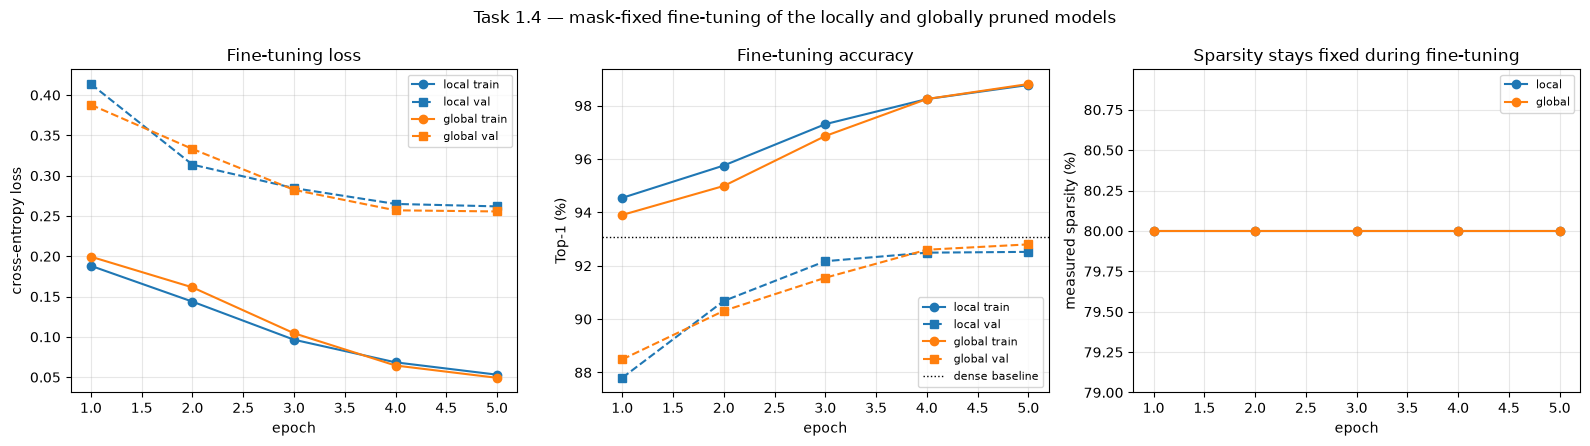

In [19]:
# --- training / validation curves --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for hist, name, c in ((local_hist, "local", "tab:blue"), (global_hist, "global", "tab:orange")):
    axes[0].plot(hist["epoch"], hist["train_loss"], "o-", color=c, label=f"{name} train")
    axes[0].plot(hist["epoch"], hist["val_loss"], "s--", color=c, label=f"{name} val")
    axes[1].plot(hist["epoch"], hist["train_top1"], "o-", color=c, label=f"{name} train")
    axes[1].plot(hist["epoch"], hist["val_top1"], "s--", color=c, label=f"{name} val")
    axes[2].plot(hist["epoch"], [100 * s for s in hist["sparsity"]], "o-", color=c, label=name)
axes[0].set(xlabel="epoch", ylabel="cross-entropy loss", title="Fine-tuning loss")
axes[1].set(xlabel="epoch", ylabel="Top-1 (%)", title="Fine-tuning accuracy")
axes[1].axhline(base_top1, color="k", ls=":", lw=1, label="dense baseline")
axes[2].set(xlabel="epoch", ylabel="measured sparsity (%)",
            title="Sparsity stays fixed during fine-tuning")
axes[2].set_ylim(100 * OVERALL_SPARSITY - 1, 100 * OVERALL_SPARSITY + 1)
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle("Task 1.4 — mask-fixed fine-tuning of the locally and globally pruned models")
fig.tight_layout()
fig.savefig(FIG_DIR / "task1_finetune_curves.png", dpi=140, bbox_inches="tight")
plt.show()

## 1.5 Mask check

For every layer after fine tuning:

1. masked weights are still exactly zero;
2. sparsity from the mask equals sparsity counted in the weights;
3. no layer is completely zero.

In [20]:
ok_l_post, local_sp_post, local_ov_post = verify_masks(local_model, LOCAL_MASKS,
                                                       tag="local, post-FT")
ok_g_post, global_sp_post, global_ov_post = verify_masks(global_model, GLOBAL_MASKS,
                                                         tag="global, post-FT")
assert ok_l_post and ok_g_post, "mask verification failed — pruned weights are not zero"

verify_df = pd.DataFrame({
    "local: mask sparsity": local_sp_post["sparsity_mask"],
    "local: measured": local_sp_post["sparsity_measured"],
    "local: |delta|": local_sp_post["mask_vs_weight_delta"],
    "global: mask sparsity": global_sp_post["sparsity_mask"],
    "global: measured": global_sp_post["sparsity_measured"],
    "global: |delta|": global_sp_post["mask_vs_weight_delta"],
})
show_table("Task 1.5 — mask verification after fine-tuning (mask-derived vs measured sparsity)",
           verify_df, floatfmt=".6f")

torch.save({"model": local_model.state_dict(),
            "masks": {k: v.cpu() for k, v in LOCAL_MASKS.items()},
            "ratios": LOCAL_RATIOS, "overall_sparsity": OVERALL_SPARSITY},
           CKPT_DIR / "task1_local_pruned_ft.pt")
torch.save({"model": global_model.state_dict(),
            "masks": {k: v.cpu() for k, v in GLOBAL_MASKS.items()},
            "overall_sparsity": OVERALL_SPARSITY},
           CKPT_DIR / "task1_global_pruned_ft.pt")
print(f"\nsaved fine-tuned pruned checkpoints to {CKPT_DIR}")

# accuracy after fine-tuning
set_seed()
local_post, _, _ = evaluate_both(local_model, name="local_prune_ft",
                                 label=f"Local prune {OVERALL_SPARSITY:.0%} + FT",
                                 desc="local post-FT")
record("local_prune_ft", overall_sparsity=OVERALL_SPARSITY, finetune_minutes=local_ft_time / 60)
global_post, _, _ = evaluate_both(global_model, name="global_prune_ft",
                                  label=f"Global prune {OVERALL_SPARSITY:.0%} + FT",
                                  desc="global post-FT")
record("global_prune_ft", overall_sparsity=OVERALL_SPARSITY, finetune_minutes=global_ft_time / 60)

[verify local, post-FT] masked positions exactly zero: PASS | overall sparsity mask 80.0000% vs measured 80.0000% | max per-layer |mask - measured| = 0.00e+00 | min layer density 0.1828
[verify global, post-FT] masked positions exactly zero: PASS | overall sparsity mask 80.0000% vs measured 80.0000% | max per-layer |mask - measured| = 5.55e-17 | min layer density 0.0059
### Task 1.5 — mask verification after fine-tuning (mask-derived vs measured sparsity)

| layer                 |   local: mask sparsity |   local: measured |   local: |delta| |   global: mask sparsity |   global: measured |   global: |delta| |
|:----------------------|-----------------------:|------------------:|-----------------:|------------------------:|-------------------:|------------------:|
| conv1                 |               0.453704 |          0.453704 |         0.000000 |                0.170139 |           0.170139 |          0.000000 |
| layer1.0.conv1        |               0.726345 |          0.726345

{'variant': 'global_prune_ft',
 'label': 'Global prune 80% + FT',
 'train_top1': 99.562,
 'train_top5': 99.992,
 'train_macro_f1': 0.9956204295158386,
 'train_loss': 0.024565676305294038,
 'test_top1': 92.8,
 'test_top5': 99.71,
 'test_macro_f1': 0.9280720949172974,
 'test_loss': 0.255601505613327,
 'test_per_class_f1': [0.9318854808807373,
  0.9624060392379761,
  0.9074168801307678,
  0.8447082042694092,
  0.937069833278656,
  0.8758758902549744,
  0.9527162909507751,
  0.9581863880157471,
  0.9583123922348022,
  0.9521435499191284],
 'overall_sparsity': 0.7999998566867115,
 'finetune_minutes': 1.075977746899783}

## 1.6 Sparse storage (COO)

* Pruned weights are saved as COO tensors: nonzero values, indices, shapes and masks. BatchNorm and biases stay dense.
* COO is not always smaller. Dense costs 4 bytes per weight. COO with `int64` indices costs 4 + 4 × 8 = 36 bytes per nonzero for a 4D convolution weight, so it only wins above about 89 % sparsity.
* Reported: theoretical sizes (int64, int32, int16 indices), real file sizes with and without masks, and gzip of the dense checkpoint for comparison.

In [21]:
NON_PRUNABLE_SUFFIXES = ("bias", "running_mean", "running_var", "num_batches_tracked")


def to_coo_checkpoint(model, masks, index_dtype=torch.int64, include_masks=True):
    mods = prunable_modules(model)
    sparse_weights, meta = {}, {}
    for name, mod in mods.items():
        w = mod.weight.detach().cpu()
        sp = w.to_sparse_coo().coalesce()
        sparse_weights[name] = {
            "values": sp.values().clone(),
            "indices": sp.indices().to(index_dtype).clone(),
            "shape": tuple(w.shape),
            "nnz": sp._nnz(),
        }
        meta[name] = {"nnz": sp._nnz(), "numel": w.numel(),
                      "density": sp._nnz() / w.numel()}
    dense_rest = {k: v.detach().cpu() for k, v in model.state_dict().items()
                  if not k.endswith("weight") or k.rsplit(".", 1)[0] not in mods}
    ckpt = {"sparse_weights": sparse_weights, "dense_params": dense_rest,
            "index_dtype": str(index_dtype), "format": "coo"}
    if include_masks:
        ckpt["masks"] = {k: v.detach().cpu() for k, v in masks.items()}
    return ckpt, meta


def coo_payload_bytes(meta, ndim_by_layer, value_bytes=4):
    out = {}
    for idx_bytes, key in ((8, "int64"), (4, "int32"), (2, "int16")):
        total = sum(m["nnz"] * (value_bytes + ndim_by_layer[n] * idx_bytes)
                    for n, m in meta.items())
        out[f"coo_payload_{key}_mb"] = total / 1024 ** 2
    out["dense_payload_mb"] = sum(m["numel"] * value_bytes for m in meta.values()) / 1024 ** 2
    out["nnz_total"] = sum(m["nnz"] for m in meta.values())
    return out


def sparse_storage_report(model, masks, tag):
    mods = prunable_modules(model)
    ndim = {n: m.weight.dim() for n, m in mods.items()}

    dense_path = CKPT_DIR / f"task1_{tag}_dense.pt"
    torch.save(model.state_dict(), dense_path)

    ckpt64, meta = to_coo_checkpoint(model, masks, torch.int64, include_masks=True)
    p64 = CKPT_DIR / f"task1_{tag}_coo_int64.pt"
    torch.save(ckpt64, p64)

    ckpt64_nm, _ = to_coo_checkpoint(model, masks, torch.int64, include_masks=False)
    p64_nm = CKPT_DIR / f"task1_{tag}_coo_int64_nomask.pt"
    torch.save(ckpt64_nm, p64_nm)

    ckpt32, _ = to_coo_checkpoint(model, masks, torch.int32, include_masks=False)
    p32 = CKPT_DIR / f"task1_{tag}_coo_int32_nomask.pt"
    torch.save(ckpt32, p32)

    gz = serialized_size_mb(model.state_dict(), gzip_too=True)
    theory = coo_payload_bytes(meta, ndim)

    row = {
        "dense .pt (MiB)": dense_path.stat().st_size / 1024 ** 2,
        "dense .pt gzip (MiB)": gz["size_gzip_mb"],
        "COO int64 + masks (MiB)": p64.stat().st_size / 1024 ** 2,
        "COO int64 no masks (MiB)": p64_nm.stat().st_size / 1024 ** 2,
        "COO int32 no masks (MiB)": p32.stat().st_size / 1024 ** 2,
        "theory: dense payload (MiB)": theory["dense_payload_mb"],
        "theory: COO int64 (MiB)": theory["coo_payload_int64_mb"],
        "theory: COO int32 (MiB)": theory["coo_payload_int32_mb"],
        "theory: COO int16 (MiB)": theory["coo_payload_int16_mb"],
        "nonzeros": theory["nnz_total"],
    }
    return row, meta, ckpt64


local_store, local_meta, local_coo = sparse_storage_report(local_model, LOCAL_MASKS, "local")
global_store, global_meta, global_coo = sparse_storage_report(global_model, GLOBAL_MASKS, "global")
store_df = pd.DataFrame({"local + FT": local_store, "global + FT": global_store})
show_table("Task 1.6 — storage: dense vs COO sparse checkpoints", store_df, floatfmt=".4g")

record("local_prune_ft", size_sparse_mb=local_store["COO int32 no masks (MiB)"])
record("global_prune_ft", size_sparse_mb=global_store["COO int32 no masks (MiB)"])

# break-even sparsity for COO on tensors of each rank
be = pd.DataFrame([
    {"tensor rank": d, "bytes/nonzero (int64 COO)": 4 + 8 * d,
     "break-even sparsity": 1 - 4 / (4 + 8 * d),
     "bytes/nonzero (int32 COO)": 4 + 4 * d,
     "break-even sparsity (int32)": 1 - 4 / (4 + 4 * d)}
    for d in (2, 4)
]).set_index("tensor rank")
show_table("Task 1.6 — when does COO actually beat dense fp32 storage?", be, floatfmt=".4g")

### Task 1.6 — storage: dense vs COO sparse checkpoints

|                             |   local + FT |   global + FT |
|:----------------------------|-------------:|--------------:|
| dense .pt (MiB)             |   42.7       |    42.7       |
| dense .pt gzip (MiB)        |   10.6       |     9.875     |
| COO int64 + masks (MiB)     |   87.41      |    87.35      |
| COO int64 no masks (MiB)    |   76.76      |    76.7       |
| COO int32 no masks (MiB)    |   42.7       |    42.67      |
| theory: dense payload (MiB) |   42.59      |    42.59      |
| theory: COO int64 (MiB)     |   76.65      |    76.58      |
| theory: COO int32 (MiB)     |   42.58      |    42.55      |
| theory: COO int16 (MiB)     |   25.55      |    25.53      |
| nonzeros                    |    2.233e+06 |     2.233e+06 |
### Task 1.6 — when does COO actually beat dense fp32 storage?

|   tensor rank |   bytes/nonzero (int64 COO) |   break-even sparsity |   bytes/nonzero (int32 COO) |   break-even sparsity

,bytes/nonzero (int64 COO),break-even sparsity,bytes/nonzero (int32 COO),break-even sparsity (int32)
tensor rank,,,,
2,20,0.800000,12,0.666667
4,36,0.888889,20,0.800000


## 1.7 Sparse inference

Both versions are profiled like Task 0:

* **dense masked:** normal layers whose weights contain zeros;
* **COO:** weights stored as COO tensors.

PyTorch has no COO convolution, so `SparseCOOConv2d` calls `.to_dense()` and then the normal `F.conv2d`. Only `fc` runs a real sparse matmul (`torch.sparse.mm`).

In [22]:
class SparseCOOConv2d(nn.Module):
    def __init__(self, conv):
        super().__init__()
        w = conv.weight.detach()
        self.register_buffer("w_sparse", w.to_sparse_coo().coalesce())
        self.bias = None if conv.bias is None else nn.Parameter(conv.bias.detach().clone())
        self.stride, self.padding = conv.stride, conv.padding
        self.dilation, self.groups = conv.dilation, conv.groups
        self.densify_calls = 0

    def forward(self, x):
        w = self.w_sparse.to_dense()
        return F.conv2d(x, w, self.bias, self.stride, self.padding, self.dilation, self.groups)


class SparseCOOLinear(nn.Module):
    def __init__(self, lin):
        super().__init__()
        self.register_buffer("w_sparse", lin.weight.detach().to_sparse_coo().coalesce())
        self.bias = None if lin.bias is None else nn.Parameter(lin.bias.detach().clone())

    def forward(self, x):
        y = torch.sparse.mm(self.w_sparse, x.t().contiguous()).t()
        return y if self.bias is None else y + self.bias


def to_sparse_coo_model(model):
    sparse = copy.deepcopy(model).to(DEVICE).eval()
    for name, mod in list(prunable_modules(sparse).items()):
        parent = sparse if "." not in name else sparse.get_submodule(name.rsplit(".", 1)[0])
        attr = name.rsplit(".", 1)[-1]
        repl = (SparseCOOConv2d(mod) if isinstance(mod, nn.Conv2d) else SparseCOOLinear(mod))
        setattr(parent, attr, repl.to(DEVICE))
    return sparse


local_sparse = to_sparse_coo_model(local_model)
global_sparse = to_sparse_coo_model(global_model)

# equivalence check: the COO model must produce the same logits as the dense masked one
with torch.no_grad():
    xs = torch.randn(8, 3, 32, 32, device=DEVICE)
    d_out = local_model.eval()(xs)
    s_out = local_sparse(xs)
    print(f"dense-masked vs COO logits: max |diff| = "
          f"{(d_out - s_out).abs().max().item():.3e}  (float32 round-off)")

# profile every Task 1 variant with the Task 0 procedure
print()
profile_model(local_model, name="local_prune_ft", label=f"Local {OVERALL_SPARSITY:.0%} + FT (dense masked)")
profile_model(global_model, name="global_prune_ft", label=f"Global {OVERALL_SPARSITY:.0%} + FT (dense masked)")
profile_model(local_sparse, name="local_prune_ft_coo", label=f"Local {OVERALL_SPARSITY:.0%} + FT (COO)")
profile_model(global_sparse, name="global_prune_ft_coo", label=f"Global {OVERALL_SPARSITY:.0%} + FT (COO)")

for coo_name, src, store in (("local_prune_ft_coo", "local_prune_ft", local_store),
                             ("global_prune_ft_coo", "global_prune_ft", global_store)):
    record(coo_name, overall_sparsity=OVERALL_SPARSITY,
           size_dense_mb=store["dense .pt (MiB)"],
           size_sparse_mb=store["COO int32 no masks (MiB)"],
           **{k: RESULTS[src][k] for k in
              ("train_top1", "test_top1", "train_top5", "test_top5",
               "test_macro_f1", "train_macro_f1")})

# sparsity/size fields for the pre-FT
for n, mdl, masks in (("local_prune_preft", local_model, LOCAL_MASKS),
                      ("global_prune_preft", global_model, GLOBAL_MASKS)):
    record(n, overall_sparsity=OVERALL_SPARSITY)

dense-masked vs COO logits: max |diff| = 9.537e-07  (float32 round-off)

Local 80% + FT (dense masked) lat    6.63 +- 0.14 ms/batch (  51.8 us/img) | peak    64.0 MiB | GPU 423.47 J | CPU 114.75 J
Global 80% + FT (dense masked) lat    6.63 +- 0.16 ms/batch (  51.8 us/img) | peak    64.0 MiB | GPU 427.57 J | CPU 107.10 J
Local 80% + FT (COO)         lat    7.32 +- 0.16 ms/batch (  57.2 us/img) | peak    64.0 MiB | GPU 460.88 J | CPU 123.74 J
Global 80% + FT (COO)        lat    7.27 +- 0.15 ms/batch (  56.8 us/img) | peak    64.0 MiB | GPU 466.24 J | CPU 124.56 J


## Task 1 — results

Dense baseline, local and global pruning, dense masked and COO inference, all at 80 % sparsity.

* *COO int32 size, no masks* is the smallest COO file. The required format (COO `int64` + masks) is about 87.4 MiB; the COO models timed here use `int64` indices.
* *Params* is the allocated parameter count, which unstructured pruning does not change; *Params (nonzero)* is what it reduces.

### Task 1 — master comparison at 80.00% overall sparsity

|                                |   Sparsity |   Train Top-1 |   Test Top-1 |   Train Top-5 |   Test Top-5 |   Macro-F1 |      Params |   Params (nonzero) |   Dense size (MiB) |   COO int32 size, no masks (MiB) |        MACs |   MACs (nonzero) |       FLOPs |   Latency (ms/batch) |   Latency (ms/img) |   Peak GPU mem above weights+input (MiB) |   Avg GPU mem above weights+input (MiB) |   Est. total inference GPU mem (MiB) |   GPU energy (J) |   CPU energy (J) |   Energy (mJ/img) |
|:-------------------------------|-----------:|--------------:|-------------:|--------------:|-------------:|-----------:|------------:|-------------------:|-------------------:|---------------------------------:|------------:|-----------------:|------------:|---------------------:|-------------------:|-----------------------------------------:|----------------------------------------:|-------------------------------------:|-----------------:|-------

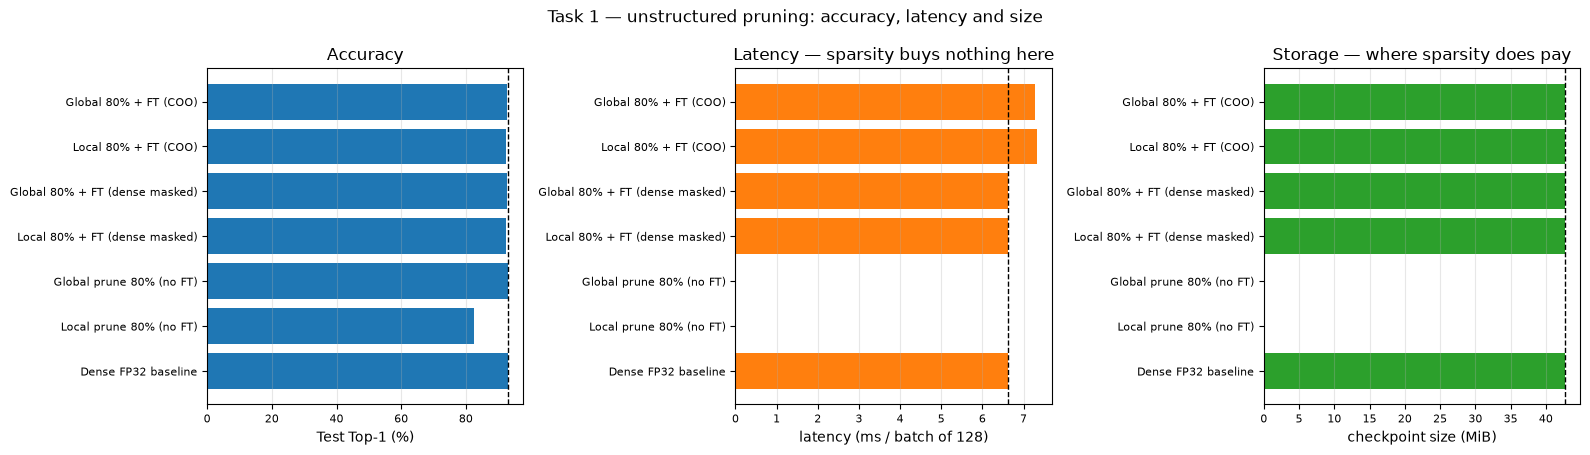

In [23]:
TASK1_VARIANTS = [BASELINE, "local_prune_preft", "global_prune_preft",
                  "local_prune_ft", "global_prune_ft",
                  "local_prune_ft_coo", "global_prune_ft_coo"]
master = results_table(TASK1_VARIANTS)
show_table(f"Task 1 — master comparison at {OVERALL_SPARSITY:.2%} overall sparsity", master)

# accuracy-vs-cost summary in the units the discussion needs
summary = pd.DataFrame({
    "Overall sparsity": [RESULTS[v].get("overall_sparsity") for v in TASK1_VARIANTS],
    "Test Top-1 (%)": [RESULTS[v].get("test_top1") for v in TASK1_VARIANTS],
    "Delta vs dense (pp)": [
        (RESULTS[v].get("test_top1") or float("nan")) - base_top1 for v in TASK1_VARIANTS],
    "Macro-F1": [RESULTS[v].get("test_macro_f1") for v in TASK1_VARIANTS],
    "Latency (ms/batch)": [RESULTS[v].get("latency_ms") for v in TASK1_VARIANTS],
    "Latency vs dense": [
        (RESULTS[v].get("latency_ms") or float("nan")) / RESULTS[BASELINE]["latency_ms"]
        for v in TASK1_VARIANTS],
    "MACs (nonzero) / dense": [
        (RESULTS[v].get("macs_effective") or float("nan"))
        / RESULTS[BASELINE]["macs_dense"] for v in TASK1_VARIANTS],
    "Dense size (MiB)": [RESULTS[v].get("size_dense_mb") for v in TASK1_VARIANTS],
    "COO int32 size, no masks (MiB)": [RESULTS[v].get("size_sparse_mb") for v in TASK1_VARIANTS],
}, index=[RESULTS[v].get("label", v) for v in TASK1_VARIANTS])
show_table("Task 1 — accuracy vs deployment cost", summary, floatfmt=".4g")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
names = [RESULTS[v].get("label", v) for v in TASK1_VARIANTS]
axes[0].barh(names, [RESULTS[v].get("test_top1") or 0 for v in TASK1_VARIANTS],
             color="tab:blue")
axes[0].axvline(base_top1, color="k", ls="--", lw=1)
axes[0].set(xlabel="Test Top-1 (%)", title="Accuracy")
axes[1].barh(names, [RESULTS[v].get("latency_ms") or 0 for v in TASK1_VARIANTS],
             color="tab:orange")
axes[1].axvline(RESULTS[BASELINE]["latency_ms"], color="k", ls="--", lw=1)
axes[1].set(xlabel="latency (ms / batch of 128)", title="Latency — sparsity buys nothing here")
axes[2].barh(names, [(RESULTS[v].get("size_sparse_mb") or RESULTS[v].get("size_dense_mb") or 0)
                     for v in TASK1_VARIANTS], color="tab:green")
axes[2].axvline(RESULTS[BASELINE]["size_dense_mb"], color="k", ls="--", lw=1)
axes[2].set(xlabel="checkpoint size (MiB)", title="Storage — where sparsity does pay")
for ax in axes:
    ax.grid(alpha=0.3, axis="x")
    ax.tick_params(labelsize=8)
fig.suptitle("Task 1 — unstructured pruning: accuracy, latency and size")
fig.tight_layout()
fig.savefig(FIG_DIR / "task1_summary.png", dpi=140, bbox_inches="tight")
plt.show()

In [24]:
# --- numbers quoted in the discussion below ---------------------------------------
disc = {
    "overall_sparsity": OVERALL_SPARSITY,
    "dense_top1": base_top1,
    "most_sensitive_layers": drop90.head(5).round(2).to_dict(),
    "least_sensitive_layers": drop90.tail(5).round(2).to_dict(),
    "local_preft_top1": RESULTS["local_prune_preft"]["test_top1"],
    "global_preft_top1": RESULTS["global_prune_preft"]["test_top1"],
    "local_ft_top1": RESULTS["local_prune_ft"]["test_top1"],
    "global_ft_top1": RESULTS["global_prune_ft"]["test_top1"],
    "local_recovered_pp": RESULTS["local_prune_ft"]["test_top1"] - RESULTS["local_prune_preft"]["test_top1"],
    "global_recovered_pp": RESULTS["global_prune_ft"]["test_top1"] - RESULTS["global_prune_preft"]["test_top1"],
    "global_max_layer_sparsity": float(global_sp_df["sparsity_mask"].max()),
    "global_min_layer_sparsity": float(global_sp_df["sparsity_mask"].min()),
    "global_most_pruned_layer": global_sp_df["sparsity_mask"].idxmax(),
    "global_least_pruned_layer": global_sp_df["sparsity_mask"].idxmin(),
    "dense_ckpt_mb": local_store["dense .pt (MiB)"],
    "coo_int64_mask_mb": local_store["COO int64 + masks (MiB)"],
    "coo_int32_mb": local_store["COO int32 no masks (MiB)"],
    "latency_dense_ms": RESULTS[BASELINE]["latency_ms"],
    "latency_masked_ms": RESULTS["local_prune_ft"]["latency_ms"],
    "latency_coo_ms": RESULTS["local_prune_ft_coo"]["latency_ms"],
    "macs_dense": RESULTS[BASELINE]["macs_dense"],
    "macs_effective_local": RESULTS["local_prune_ft"]["macs_effective"],
}
json.dump(disc, open(ART_DIR / "task1_discussion_numbers.json", "w"), indent=2, default=str)
for k, v in disc.items():
    print(f"{k:28s} {v}")

overall_sparsity             0.7999998566867115
dense_top1                   93.07
most_sensitive_layers        {'conv1': 70.75, 'layer2.0.conv1': 31.95, 'layer2.1.conv1': 10.8, 'layer1.0.conv1': 4.95, 'layer2.0.conv2': 4.85}
least_sensitive_layers       {'layer4.0.downsample.0': -0.05, 'layer4.0.conv1': -0.1, 'layer4.0.conv2': -0.1, 'layer4.1.conv2': -0.1, 'fc': -0.1}
local_preft_top1             82.42
global_preft_top1            93.11
local_ft_top1                92.52
global_ft_top1               92.8
local_recovered_pp           10.099999999999994
global_recovered_pp          -0.3100000000000023
global_max_layer_sparsity    0.9941071404351128
global_min_layer_sparsity    0.0015625000000000222
global_most_pruned_layer     layer4.1.conv1
global_least_pruned_layer    fc
dense_ckpt_mb                42.70163917541504
coo_int64_mask_mb            87.41402626037598
coo_int32_mb                 42.697909355163574
latency_dense_ms             6.6146494534332305
latency_masked_ms          

## Task 1 — discussion

**Most sensitive layers** (Top-1 drop at 90 % single layer sparsity)

* `conv1` −70.75 pp, `layer2.0.conv1` −31.95 pp, `layer2.1.conv1` −10.80 pp, `layer1.0.conv1` −4.95 pp, `layer2.0.conv2` −4.85 pp.
* Least sensitive: the `layer4` convolutions, `fc` and the `layer3`/`layer4` downsample layers, all within 0.1 pp (no measurable loss).
* Likely reason: wide layers have spare capacity (`layer4` has 512 channels for 10 classes), while small early layers such as `conv1` (1,728 weights) have none and feed everything after them.

**Was global pruning's layer distribution reasonable?**

* **For accuracy, yes.** It pruned `conv1` only 17 %, `layer1` 11–27 %, but the `layer4` 3×3 convolutions 90–99 % (`layer4.1.conv1` 99.4 %, `fc` 0.16 %). That matches the sensitivity sweep, which it never saw.
* It reached **93.11 %** with no fine tuning (dense 93.07 %); local pruning reached 82.42 %.
* No layer became empty, but nothing prevents that at higher sparsity.
* **For compute, no:**

| | Effective MACs | Fraction of dense | Top-1 after FT |
|---|---|---|---|
| Dense | 140.2 M | 100 % | 93.07 % |
| Local | **37.8 M** | **27 %** | 92.52 % |
| Global | 82.7 M | 59 % | 92.80 % |

* Global pruning removes weights mostly in `layer4` (few MACs); local pruning also thins earlier layers. Same sparsity, 2.2× fewer effective MACs for local.

**Accuracy recovered by fine tuning**

| | After pruning | After fine tuning | Change |
|---|---|---|---|
| Local | 82.42 % | 92.52 % | **+10.10 pp** |
| Global | 93.11 % | 92.80 % | −0.31 pp |

* Local pruning hurt accuracy and fine tuning recovered nearly all of it (0.55 pp below dense).
* Global pruning did no real damage, so there was nothing to recover; it does not need fine tuning at 80 %.
* With lr 0.01 (archived run, `artifacts/lr0.01_runs/task1_lr0.01/`) global fell to 87.06 %; lr 0.001 avoids this.

**Did COO reduce model size?** No.

* Dense 42.70 MiB; COO `int64` + masks **87.41 MiB** (2× larger); COO `int32` without masks 42.70 MiB (same).
* `int64` COO needs more than 88.9 % sparsity to win; `int32` breaks even at exactly 80 %. The masks alone add about 11 MiB.
* gzip of the dense checkpoint gives 10.60 MiB (local) and 9.88 MiB (global), about 4× smaller than COO `int32`.

**Why zeros do not speed things up**

* Measured: dense **6.61 ms**, dense masked **6.63 ms**, COO **7.32 ms** per batch, although effective MACs fell from 140.2 M to 37.8 M.
* The dense cuDNN kernel multiplies every weight; a zero costs the same as any number.
* Scattered zeros give the GPU no block of work to skip. It needs structure (2:4 sparsity, or whole channels as in Task 3).
* COO is **1.11× slower**: each forward pass runs `to_dense()` and then the same dense convolution. It also holds 76.7 MiB of weights on the GPU instead of 42.7 MiB.

**Measurement noise**

* The unchanged dense model varied 6.61–6.72 ms and 8.45–9.13 mJ per image across five runs (about 2 % and 8 %). So the COO slowdown is real; the small latency and energy differences between dense and masked are not.
* Accuracy varied up to 0.8 pp across development runs that also changed code, so that is not a noise level. Gaps of a few tenths of a point (local vs global, 0.28 pp) cannot rank the methods.

**Summary:** unstructured pruning reduces nonzero weights and, with a good format, storage. It does not reduce latency.

---
## End of Task 1

| Path | Contents |
|---|---|
| `artifacts/results.json` | all metrics |
| `artifacts/report_tables.md` | all tables |
| `artifacts/task1_sensitivity.csv` | sensitivity sweep (cached) |
| `artifacts/task1_finetune_history.json` | fine tuning curves |
| `artifacts/task1_discussion_numbers.json` | numbers used in the discussion |
| `artifacts/figures/*.png` | figures |
| `checkpoints/task1_*` | pruned models, masks, COO files |

---
# Task 2 — Iterative Pruning During Training (GraSP)

* Start from **random weights** and prune gradually while training.
* Magnitude pruning removes small weights. GraSP removes the weights whose removal hurts gradient flow least.

**Score.** With $\mathbf g = \nabla_\theta \mathcal L$ (gradient of the average calibration loss) and $\mathbf{Hg} = \nabla^2_\theta \mathcal L\, \mathbf g$, removing weights by $\boldsymbol\delta$ changes gradient flow to first order by

$$\Delta \lVert \nabla \mathcal L \rVert^2 \approx 2\,\boldsymbol\delta^\top \mathbf{Hg}.$$

Removing weight $i$ means $\delta_i = -\theta_i$, which gives

$$S_i = -\theta_i\,(\mathbf{Hg})_i .$$

* A large positive $S_i$ means removing the weight *increases* gradient flow, so the **highest** $S_i$ are removed (as in the paper's code).
* $\mathbf{Hg}$ is computed with two autograd passes and no Hessian: fix $\mathbf g$, then differentiate $\langle \mathbf g, \nabla_\theta \mathcal L\rangle$.
* At stages 2 and 3, $\mathbf g$ is masked to the surviving weights.

**Schedule**

* Three stages: $s_1 = 0.5 s^\star$, $s_2 = 0.75 s^\star$, $s_3 = s^\star$, triggered at about 20 %, 40 % and 60 % accuracy.
* Masks only grow: $M_{\text{cum},k} = M_{\text{cum},k-1} \odot M_k$.

**Design choices**

* Both methods start from one shared warm up, a copy of the same optimizer state and the same seeded data loader, so they see identical batches.
* Both criteria are applied globally, so the criterion is the only difference.
* Triggers use Top-1 on the fixed 2,000 image test subset, checked every 50 iterations.
* BatchNorm statistics are saved and restored around scoring.

In [25]:
# --- Task 2 configuration ----------------------------------------------------------
TASK2_TARGET_SPARSITY = TARGET_SPARSITY
TASK2_STAGE_FRACTIONS = (0.50, 0.75, 1.00)
TASK2_TRIGGER_ACC = (20.0, 40.0, 60.0)
TASK2_EPOCHS = 40
TASK2_LR = 0.1
TASK2_MOMENTUM = 0.9
TASK2_WEIGHT_DECAY = 5e-4
TASK2_TRIGGER_CHECK_EVERY = 50

# GraSP calibration set
CALIB_PER_CLASS = 10
CALIB_BATCH_SIZE = 50
GRASP_TEMPERATURE = 200.0

TASK2_STAGE_SPARSITIES = tuple(f * TASK2_TARGET_SPARSITY for f in TASK2_STAGE_FRACTIONS)
print(f"target sparsity s*      : {TASK2_TARGET_SPARSITY:.0%}")
print(f"stage sparsities        : "
      + ", ".join(f"s{i+1}={s:.1%}" for i, s in enumerate(TASK2_STAGE_SPARSITIES)))
print(f"trigger accuracies      : {TASK2_TRIGGER_ACC}")
print(f"training budget         : {TASK2_EPOCHS} epochs "
      f"({TASK2_EPOCHS * len(train_loader):,} iterations at batch {TRAIN_BATCH_SIZE})")
print(f"GraSP temperature       : {GRASP_TEMPERATURE}")

target sparsity s*      : 80%
stage sparsities        : s1=40.0%, s2=60.0%, s3=80.0%
trigger accuracies      : (20.0, 40.0, 60.0)
training budget         : 40 epochs (15,640 iterations at batch 128)
GraSP temperature       : 200.0


## 2.1 Calibration set

GraSP scores use a small class balanced subset of the training set (100 images), so no class dominates the gradient.

In [26]:
def build_calibration_batches(per_class=CALIB_PER_CLASS, batch_size=CALIB_BATCH_SIZE,
                              seed=SEED):
    targets = np.array(train_eval_set.targets)
    rng = np.random.RandomState(seed)
    idx = np.concatenate([
        rng.choice(np.where(targets == c)[0], per_class, replace=False)
        for c in range(NUM_CLASSES)
    ])
    rng.shuffle(idx)
    loader = DataLoader(Subset(train_eval_set, idx.tolist()), batch_size=batch_size,
                        shuffle=False, num_workers=2)
    batches = [(x.to(DEVICE), y.to(DEVICE)) for x, y in loader]
    return batches, idx


CALIB_BATCHES, CALIB_IDX = build_calibration_batches()
_calib_labels = torch.cat([y for _, y in CALIB_BATCHES]).cpu().numpy()
CALIB_CONFIG = {
    "calibration_samples": int(sum(y.numel() for _, y in CALIB_BATCHES)),
    "samples_per_class": CALIB_PER_CLASS,
    "calibration_batch_size": CALIB_BATCH_SIZE,
    "number_of_batches": len(CALIB_BATCHES),
    "gradient_combination": "averaged over batches (sum / n_batches) for both g and Hg",
    "class_counts": {CLASSES[c]: int((_calib_labels == c).sum()) for c in range(NUM_CLASSES)},
    "source": "CIFAR-10 training set, evaluation transforms (no augmentation)",
    "logit_temperature": GRASP_TEMPERATURE,
}
(ART_DIR / "task2_calibration_config.json").write_text(json.dumps(CALIB_CONFIG, indent=2))
show_table("Task 2.1 — GraSP calibration set",
           pd.DataFrame({"value": {k: str(v) for k, v in CALIB_CONFIG.items()}}))

### Task 2.1 — GraSP calibration set

|                        | value                                                                                                                    |
|:-----------------------|:-------------------------------------------------------------------------------------------------------------------------|
| calibration_samples    | 100                                                                                                                      |
| samples_per_class      | 10                                                                                                                       |
| calibration_batch_size | 50                                                                                                                       |
| number_of_batches      | 2                                                                                                                        |
| gradient_combination   | averaged over batches (sum / n_batc

,value
calibration_samples,100
samples_per_class,10
calibration_batch_size,50
number_of_batches,2
gradient_combination,averaged over batches (sum / n_batches) for bo...
class_counts,"{'plane': 10, 'car': 10, 'bird': 10, 'cat': 10..."
source,"CIFAR-10 training set, evaluation transforms (..."
logit_temperature,200.0


## 2.2 GraSP scores

`grasp_scores()` returns $S_i$ for every prunable weight using two autograd passes. A mask restricts $\mathbf g$ to surviving weights. The timer covers the whole scoring step with CUDA synchronization.

In [27]:
def _bn_buffer_snapshot(model):
    return {k: v.detach().clone() for k, v in model.state_dict().items()
            if ("running_" in k) or k.endswith("num_batches_tracked")}


@torch.enable_grad()
def grasp_scores(model, calib_batches=None, temperature=GRASP_TEMPERATURE, masks=None):
    calib_batches = calib_batches or CALIB_BATCHES
    mods = prunable_modules(model)
    weights = [m.weight for m in mods.values()]

    snapshot = _bn_buffer_snapshot(model)
    was_training = model.training
    model.train()
    model.zero_grad(set_to_none=True)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    n = len(calib_batches)

    # ---- pass 1: accumulate the (detached) gradient g -----------------------------
    g_acc = [torch.zeros_like(w) for w in weights]
    for x, y in calib_batches:
        loss = F.cross_entropy(model(x) / temperature, y)
        grads = torch.autograd.grad(loss, weights, create_graph=False)
        for acc, gi in zip(g_acc, grads):
            acc.add_(gi.detach())
    g_acc = [a / n for a in g_acc]
    # Later stages: already-pruned weights cannot train again, so the gradient flow that
    # matters is that of the surviving subnetwork. Masking g gives
    # z = <m*g, grad L> and Hg = H (m*g); pruned positions are never re-selected anyway.
    if masks is not None:
        g_acc = [a * masks[name].to(a.dtype) for a, name in zip(g_acc, mods)]

    # ---- pass 2: Hg = d/dtheta <g, grad L> ---------------------------------------
    model.zero_grad(set_to_none=True)
    for x, y in calib_batches:
        loss = F.cross_entropy(model(x) / temperature, y)
        grad_f = torch.autograd.grad(loss, weights, create_graph=True)
        z = sum((gd * gf).sum() for gd, gf in zip(g_acc, grad_f))
        z.backward()

    scores, hg = OrderedDict(), OrderedDict()
    for (name, m), w in zip(mods.items(), weights):
        Hg = (w.grad / n) if w.grad is not None else torch.zeros_like(w)
        Hg = torch.nan_to_num(Hg, nan=0.0, posinf=0.0, neginf=0.0)
        hg[name] = Hg.detach().clone()
        scores[name] = (-(w.detach() * Hg)).detach().clone()
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0

    model.zero_grad(set_to_none=True)
    model.load_state_dict(snapshot, strict=False)
    model.train(was_training)
    return scores, hg, elapsed


@torch.enable_grad()
def gradient_flow_norm(model, batches=None, temperature=GRASP_TEMPERATURE, masks=None):
    # ||g||^2 for the same g that grasp_scores() uses: the gradient of the *average*
    # calibration loss (not the average of per-batch squared norms), restricted to the
    # surviving weights when masks are given.
    batches = batches or CALIB_BATCHES
    mods = prunable_modules(model)
    weights = [m.weight for m in mods.values()]
    snapshot = _bn_buffer_snapshot(model)
    was_training = model.training
    model.train()
    g_acc = [torch.zeros_like(w) for w in weights]
    for x, y in batches:
        loss = F.cross_entropy(model(x) / temperature, y)
        grads = torch.autograd.grad(loss, weights, create_graph=False)
        for acc, gi in zip(g_acc, grads):
            acc.add_(gi.detach())
    g_acc = [a / len(batches) for a in g_acc]
    if masks is not None:
        g_acc = [a * masks[name].to(a.dtype) for a, name in zip(g_acc, mods)]
    total = float(sum((a ** 2).sum().item() for a in g_acc))
    model.load_state_dict(snapshot, strict=False)
    model.train(was_training)
    return total


print("grasp_scores() and gradient_flow_norm() defined.")

grasp_scores() and gradient_flow_norm() defined.


## 2.3 Checking the sign of the score

* **One shot check:** on the warm up model, build both masks at 80 % and measure the gradient flow $\lVert\bar{\mathbf g}\rVert^2$ of the surviving weights.
* **Small perturbation check** (next cells): tests the formula where it should hold.

In [28]:
def verify_grasp_direction(model, target_sparsity=TASK2_TARGET_SPARSITY):
    scores, _, _ = grasp_scores(model)
    mods = prunable_modules(model)
    base = gradient_flow_norm(model)
    originals = {n: m.weight.detach().clone() for n, m in mods.items()}
    ones = OrderedDict((n, torch.ones_like(m.weight, dtype=torch.bool))
                       for n, m in mods.items())
    out = {"dense_grad_flow": base}

    for label, sign in (("prune high S (keep -S largest) [paper]", +1.0),
                        ("prune low S  (keep +S largest) [inverted]", -1.0)):
        importance = OrderedDict((n, sign * (-scores[n])) for n in mods)
        masks, _ = prune_to_target(model, ones, importance, target_sparsity)
        with torch.no_grad():
            for n, m in mods.items():
                m.weight.copy_(originals[n] * masks[n])
        out[label] = gradient_flow_norm(model, masks=masks)
        with torch.no_grad():
            for n, m in mods.items():
                m.weight.copy_(originals[n])
    return out


print("verify_grasp_direction() defined (run after the warm-up).")

verify_grasp_direction() defined (run after the warm-up).


## 2.4 Cumulative pruning

At stage $k$, extra weights are chosen only from the surviving ones until sparsity is exactly $s_k$. Pruned weights get an infinite keep score, so they never come back.

In [29]:
def prune_to_target(model, cum_masks, importance, target_sparsity):
    mods = prunable_modules(model)
    total = sum(m.weight.numel() for m in mods.values())
    want_pruned = int(round(float(target_sparsity) * total))
    already = total - sum(int(mk.sum().item()) for mk in cum_masks.values())
    k = want_pruned - already
    if k <= 0:
        return OrderedDict((n, mk.clone()) for n, mk in cum_masks.items()), {
            "added": 0, "target": target_sparsity, "achieved": already / total}

    flat = []
    for name, m in mods.items():
        imp = torch.nan_to_num(importance[name].detach().flatten().float(),
                               nan=float("inf"), posinf=float("inf"),
                               neginf=float("-inf"))
        # already-pruned positions must never be selected again
        flat.append(imp.masked_fill(~cum_masks[name].flatten(), float("inf")))
    cat = torch.cat(flat)
    kill = cat.argsort()[:k]
    keep = torch.ones(cat.numel(), dtype=torch.bool, device=cat.device)
    keep[kill] = False

    new, off = OrderedDict(), 0
    for name, m in mods.items():
        sz = m.weight.numel()
        new[name] = cum_masks[name] & keep[off:off + sz].view_as(m.weight)
        off += sz
    achieved = 1.0 - sum(int(v.sum().item()) for v in new.values()) / total
    del cat, keep, flat
    return new, {"added": k, "target": target_sparsity, "achieved": achieved}


def magnitude_importance(model, **_):
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    imp = OrderedDict((n, m.weight.detach().abs().clone())
                      for n, m in prunable_modules(model).items())
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return imp, time.perf_counter() - t0


def grasp_importance(model, masks=None, **kw):
    scores, _, elapsed = grasp_scores(model, masks=masks, **kw)
    return OrderedDict((n, -scores[n]) for n in scores), elapsed


CRITERIA = {"iterative_magnitude": magnitude_importance, "iterative_grasp": grasp_importance}
print("criteria:", list(CRITERIA))

criteria: ['iterative_magnitude', 'iterative_grasp']


## 2.5 Warm up from random weights

* `resnet18_cifar(pretrained=False)`. The replaced 3×3 stem uses Kaiming normal (fan out) initialization, as in the reference repository.
* Train until trigger accuracy passes about 20 %, then save weights, optimizer, scheduler and curves. Both methods continue from this state.
* The trigger is checked every 50 iterations, so the warm up can overshoot 20 %.

saved random initialization -> /home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/checkpoints/task2_init.pt


warm-up to ~20%: 150it [00:04, 34.14it/s, acc=26.30%, loss=1.884]



warm-up reached 26.30% after 150 iterations (0.38 epochs) -> /home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/checkpoints/task2_warmup.pt
remaining budget after warm-up: 15,490 iterations


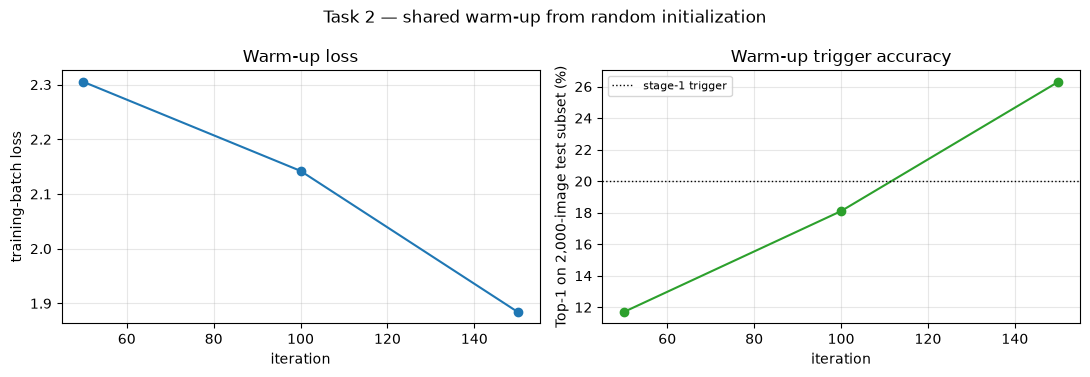

In [30]:
TASK2_TOTAL_ITERS = TASK2_EPOCHS * len(train_loader)
INIT_PATH = CKPT_DIR / "task2_init.pt"
WARMUP_PATH = CKPT_DIR / "task2_warmup.pt"


def make_task2_optimizer(model):
    opt = torch.optim.SGD(model.parameters(), lr=TASK2_LR, momentum=TASK2_MOMENTUM,
                          weight_decay=TASK2_WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=TASK2_TOTAL_ITERS)
    return opt, sched


def run_warmup(trigger_acc=TASK2_TRIGGER_ACC[0], force=False):
    if WARMUP_PATH.exists() and not force:
        ck = torch.load(WARMUP_PATH, map_location="cpu", weights_only=False)
        print(f"loaded cached warm-up: {ck['iters']} iters, "
              f"trigger acc {ck['acc']:.2f}%  ({WARMUP_PATH})")
        return ck

    set_seed()
    model = resnet18_cifar(pretrained=False, verbose=False)
    torch.save(model.state_dict(), INIT_PATH)
    print(f"saved random initialization -> {INIT_PATH}")

    opt, sched = make_task2_optimizer(model)
    crit = nn.CrossEntropyLoss()
    loader = make_train_loader(SEED)
    hist = {"iter": [], "train_loss": [], "trigger_acc": []}
    it, acc = 0, 0.0
    model.train()
    bar = tqdm(desc="warm-up to ~20%", unit="it")
    done = False
    while not done:
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            loss = crit(model(x), y)
            loss.backward()
            opt.step()
            sched.step()
            it += 1
            bar.update(1)
            if it % TASK2_TRIGGER_CHECK_EVERY == 0:
                acc = eval_cached(model)
                model.train()
                hist["iter"].append(it)
                hist["train_loss"].append(loss.item())
                hist["trigger_acc"].append(acc)
                bar.set_postfix(loss=f"{loss.item():.3f}", acc=f"{acc:.2f}%")
                if acc >= trigger_acc:
                    done = True
                    break
    bar.close()

    ck = {"model": model.state_dict(), "optimizer": opt.state_dict(),
          "scheduler": sched.state_dict(), "iters": it, "acc": acc, "history": hist,
          "init_path": str(INIT_PATH)}
    torch.save(ck, WARMUP_PATH)
    print(f"\nwarm-up reached {acc:.2f}% after {it} iterations "
          f"({it / len(train_loader):.2f} epochs) -> {WARMUP_PATH}")
    return ck


WARMUP = run_warmup()
print(f"remaining budget after warm-up: {TASK2_TOTAL_ITERS - WARMUP['iters']:,} iterations")

_wh = WARMUP["history"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(_wh["iter"], _wh["train_loss"], "o-")
axes[0].set(xlabel="iteration", ylabel="training-batch loss", title="Warm-up loss")
axes[1].plot(_wh["iter"], _wh["trigger_acc"], "o-", color="tab:green")
axes[1].axhline(TASK2_TRIGGER_ACC[0], color="k", ls=":", lw=1, label="stage-1 trigger")
axes[1].set(xlabel="iteration", ylabel="Top-1 on 2,000-image test subset (%)",
            title="Warm-up trigger accuracy")
for a in axes:
    a.grid(alpha=0.3)
axes[1].legend(fontsize=8)
fig.suptitle("Task 2 — shared warm-up from random initialization")
fig.tight_layout()
fig.savefig(FIG_DIR / "task2_warmup.png", dpi=140, bbox_inches="tight")
plt.show()

In [31]:
# sanity-check the GraSP sign convention on the warm-up model, before any pruning
_warm = resnet18_cifar(pretrained=False, verbose=False)
_warm.load_state_dict(WARMUP["model"])
DIRECTION_CHECK = verify_grasp_direction(_warm)
_dense = DIRECTION_CHECK.pop("dense_grad_flow")
_dirdf = pd.DataFrame({"||grad L||^2 after pruning": DIRECTION_CHECK})
_dirdf["ratio to dense gradient flow"] = _dirdf["||grad L||^2 after pruning"] / _dense
show_table(f"Task 2.3 — sorting-direction check at {TASK2_TARGET_SPARSITY:.0%} "
           f"(dense ||grad L||^2 = {_dense:.4e})", _dirdf, floatfmt=".4g")
_best = _dirdf["||grad L||^2 after pruning"].idxmax()
print(f"\ndirection preserving the most gradient flow: {_best}")
print("the paper's convention (prune high S) is "
      f"{'CONFIRMED' if 'paper' in _best else 'NOT confirmed — see discussion'}")
del _warm

### Task 2.3 — sorting-direction check at 80% (dense ||grad L||^2 = 4.3996e-05)

|                                           |   ||grad L||^2 after pruning |   ratio to dense gradient flow |
|:------------------------------------------|-----------------------------:|-------------------------------:|
| prune high S (keep -S largest) [paper]    |                    0.0001242 |                         2.823  |
| prune low S  (keep +S largest) [inverted] |                    1.674e-05 |                         0.3804 |

direction preserving the most gradient flow: prune high S (keep -S largest) [paper]
the paper's convention (prune high S) is CONFIRMED


### Small perturbation check

* Take the 1 % of weights with the highest $S_i$ and, separately, the 1 % with the lowest.
* Shrink only those weights by a small factor $\varepsilon$ ($\delta_i = -\varepsilon\,\theta_i$).
* Compare the actual change in $G = \lVert\bar{\mathbf g}\rVert^2$ with the first order prediction

$$\Delta G_{\text{pred}} = 2\,\varepsilon \sum_{i\in P} S_i .$$

* If the score and its sign are right, actual / predicted should approach 1 for small $\varepsilon$, and shrinking high $S$ weights should increase $G$.

In [32]:
def grasp_taylor_check(model, fraction=0.01, eps_values=(1e-3, 1e-2, 1e-1, 1.0)):
    scores, _, _ = grasp_scores(model)
    mods = prunable_modules(model)
    originals = {n: m.weight.detach().clone() for n, m in mods.items()}
    G0 = gradient_flow_norm(model)
    flat = torch.cat([scores[n].flatten() for n in mods])
    k = max(1, int(fraction * flat.numel()))
    rows = []
    for label, idx in (("highest S (GraSP removes these)", flat.topk(k).indices),
                       ("lowest S", (-flat).topk(k).indices)):
        sel = torch.zeros(flat.numel(), dtype=torch.bool, device=flat.device)
        sel[idx] = True
        sel_masks, off = {}, 0
        for n, m in mods.items():
            sz = m.weight.numel()
            sel_masks[n] = sel[off:off + sz].view_as(m.weight)
            off += sz
        sum_s = float(flat[idx].sum())
        for eps in eps_values:
            with torch.no_grad():
                for n, m in mods.items():
                    m.weight.copy_(originals[n] * (1 - eps * sel_masks[n].to(originals[n].dtype)))
            G = gradient_flow_norm(model)
            pred = 2 * eps * sum_s
            rows.append({"weights changed": label, "epsilon": eps,
                         "predicted dG": pred, "actual dG": G - G0,
                         "actual / predicted": (G - G0) / pred if pred != 0 else float("nan")})
        with torch.no_grad():
            for n, m in mods.items():
                m.weight.copy_(originals[n])
    return G0, rows


_warm = resnet18_cifar(pretrained=False, verbose=False)
_warm.load_state_dict(WARMUP["model"])
_G0, _rows = grasp_taylor_check(_warm)
TAYLOR_CHECK = {"dense_grad_flow": _G0, "rows": _rows}
show_table(f"Task 2.3 — small-perturbation check of the GraSP score, 1% of weights "
           f"(dense ||g||^2 = {_G0:.4e})",
           pd.DataFrame(_rows).set_index(["weights changed", "epsilon"]), floatfmt=".4g")
del _warm

### Task 2.3 — small-perturbation check of the GraSP score, 1% of weights (dense ||g||^2 = 4.3996e-05)

|                                            |   predicted dG |   actual dG |   actual / predicted |
|:-------------------------------------------|---------------:|------------:|---------------------:|
| ('highest S (GraSP removes these)', 0.001) |      1.446e-06 |   2.059e-06 |             1.424    |
| ('highest S (GraSP removes these)', 0.01)  |      1.446e-05 |   1.522e-05 |             1.052    |
| ('highest S (GraSP removes these)', 0.1)   |      0.0001446 |   2.29e-05  |             0.1583   |
| ('highest S (GraSP removes these)', 1.0)   |      0.001446  |  -1.095e-05 |            -0.007573 |
| ('lowest S', 0.001)                        |     -1.474e-06 |  -1.667e-06 |             1.131    |
| ('lowest S', 0.01)                         |     -1.474e-05 |  -1.194e-05 |             0.81     |
| ('lowest S', 0.1)                          |     -0.0001474 |  -2.795e-05 |           

## 2.6 Iterative pruning during training

* After every step the cumulative mask is applied again.
* Every `TASK2_TRIGGER_CHECK_EVERY` iterations the trigger accuracy is checked; when a threshold is passed, the criterion is recomputed on the current weights and the mask is extended.
* Criterion time is recorded separately.

**BatchNorm check.** Accuracy after pruning uses BatchNorm statistics from before pruning. So at every step a *copy* of the model gets fresh BatchNorm statistics (2,560 fixed training images, no gradients) and is evaluated again, before and after pruning. The training run itself is not affected.

In [33]:
# BatchNorm check: accuracy is measured in eval() mode, which uses BN running statistics
# collected before pruning. To see how much of an accuracy drop comes from those stale
# statistics, a *copy* of the model has its BN statistics re-estimated on fixed training
# images and is evaluated again. The copy uses no random numbers, so training is unchanged.
BN_RECAL_IMAGES = 2560


def _make_bn_recal_batches(n=BN_RECAL_IMAGES, batch=EVAL_BATCH_SIZE):
    g = torch.Generator().manual_seed(SEED + 1)
    idx = torch.randperm(len(train_eval_set), generator=g)[:n].tolist()
    loader = DataLoader(Subset(train_eval_set, idx), batch_size=batch, shuffle=False, num_workers=2)
    return [x.to(DEVICE) for x, _ in loader]


BN_RECAL_BATCHES = _make_bn_recal_batches()


@torch.no_grad()
def eval_after_bn_recalibration(model, batches=None):
    batches = batches or BN_RECAL_BATCHES
    m = copy.deepcopy(model)
    for mod in m.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm):
            mod.reset_running_stats()
            mod.momentum = None
    m.train()
    for x in batches:
        m(x)
    acc = eval_cached(m)
    del m
    return acc


def run_iterative_pruning(method, target_sparsity=TASK2_TARGET_SPARSITY,
                          epochs=TASK2_EPOCHS, warmup=None, seed=SEED):
    warmup = warmup or WARMUP
    criterion = CRITERIA[method]

    model = resnet18_cifar(pretrained=False, verbose=False)
    model.load_state_dict(warmup["model"])
    opt, sched = make_task2_optimizer(model)
    opt.load_state_dict(copy.deepcopy(warmup["optimizer"]))
    sched.load_state_dict(warmup["scheduler"])
    crit = nn.CrossEntropyLoss()
    set_seed(seed)
    loader = make_train_loader(seed)

    mods = prunable_modules(model)
    cum_masks = OrderedDict((n, torch.ones_like(m.weight, dtype=torch.bool))
                            for n, m in mods.items())
    enforcer = None
    stage = 0
    criterion_seconds = []
    stages, hist = [], {"epoch": [], "train_loss": [], "train_top1": [],
                        "val_loss": [], "val_top1": [], "sparsity": [], "lr": []}
    it = warmup["iters"]
    total_iters = epochs * len(train_loader)
    run_loss = run_correct = run_n = 0

    def apply_stage(k, acc_before):
        nonlocal cum_masks, enforcer, stage
        acc_before_recal = eval_after_bn_recalibration(model)
        importance, secs = criterion(model, masks=cum_masks)
        criterion_seconds.append(secs)
        cum_masks, info = prune_to_target(model, cum_masks, importance,
                                          TASK2_STAGE_SPARSITIES[k])
        enforcer_local = MaskEnforcer(model, cum_masks)
        acc_after = eval_cached(model)
        acc_after_recal = eval_after_bn_recalibration(model)
        _, ov = sparsity_report(model, cum_masks)
        rec = {
            "stage": k + 1,
            "iteration": it,
            "epoch": it / len(train_loader),
            "target_sparsity": TASK2_STAGE_SPARSITIES[k],
            "achieved_sparsity": ov["overall_sparsity_measured"],
            "weights_pruned_this_stage": info["added"],
            "acc_before_prune": acc_before,
            "acc_after_prune": acc_after,
            "acc_drop": acc_before - acc_after,
            "acc_before_prune_bn_recal": acc_before_recal,
            "acc_after_prune_bn_recal": acc_after_recal,
            "acc_drop_bn_recal": acc_before_recal - acc_after_recal,
            "criterion_seconds": secs,
            "min_layer_density": float(
                (1 - sparsity_report(model, cum_masks)[0]["sparsity_measured"]).min()),
        }
        stages.append(rec)
        print(f"  [{method}] stage {k + 1}: it={it} "
              f"target {TASK2_STAGE_SPARSITIES[k]:.1%} achieved {rec['achieved_sparsity']:.4%} "
              f"| acc {acc_before:.2f}% -> {acc_after:.2f}% ({-rec['acc_drop']:+.2f} pp) "
              f"| BN re-estimated {acc_before_recal:.2f}% -> {acc_after_recal:.2f}% "
              f"| criterion {secs:.3f}s | min layer density {rec['min_layer_density']:.4f}")
        stage = k + 1
        model.train()
        return enforcer_local

    print(f"\n=== {method}: resuming from warm-up at iteration {it} "
          f"({warmup['acc']:.2f}%) ===")
    # the warm-up already satisfies trigger 1, so stage 1 fires immediately
    if stage < len(TASK2_STAGE_SPARSITIES) and warmup["acc"] >= TASK2_TRIGGER_ACC[0]:
        enforcer = apply_stage(0, warmup["acc"])

    bar = tqdm(total=total_iters - it, desc=f"{method}", unit="it")
    model.train()
    while it < total_iters:
        for x, y in loader:
            if it >= total_iters:
                break
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            out = model(x)
            loss = crit(out, y)
            loss.backward()
            opt.step()
            if enforcer is not None:
                enforcer.reapply()
            sched.step()
            it += 1
            bar.update(1)
            run_loss += loss.item() * y.numel()
            run_correct += (out.argmax(1) == y).sum().item()
            run_n += y.numel()

            if stage < len(TASK2_STAGE_SPARSITIES) and it % TASK2_TRIGGER_CHECK_EVERY == 0:
                acc_now = eval_cached(model)
                model.train()
                if acc_now >= TASK2_TRIGGER_ACC[stage]:
                    enforcer = apply_stage(stage, acc_now)

            if it % len(train_loader) == 0:
                val = evaluate(model, test_loader)
                model.train()
                                         # without this, BN would stop updating its
                                         # running stats for the rest of training
                _, ov = sparsity_report(model, cum_masks)
                hist["epoch"].append(it / len(train_loader))
                hist["train_loss"].append(run_loss / max(run_n, 1))
                hist["train_top1"].append(100 * run_correct / max(run_n, 1))
                hist["val_loss"].append(val["loss"])
                hist["val_top1"].append(val["top1"])
                hist["sparsity"].append(ov["overall_sparsity_measured"])
                hist["lr"].append(opt.param_groups[0]["lr"])
                run_loss = run_correct = run_n = 0
                bar.set_postfix(ep=f"{it // len(train_loader)}",
                                val=f"{val['top1']:.2f}%",
                                sp=f"{ov['overall_sparsity_measured']:.1%}")
    bar.close()

    return {"method": method, "model": model, "masks": cum_masks, "enforcer": enforcer,
            "stages": stages, "history": hist,
            "criterion_seconds_total": float(np.sum(criterion_seconds)),
            "criterion_seconds_mean": float(np.mean(criterion_seconds)),
            "criterion_calls": len(criterion_seconds)}

In [34]:
t0 = time.perf_counter()
RUN_MAG = run_iterative_pruning("iterative_magnitude")
mag_minutes = (time.perf_counter() - t0) / 60

t0 = time.perf_counter()
RUN_GRASP = run_iterative_pruning("iterative_grasp")
grasp_minutes = (time.perf_counter() - t0) / 60
print(f"\ntraining wall time: iterative magnitude {mag_minutes:.1f} min | "
      f"iterative GraSP {grasp_minutes:.1f} min")

TASK2_RUNS = {"iterative_magnitude": RUN_MAG, "iterative_grasp": RUN_GRASP}
json.dump({k: {"stages": v["stages"], "history": v["history"],
               "criterion_seconds_total": v["criterion_seconds_total"],
               "criterion_seconds_mean": v["criterion_seconds_mean"],
               "criterion_calls": v["criterion_calls"]}
           for k, v in TASK2_RUNS.items()}
          | {"warmup": {"iters": WARMUP["iters"], "acc": WARMUP["acc"],
                        "history": WARMUP["history"]},
             "minutes": {"iterative_magnitude": mag_minutes, "iterative_grasp": grasp_minutes}},
          open(ART_DIR / "task2_training_history.json", "w"), indent=2, default=float)


=== iterative_magnitude: resuming from warm-up at iteration 150 (26.30%) ===
  [iterative_magnitude] stage 1: it=150 target 40.0% achieved 40.0000% | acc 26.30% -> 27.00% (+0.70 pp) | BN re-estimated 27.95% -> 27.50% | criterion 0.002s | min layer density 0.5532


iterative_magnitude:   2%|▏         | 241/15490 [00:08<08:33, 29.68it/s, ep=1, sp=40.0%, val=40.55%]

  [iterative_magnitude] stage 2: it=400 target 60.0% achieved 60.0000% | acc 43.30% -> 41.90% (-1.40 pp) | BN re-estimated 42.60% -> 41.55% | criterion 0.002s | min layer density 0.3390


iterative_magnitude:   6%|▌         | 931/15490 [00:30<07:45, 31.28it/s, ep=2, sp=60.0%, val=49.91%]

  [iterative_magnitude] stage 3: it=1150 target 80.0% achieved 80.0000% | acc 63.45% -> 63.45% (-0.00 pp) | BN re-estimated 64.25% -> 64.15% | criterion 0.002s | min layer density 0.1372


iterative_magnitude: 100%|██████████| 15490/15490 [07:41<00:00, 33.54it/s, ep=40, sp=80.0%, val=90.57%]


... (3 outputs left out)

iterative_grasp:   7%|▋         | 1023/15490 [00:33<07:40, 31.41it/s, ep=3, sp=60.0%, val=51.19%]

  [iterative_grasp] stage 3: it=1300 target 80.0% achieved 80.0000% | acc 60.40% -> 9.80% (-50.60 pp) | BN re-estimated 60.75% -> 7.75% | criterion 0.249s | min layer density 0.1163


iterative_grasp: 100%|██████████| 15490/15490 [07:42<00:00, 33.47it/s, ep=40, sp=80.0%, val=87.85%]


training wall time: iterative magnitude 7.7 min | iterative GraSP 7.7 min


### Per stage record

Accuracy before and after each step, sparsity reached and criterion time. The second table is the BatchNorm check.

In [35]:
stage_rows = []
for method, run in TASK2_RUNS.items():
    for s in run["stages"]:
        stage_rows.append({"method": method, **s})
stage_df = pd.DataFrame(stage_rows).set_index(["method", "stage"])
show_table("Task 2 — pruning stages: accuracy before/after, sparsity, criterion cost",
           stage_df, floatfmt=".4g")

bn_df = stage_df[["acc_before_prune", "acc_after_prune", "acc_before_prune_bn_recal",
                  "acc_after_prune_bn_recal"]].rename(columns={
    "acc_before_prune": "before (BN as-is)", "acc_after_prune": "after (BN as-is)",
    "acc_before_prune_bn_recal": "before (BN re-estimated)",
    "acc_after_prune_bn_recal": "after (BN re-estimated)"})
show_table("Task 2 — BatchNorm check: trigger-subset Top-1 (%) around each pruning step",
           bn_df, floatfmt=".2f")

crit_df = pd.DataFrame({
    m: {"criterion calls": r["criterion_calls"],
        "total criterion time (s)": r["criterion_seconds_total"],
        "mean per call (s)": r["criterion_seconds_mean"],
        "training wall time (min)": (mag_minutes if m == "iterative_magnitude"
                                     else grasp_minutes),
        "criterion as % of training": 100 * r["criterion_seconds_total"]
        / (60 * (mag_minutes if m == "iterative_magnitude" else grasp_minutes))}
    for m, r in TASK2_RUNS.items()})
show_table("Task 2 — cost of computing the pruning criterion", crit_df, floatfmt=".4g")

### Task 2 — pruning stages: accuracy before/after, sparsity, criterion cost

|                            |   iteration |   epoch |   target_sparsity |   achieved_sparsity |   weights_pruned_this_stage |   acc_before_prune |   acc_after_prune |   acc_drop |   acc_before_prune_bn_recal |   acc_after_prune_bn_recal |   acc_drop_bn_recal |   criterion_seconds |   min_layer_density |
|:---------------------------|------------:|--------:|------------------:|--------------------:|----------------------------:|-------------------:|------------------:|-----------:|----------------------------:|---------------------------:|--------------------:|--------------------:|--------------------:|
| ('iterative_magnitude', 1) |         150 |  0.3836 |               0.4 |                 0.4 |                   4.466e+06 |              26.3  |             27    |      -0.7  |                       27.95 |                      27.5  |                0.45 |            0.002027 |              0.5532 |
| ('

,iterative_magnitude,iterative_grasp
criterion calls,3.000000,3.000000
total criterion time (s),0.006032,0.710860
mean per call (s),0.002011,0.236953
training wall time (min),7.715793,7.735823
criterion as % of training,0.001303,0.153153


### Mask check and final evaluation

In [36]:
for method, run in TASK2_RUNS.items():
    ok, df, ov = verify_masks(run["model"], run["masks"], tag=f"{method}, final")
    run["sparsity_df"], run["overall"] = df, ov
    assert ok, f"{method}: mask verification failed"
    torch.save({"model": run["model"].state_dict(),
                "masks": {k: v.cpu() for k, v in run["masks"].items()},
                "stages": run["stages"], "overall_sparsity": ov["overall_sparsity_measured"]},
               CKPT_DIR / f"task2_{method}.pt")

set_seed()
for method, run in TASK2_RUNS.items():
    label = ("Iterative magnitude 80%" if method == "iterative_magnitude"
             else "Iterative GraSP 80%")
    evaluate_both(run["model"], name=method, label=label, desc=method)
    record(method, overall_sparsity=run["overall"]["overall_sparsity_measured"],
           criterion_seconds_total=run["criterion_seconds_total"],
           criterion_seconds_mean=run["criterion_seconds_mean"])

[verify iterative_magnitude, final] masked positions exactly zero: PASS | overall sparsity mask 80.0000% vs measured 80.0000% | max per-layer |mask - measured| = 1.11e-16 | min layer density 0.1372
[verify iterative_grasp, final] masked positions exactly zero: PASS | overall sparsity mask 80.0000% vs measured 80.0000% | max per-layer |mask - measured| = 0.00e+00 | min layer density 0.1163
Iterative magnitude 80%      train top1  98.01 | test top1  90.57 | test top5  99.60 | macro-F1 0.9055
Iterative GraSP 80%          train top1  95.08 | test top1  87.85 | test top5  99.49 | macro-F1 0.8781


### Remaining weights per layer

A layer at 100 % sparsity would silently turn its block into the shortcut. The table shows the fraction of weights left per layer.

### Task 2 — layer-wise remaining-weight ratio

|                       |       params |   iter. magnitude: remaining |   iter. GraSP: remaining |   GraSP - magnitude (pp) |
|:----------------------|-------------:|-----------------------------:|-------------------------:|-------------------------:|
| conv1                 | 1728         |                       0.8565 |                   0.1163 |                  -74.02  |
| layer1.0.conv1        |    3.686e+04 |                       0.6131 |                   0.1227 |                  -49.04  |
| layer1.0.conv2        |    3.686e+04 |                       0.6112 |                   0.1194 |                  -49.18  |
| layer1.1.conv1        |    3.686e+04 |                       0.6185 |                   0.1235 |                  -49.5   |
| layer1.1.conv2        |    3.686e+04 |                       0.599  |                   0.1234 |                  -47.55  |
| layer2.0.conv1        |    7.373e+04 |                       0.493  

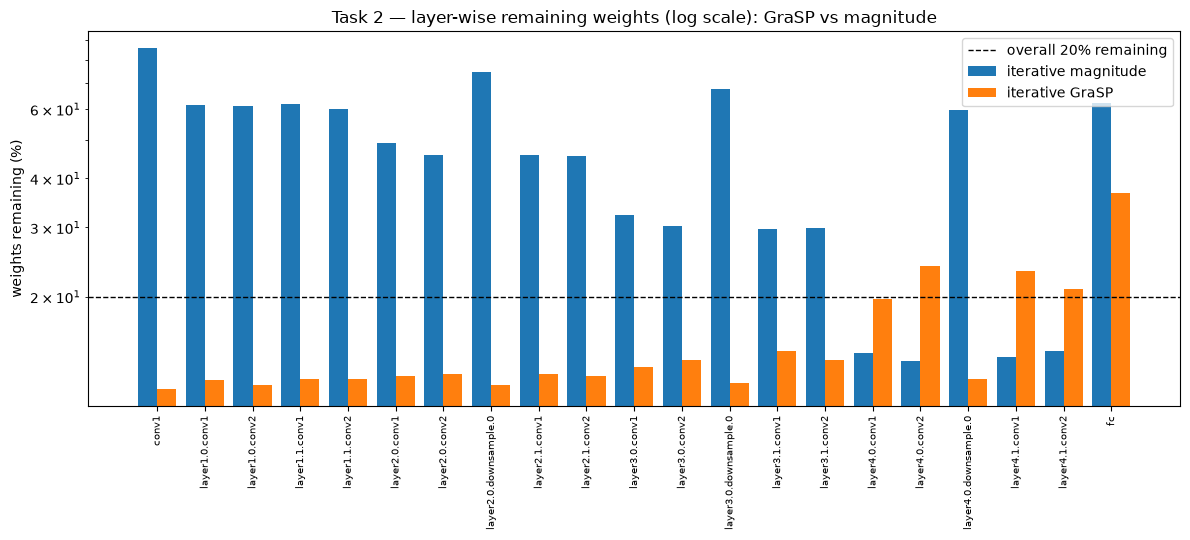

In [37]:
remaining = pd.DataFrame({
    "params": pd.Series(eligible_sizes(RUN_MAG["model"])),
    "iter. magnitude: remaining": 1 - RUN_MAG["sparsity_df"]["sparsity_measured"],
    "iter. GraSP: remaining": 1 - RUN_GRASP["sparsity_df"]["sparsity_measured"],
})
remaining["GraSP - magnitude (pp)"] = 100 * (remaining["iter. GraSP: remaining"]
                                             - remaining["iter. magnitude: remaining"])
show_table("Task 2 — layer-wise remaining-weight ratio", remaining, floatfmt=".4g")

print("\nthinnest layers (surviving fraction):")
for method, run in TASK2_RUNS.items():
    dens = (1 - run["sparsity_df"]["sparsity_measured"]).sort_values()
    collapsed = [n for n in dens.index if dens[n] == 0.0]
    print(f"  {method}:")
    for n in dens.index[:4]:
        print(f"     {n:26s} {dens[n]:.5f}  ({int(dens[n] * remaining['params'][n]):,} weights left)")
    print(f"     fully collapsed layers: {collapsed if collapsed else 'none'}")

fig, ax = plt.subplots(figsize=(12, 5.5))
xs = np.arange(len(remaining))
ax.bar(xs - 0.2, 100 * remaining["iter. magnitude: remaining"], 0.4, label="iterative magnitude")
ax.bar(xs + 0.2, 100 * remaining["iter. GraSP: remaining"], 0.4, label="iterative GraSP")
ax.axhline(100 * (1 - TASK2_TARGET_SPARSITY), color="k", ls="--", lw=1,
           label=f"overall {1 - TASK2_TARGET_SPARSITY:.0%} remaining")
ax.set_xticks(xs)
ax.set_xticklabels(remaining.index, rotation=90, fontsize=7)
ax.set(ylabel="weights remaining (%)", yscale="log",
       title="Task 2 — layer-wise remaining weights (log scale): GraSP vs magnitude")
ax.legend()
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(FIG_DIR / "task2_layerwise_remaining.png", dpi=140, bbox_inches="tight")
plt.show()

### Training curves

Dotted lines mark pruning steps. "Validation" is the full test set.

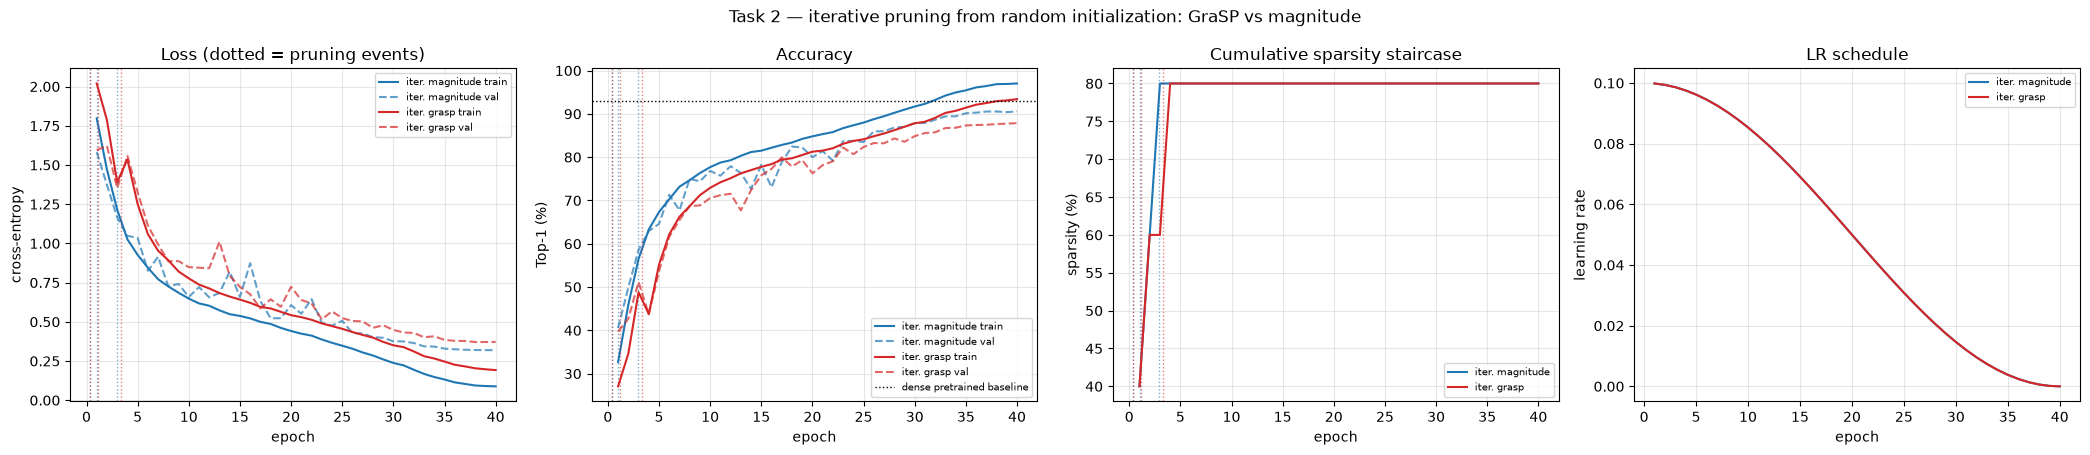

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
colors = {"iterative_magnitude": "tab:blue", "iterative_grasp": "tab:red"}
for method, run in TASK2_RUNS.items():
    h, c = run["history"], colors[method]
    lbl = method.replace("iterative_", "iter. ")
    axes[0].plot(h["epoch"], h["train_loss"], "-", color=c, label=f"{lbl} train")
    axes[0].plot(h["epoch"], h["val_loss"], "--", color=c, alpha=0.7, label=f"{lbl} val")
    axes[1].plot(h["epoch"], h["train_top1"], "-", color=c, label=f"{lbl} train")
    axes[1].plot(h["epoch"], h["val_top1"], "--", color=c, alpha=0.7, label=f"{lbl} val")
    axes[2].plot(h["epoch"], [100 * s for s in h["sparsity"]], "-", color=c, label=lbl)
    axes[3].plot(h["epoch"], h["lr"], "-", color=c, label=lbl)
    for s in run["stages"]:
        for a in axes[:3]:
            a.axvline(s["epoch"], color=c, ls=":", lw=1, alpha=0.6)
axes[0].set(xlabel="epoch", ylabel="cross-entropy", title="Loss (dotted = pruning events)")
axes[1].set(xlabel="epoch", ylabel="Top-1 (%)", title="Accuracy")
axes[1].axhline(RESULTS[BASELINE]["test_top1"], color="k", ls=":", lw=1,
                label="dense pretrained baseline")
axes[2].set(xlabel="epoch", ylabel="sparsity (%)", title="Cumulative sparsity staircase")
axes[3].set(xlabel="epoch", ylabel="learning rate", title="LR schedule")
for a in axes:
    a.grid(alpha=0.3)
    a.legend(fontsize=7)
fig.suptitle("Task 2 — iterative pruning from random initialization: GraSP vs magnitude")
fig.tight_layout()
fig.savefig(FIG_DIR / "task2_training_curves.png", dpi=140, bbox_inches="tight")
plt.show()

## 2.7 Profiling and comparison

* Both final models are profiled as dense masked and as COO models.
* Task 1 rows are shown for reference only: they started from a trained 93.07 % model, while Task 2 trains from random weights in 40 epochs.

In [39]:
for method, run in TASK2_RUNS.items():
    label = RESULTS[method]["label"]
    store, meta, _ = sparse_storage_report(run["model"], run["masks"], method)
    record(method, size_sparse_mb=store["COO int32 no masks (MiB)"])
    run["store"] = store
    profile_model(run["model"], name=method, label=f"{label} (dense masked)")

    sparse_model = to_sparse_coo_model(run["model"])
    with torch.no_grad():
        xs = torch.randn(8, 3, 32, 32, device=DEVICE)
        d = run["model"].eval()(xs)
        s = sparse_model(xs)
    print(f"  {method}: dense-masked vs COO max|diff| = {(d - s).abs().max().item():.3e}")
    profile_model(sparse_model, name=f"{method}_coo", label=f"{label} (COO)")
    record(f"{method}_coo", overall_sparsity=run["overall"]["overall_sparsity_measured"],
           size_dense_mb=store["dense .pt (MiB)"],
           size_sparse_mb=store["COO int32 no masks (MiB)"],
           **{k: RESULTS[method][k] for k in
              ("train_top1", "test_top1", "train_top5", "test_top5",
               "test_macro_f1", "train_macro_f1")})
    del sparse_model
    torch.cuda.empty_cache() if DEVICE.type == "cuda" else None

store_t2 = pd.DataFrame({m: TASK2_RUNS[m]["store"] for m in TASK2_RUNS})
show_table("Task 2 — storage: dense vs COO for the iteratively pruned models",
           store_t2, floatfmt=".4g")

Iterative magnitude 80% (dense masked) lat    6.63 +- 0.10 ms/batch (  51.8 us/img) | peak    64.0 MiB | GPU 425.36 J | CPU 108.94 J
  iterative_magnitude: dense-masked vs COO max|diff| = 1.907e-06
Iterative magnitude 80% (COO) lat    7.40 +- 0.16 ms/batch (  57.8 us/img) | peak    64.0 MiB | GPU 462.68 J | CPU 120.85 J
Iterative GraSP 80% (dense masked) lat    6.66 +- 0.12 ms/batch (  52.0 us/img) | peak    64.0 MiB | GPU 414.93 J | CPU 108.22 J
  iterative_grasp: dense-masked vs COO max|diff| = 9.537e-07
Iterative GraSP 80% (COO)    lat    7.40 +- 0.20 ms/batch (  57.8 us/img) | peak    64.0 MiB | GPU 457.08 J | CPU 119.51 J
### Task 2 — storage: dense vs COO for the iteratively pruned models

|                             |   iterative_magnitude |   iterative_grasp |
|:----------------------------|----------------------:|------------------:|
| dense .pt (MiB)             |            42.7       |        42.7       |
| dense .pt gzip (MiB)        |            12.06      |        12.1

,iterative_magnitude,iterative_grasp
dense .pt (MiB),4.270344e+01,4.270290e+01
dense .pt gzip (MiB),1.205966e+01,1.218558e+01
COO int64 + masks (MiB),8.738233e+01,8.740135e+01
COO int64 no masks (MiB),7.673021e+01,7.674875e+01
COO int32 no masks (MiB),4.268358e+01,4.269241e+01
theory: dense payload (MiB),4.258862e+01,4.258862e+01
theory: COO int64 (MiB),7.661098e+01,7.663085e+01
theory: COO int32 (MiB),4.256435e+01,4.257429e+01
theory: COO int16 (MiB),2.554104e+01,2.554601e+01
nonzeros,2.232870e+06,2.232870e+06


In [40]:
TASK2_VARIANTS = ["iterative_magnitude", "iterative_grasp",
                  "iterative_magnitude_coo", "iterative_grasp_coo"]
COMPARE_VARIANTS = [BASELINE, "local_prune_ft", "global_prune_ft"] + TASK2_VARIANTS
show_table(f"Task 2 — master comparison at {TASK2_TARGET_SPARSITY:.0%} overall sparsity",
           results_table(COMPARE_VARIANTS))

t2_summary = pd.DataFrame({
    "Start point": ["pretrained", "pretrained", "pretrained",
                    "random init", "random init"],
    "Pruning": ["none (dense)", "one-shot local + FT", "one-shot global + FT",
                "iterative magnitude", "iterative GraSP"],
    "Sparsity": [0.0] + [RESULTS[v].get("overall_sparsity") for v in
                         ["local_prune_ft", "global_prune_ft",
                          "iterative_magnitude", "iterative_grasp"]],
    "Test Top-1 (%)": [RESULTS[v]["test_top1"] for v in
                       [BASELINE, "local_prune_ft", "global_prune_ft",
                        "iterative_magnitude", "iterative_grasp"]],
    "Train Top-1 (%)": [RESULTS[v]["train_top1"] for v in
                        [BASELINE, "local_prune_ft", "global_prune_ft",
                         "iterative_magnitude", "iterative_grasp"]],
    "Macro-F1": [RESULTS[v]["test_macro_f1"] for v in
                 [BASELINE, "local_prune_ft", "global_prune_ft",
                  "iterative_magnitude", "iterative_grasp"]],
    "Effective MACs (M)": [RESULTS[v]["macs_effective"] / 1e6 for v in
                           [BASELINE, "local_prune_ft", "global_prune_ft",
                            "iterative_magnitude", "iterative_grasp"]],
    "Latency (ms)": [RESULTS[v]["latency_ms"] for v in
                     [BASELINE, "local_prune_ft", "global_prune_ft",
                      "iterative_magnitude", "iterative_grasp"]],
    "Criterion time (s)": [None, None, None,
                           RUN_MAG["criterion_seconds_total"],
                           RUN_GRASP["criterion_seconds_total"]],
}, index=["Dense baseline", "Task 1 local", "Task 1 global",
          "Task 2 iter. magnitude", "Task 2 iter. GraSP"])
show_table("Task 2 — all pruning methods side by side", t2_summary, floatfmt=".4g")

t2_disc = {
    "warmup_iters": WARMUP["iters"],
    "warmup_acc": WARMUP["acc"],
    "direction_check": {k: float(v) for k, v in DIRECTION_CHECK.items()},
    "direction_chosen_confirmed": "paper" in _best,
    "taylor_check": TAYLOR_CHECK,
    "mag_final_test": RESULTS["iterative_magnitude"]["test_top1"],
    "grasp_final_test": RESULTS["iterative_grasp"]["test_top1"],
    "mag_criterion_s": RUN_MAG["criterion_seconds_total"],
    "grasp_criterion_s": RUN_GRASP["criterion_seconds_total"],
    "criterion_ratio": (RUN_GRASP["criterion_seconds_total"]
                        / max(RUN_MAG["criterion_seconds_total"], 1e-9)),
    "mag_min_density": float((1 - RUN_MAG["sparsity_df"]["sparsity_measured"]).min()),
    "grasp_min_density": float((1 - RUN_GRASP["sparsity_df"]["sparsity_measured"]).min()),
    "mag_min_density_layer": (1 - RUN_MAG["sparsity_df"]["sparsity_measured"]).idxmin(),
    "grasp_min_density_layer": (1 - RUN_GRASP["sparsity_df"]["sparsity_measured"]).idxmin(),
    "task1_global_test": RESULTS["global_prune_ft"]["test_top1"],
    "task1_local_test": RESULTS["local_prune_ft"]["test_top1"],
    "stages": {m: r["stages"] for m, r in TASK2_RUNS.items()},
}
json.dump(t2_disc, open(ART_DIR / "task2_discussion_numbers.json", "w"),
          indent=2, default=float)
for k, v in t2_disc.items():
    if k != "stages":
        print(f"{k:30s} {v}")

### Task 2 — master comparison at 80% overall sparsity

|                                        |   Sparsity |   Train Top-1 |   Test Top-1 |   Train Top-5 |   Test Top-5 |   Macro-F1 |    Params |   Params (nonzero) |   Dense size (MiB) |   COO int32 size, no masks (MiB) |      MACs |   MACs (nonzero) |     FLOPs |   Latency (ms/batch) |   Latency (ms/img) |   Peak GPU mem above weights+input (MiB) |   Avg GPU mem above weights+input (MiB) |   Est. total inference GPU mem (MiB) |   GPU energy (J) |   CPU energy (J) |   Energy (mJ/img) |
|:---------------------------------------|-----------:|--------------:|-------------:|--------------:|-------------:|-----------:|----------:|-------------------:|-------------------:|---------------------------------:|----------:|-----------------:|----------:|---------------------:|-------------------:|-----------------------------------------:|----------------------------------------:|-------------------------------------:|-----------------:|------

## Task 2 — discussion

**Did iterative pruning beat one shot magnitude pruning?**

* Iterative magnitude from scratch: **90.57 %**. Task 1 one shot global: **92.80 %**.
* The 2.2 pp gap mostly reflects the starting point (trained vs random), not iterating.
* A fair test (one shot pruning of the same random start, same 40 epochs) is not in the brief.
* Gradual magnitude pruning barely hurt accuracy at each step: +0.70, −1.40 and 0.00 pp.

**Did GraSP beat iterative magnitude?** No.

* Final test Top-1: GraSP **87.85 %**, magnitude **90.57 %** (gap 2.72 pp; train 95.08 % vs 98.01 %).
* Same start, budget, settings and batches, so the criterion is the only difference. One run each, so the exact gap is uncertain.

| Stage (sparsity) | Magnitude: before → after | GraSP: before → after |
|---|---|---|
| 1 (40 %) | 26.30 → 27.00 % | 26.30 → **9.80 %** |
| 2 (60 %) | 43.30 → 41.90 % | 43.40 → **4.75 %** |
| 3 (80 %) | 63.45 → 63.45 % | 60.40 → **9.80 %** |

* Every GraSP step drops accuracy to chance level (about 10 %), then training recovers it.

**Is the collapse caused by stale BatchNorm statistics?** No.

| Stage | Magnitude after pruning: BN as is → fresh BN | GraSP after pruning: BN as is → fresh BN |
|---|---|---|
| 1 | 27.00 → 27.50 % | 9.80 → **9.30 %** |
| 2 | 41.90 → 41.55 % | 4.75 → **8.80 %** |
| 3 | 63.45 → 64.15 % | 9.80 → **7.75 %** |

* With fresh statistics GraSP still sits at chance; the control (fresh statistics on the unpruned model) moves accuracy by at most 1.7 pp.
* So the collapse comes from the weights GraSP removes.
* Plausible reason: GraSP keeps weights that preserve gradient flow, not the current output. At initialization these agree; after training they do not, and GraSP also removes some large weights.

**Is the sign of the score right?** Yes, where the theory applies.

* Small perturbation check: shrinking the top 1 % $S$ weights raises gradient flow and shrinking the bottom 1 % lowers it. At $\varepsilon = 0.01$ actual / predicted is 1.05 and 0.81 (1.42 and 1.13 at $\varepsilon = 0.001$). From $\varepsilon = 0.1$ the formula overshoots, and at $\varepsilon = 1$ it fails.
* One shot 80 % check: 2.82× the dense gradient flow for the paper's direction vs 0.38× for the reverse. The previous run gave the opposite order (1.25× vs 6.26×), so this check is not reliable; 80 % at once is far outside the first order range.

**Cost**

* Criterion time: GraSP 0.711 s vs magnitude 0.0060 s (about 118×, CUDA synchronized), but only 0.15 % of the 7.7 minute run. Cost is not the reason to prefer magnitude; accuracy is.
* GraSP leaves fewer effective MACs (**21.2 M** vs **55.6 M**): it keeps only 12–15 % of every `layer1`–`layer3` convolution (about 9.4 M MACs each), while magnitude keeps 30–62 %. Latency is the same (about 6.6 ms), so the saving is only theoretical.

**Did any layer collapse?** No, but:

* thinnest under magnitude: `layer4.0.conv2`, **13.7 %** left (a wide layer);
* thinnest under GraSP: **`conv1`**, **11.6 %** left (the most sensitive layer in Task 1; magnitude keeps 86 % of it), which may explain part of GraSP's lower accuracy.
* Global criteria reserve no minimum per layer, so collapse is a real risk at higher sparsity.

**Warm up:** stopped at **26.30 %** after 150 iterations (below 20 % at iteration 100), overshooting the ~20 % target.

---
## End of Task 2

| Path | Contents |
|---|---|
| `checkpoints/task2_init.pt` | random initialization |
| `checkpoints/task2_warmup.pt` | warm up weights, optimizer, scheduler, curves |
| `checkpoints/task2_iterative_{magnitude,grasp}.pt` | final models and masks |
| `artifacts/task2_*.json` | calibration set, curves, stage records, discussion numbers |
| `artifacts/figures/task2_*.png` | warm up, training curves, remaining weights |

---
# Task 3 — Structured Channel Pruning

* Remove whole channels so tensors really shrink (He et al., ICCV 2017). Starts from the pretrained model.
* Per layer: pick the input channels to keep with LASSO, then refit the weights with least squares.

**Method.** For a convolution $W\in\mathbb{R}^{n\times c\times k_h\times k_w}$ and calibration inputs $X$:

1. `F.unfold` gives $X_{\text{unf}}\in\mathbb{R}^{(N L)\times(c\,k_h k_w)}$ and $Y = X_{\text{unf}}W_{\text{mat}}$.
2. **Channel selection.** With $Z_i$ the output part from input channel $i$:
   $$\hat\beta = \arg\min_\beta \frac{1}{2N}\Big\lVert Y - \sum_{i=1}^{c}\beta_i Z_i\Big\rVert_F^2 + \lambda\lVert\beta\rVert_1,$$
   increasing $\lambda$ until $c_0$ values of $\beta$ are nonzero. Changes: $\beta \ge 0$, and a tiny ridge term (see 3.2).
3. **Reconstruction.** With $X' = [\beta_1X_1,\dots,\beta_{c_0}X_{c_0}]$:
   $$W' = \arg\min_{W'}\lVert Y - X'W'^\top\rVert_F^2 ,$$
   solved with `torch.linalg.lstsq`.

**Which channels.** Each block's **internal** channels (output of `conv1` = input of `conv2`):

```
           ┌───────────────── identity (unchanged width) ──────────────────┐
  x ──▶ conv1 ──▶ bn1 ──▶ relu ──▶ conv2 ──▶ bn2 ──▶ (+) ──▶ relu ──▶
        └──── pruned: C → c₀ ────┘          └── width unchanged ──┘
```

* `conv1` output and `conv2` input shrink together (instruction 4), so each removed channel saves weights in two convolutions.
* Nothing feeding a residual addition changes width, so both branches still match (instruction 5).

**Other choices**

* The stem and `layer1.0` are not pruned (instruction 1).
* Channel budgets come from Task 1's sensitivity sweep, scaled to hit the target (instruction 2).
* Blocks are pruned one after another; each uses calibration data from the already pruned network.
* LASSO is solved on a small Gram matrix form (3.2).
* `lstsq` runs in float64 on the CPU (`gelsd`), which handles rank deficient inputs.
* `fc` is left dense (5,120 weights, 0.05 %).

In [ ]:
# --- Task 3 configuration ----------------------------------------------------------
TASK3_TARGET_SPARSITY = TARGET_SPARSITY
# `layer4` runs at 2x2, so it offers only 4 sampled rows per image. 2048 images keeps
# every layer — including the most heavily pruned ones — at the full row budget below,
# rather than letting the deepest blocks fall back to a thinly-conditioned fit.
TASK3_CALIB_IMAGES = 2048
TASK3_ROWS_PER_LAYER = 8000
TASK3_MIN_KEEP = 0.05
TASK3_MAX_KEEP = 1.00
TASK3_LASSO_POSITIVE = True
TASK3_LASSO_RIDGE = 1e-6
TASK3_FT_EPOCHS = 15
# Measured, not assumed: at lr=0.01 fine-tuning *destroyed* the reconstruction. The
# refitted model enters fine-tuning at 87.98% Top-1, and lr=0.01 knocked it to ~33%
# within 15 iterations, clawing back only to 86.45% after 10 epochs — a net loss of
# 1.53 pp. Subproblem (ii) has already placed the weights near a good optimum, so this
# needs the same gentle refinement Task 1 needed, not aggressive retraining.
TASK3_FT_LR = 0.001
TASK3_FT_MOMENTUM = 0.9
TASK3_FT_WEIGHT_DECAY = 5e-4

# the blocks we prune: every BasicBlock except the very first one
TASK3_BLOCKS = [f"layer{s}.{b}" for s in (1, 2, 3, 4) for b in (0, 1)][1:]
print(f"blocks pruned ({len(TASK3_BLOCKS)}): {TASK3_BLOCKS}")
print(f"target overall parameter reduction: {TASK3_TARGET_SPARSITY:.0%}")
print(f"calibration: {TASK3_CALIB_IMAGES} images, "
      f"{TASK3_ROWS_PER_LAYER:,} sampled rows per layer")

blocks pruned (7): ['layer1.1', 'layer2.0', 'layer2.1', 'layer3.0', 'layer3.1', 'layer4.0', 'layer4.1']
target overall parameter reduction: 80%
calibration: 2048 images, 8,000 sampled rows per layer


## 3.1 Calibration data and unfold

`collect_block_io` records the input and output of a block's `conv2` on the calibration images, unfolds the input and checks that $X_{\text{unf}}W_{\text{mat}}$ reproduces the real output.

In [42]:
calib_g = torch.Generator().manual_seed(SEED)
_calib_idx3 = torch.randperm(len(train_eval_set), generator=calib_g)[:TASK3_CALIB_IMAGES]
task3_calib_loader = DataLoader(Subset(train_eval_set, _calib_idx3.tolist()),
                                batch_size=128, shuffle=False, num_workers=4)
TASK3_CALIB_BATCHES = [x.to(DEVICE) for x, _ in task3_calib_loader]
print(f"Task 3 calibration: {sum(x.shape[0] for x in TASK3_CALIB_BATCHES)} images "
      f"in {len(TASK3_CALIB_BATCHES)} batches")


@torch.no_grad()
def collect_block_io(model, block_name, rows=TASK3_ROWS_PER_LAYER, seed=SEED, verify=True):
    block = model.get_submodule(block_name)
    conv = block.conv2
    cap = {}

    def hook(mod, inp, out):
        cap["x"], cap["y"] = inp[0].detach(), out.detach()

    h = conv.register_forward_hook(hook)
    model.eval()

    g = torch.Generator(device="cpu").manual_seed(seed)
    per_batch = max(1, rows // len(TASK3_CALIB_BATCHES))
    Xs, Ys = [], []
    W_mat = conv.weight.detach().reshape(conv.out_channels, -1).t()

    for xb in TASK3_CALIB_BATCHES:
        model(xb)
        x, y = cap["x"], cap["y"]
        xu = F.unfold(x, conv.kernel_size, dilation=conv.dilation,
                      padding=conv.padding, stride=conv.stride)
        N, ck, L = xu.shape
        xu = xu.permute(0, 2, 1).reshape(N * L, ck)
        yt = y.permute(0, 2, 3, 1).reshape(N * L, conv.out_channels)

        if verify:
            err = (xu @ W_mat - yt).abs().max().item()
            scale = yt.abs().max().item() + 1e-12
            assert err / scale < 1e-3, (
                f"{block_name}: unfold reconstruction mismatch "
                f"(max abs err {err:.3e}, relative {err / scale:.3e})")
            verify = False

        sel = torch.randperm(N * L, generator=g)[:per_batch].to(xu.device)
        Xs.append(xu[sel].clone())
        Ys.append(yt[sel].clone())
        del xu, yt

    h.remove()
    X_unf = torch.cat(Xs)[:rows]
    Y = torch.cat(Ys)[:rows]
    del Xs, Ys
    return X_unf, Y


print("collect_block_io() defined — unfold layout is asserted against the real conv output.")

Task 3 calibration: 2048 images in 16 batches
collect_block_io() defined — unfold layout is asserted against the real conv output.


## 3.2 LASSO channel selection

* The objective is quadratic in $\beta$. With $G_{ij} = \langle Z_i, Z_j\rangle$ and $Y=\sum_j Z_j$:

$$\Big\lVert Y - \sum_i\beta_iZ_i\Big\rVert_F^2 = \lVert D\beta - D\mathbf{1}\rVert^2 + \text{const}, \qquad D^\top D = G .$$

* So `Lasso` gets a $c\times c$ problem instead of one with billions of rows.
* A ridge $\epsilon I$ ($\epsilon = 10^{-6}\times$ mean diagonal of $G$) keeps the Cholesky step stable; it adds $\epsilon\lVert\beta-\mathbf 1\rVert^2$ to the objective.
* Unconverged fits are retried with more iterations; convergence, iterations and duality gap are recorded.

In [43]:
import warnings
from sklearn.exceptions import ConvergenceWarning

TASK3_LASSO_MAX_ITERS = (5000, 50000, 500000)
from sklearn.linear_model import Lasso


def _gram_design(X_unf, weight):
    n, c, kh, kw = weight.shape
    k = kh * kw
    S = (X_unf.t() @ X_unf).double()
    M = weight.detach().reshape(n, c * k).t().double()
    T = M @ M.t()
    G = torch.einsum("iajb,iajb->ij", S.view(c, k, c, k), T.view(c, k, c, k))
    G = 0.5 * (G + G.t())
    ridge = TASK3_LASSO_RIDGE * torch.diagonal(G).mean().clamp(min=1e-12)
    L = torch.linalg.cholesky(G + ridge * torch.eye(c, dtype=G.dtype, device=G.device))
    D = L.t()
    return D, D @ torch.ones(c, dtype=D.dtype, device=D.device), G


def select_channels_lasso(X_unf, Y, weight, c0, max_iter=60, verbose=False):
    c = weight.shape[1]
    D, target, G = _gram_design(X_unf, weight)
    Dn, tn = D.cpu().numpy(), target.cpu().numpy()

    def n_nonzero(alpha):
        las = Lasso(alpha=alpha, fit_intercept=False, positive=TASK3_LASSO_POSITIVE,
                    max_iter=5000, tol=1e-6)
        las.fit(Dn, tn)
        return int((las.coef_ != 0).sum()), las.coef_

    # bracket: alpha_lo keeps (almost) everything, alpha_hi kills (almost) everything
    scale = float(np.abs(Dn.T @ tn).max() / max(len(tn), 1))
    lo, hi = scale * 1e-8, scale * 10.0
    n_lo, coef_lo = n_nonzero(lo)
    n_hi, coef_hi = n_nonzero(hi)
    it, coef = 0, coef_lo
    if n_lo <= c0:
        coef, alpha = coef_lo, lo
    else:
        for it in range(max_iter):
            mid = math.sqrt(lo * hi)
            n_mid, coef = n_nonzero(mid)
            if verbose:
                print(f"      lasso: alpha={mid:.3e} -> {n_mid} nonzero (want {c0})")
            if n_mid == c0:
                alpha = mid
                break
            if n_mid > c0:
                lo = mid
            else:
                hi = mid
            alpha = mid
        else:
            alpha = mid

    # refit once at the chosen alpha (coordinate descent is deterministic, so the
    # coefficients are the same) to record whether the final fit converged
    # if the fit has not converged, retry with a larger iteration budget
    for budget in TASK3_LASSO_MAX_ITERS:
        final = Lasso(alpha=alpha, fit_intercept=False, positive=TASK3_LASSO_POSITIVE,
                      max_iter=budget, tol=1e-6)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            final.fit(Dn, tn)
        converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        if converged:
            break
    assert converged, f"LASSO did not converge even with max_iter={budget}"
    coef = final.coef_
    rel_gap = float(np.ravel(final.dual_gap_)[0]) / max(float(tn @ tn) / (2 * len(tn)), 1e-30)

    beta = torch.from_numpy(coef).to(X_unf.device).float()
    nz = int((beta != 0).sum())
    # assignment's fallback: if the sweep cannot land exactly on c0, zero the lowest
    # non-zero betas until only c0 remain (or, if too few, top up by |beta| order)
    order = torch.argsort(beta.abs(), descending=True)
    kept = order[:c0]
    kept, _ = torch.sort(kept)
    assert kept.numel() == c0, f"kept {kept.numel()} channels, wanted {c0}"
    info = {"alpha": float(alpha), "lasso_nonzero": nz, "requested": c0,
            "bisect_iters": it + 1, "beta_sum": float(beta.sum()),
            "beta_kept_sum": float(beta[kept].sum()),
            "final_converged": converged, "final_n_iter": int(final.n_iter_),
            "final_max_iter": budget, "final_nonzero": nz,
            "final_rel_dual_gap": rel_gap}
    beta_kept = beta[kept].clone()
    # a fully-zero beta would erase the layer; fall back to unit weights on the
    # magnitude-strongest channels so reconstruction still has something to fit
    if float(beta_kept.abs().sum()) == 0.0:
        beta_kept = torch.ones_like(beta_kept)
        info["beta_fallback"] = True
    return kept, beta_kept, info


print("select_channels_lasso() defined.")

select_channels_lasso() defined.


## 3.3 Least squares reconstruction

$W'$ is refitted so the layer reproduces its original output from the kept channels. $\beta$ is folded into the weights, so no extra scaling is needed at inference.

In [44]:
def reconstruct_weights(X_unf, Y, weight, kept, beta_kept):
    n, c, kh, kw = weight.shape
    k = kh * kw
    cols = (kept.view(-1, 1) * k + torch.arange(k, device=kept.device)).reshape(-1)
    beta_rep = beta_kept.repeat_interleave(k)

    X_kept = X_unf[:, cols].double().cpu()
    Xp = X_kept * beta_rep.double().cpu()
    Yd = Y.double().cpu()

    # SVD-based least squares: robust to rank deficiency, unlike the CUDA driver
    sol = torch.linalg.lstsq(Xp, Yd, driver="gelsd").solution

    base = float((Yd ** 2).sum()) + 1e-12
    resid = float(((Xp @ sol - Yd) ** 2).sum())

    # For contrast: the error if we simply dropped the unselected channels and kept the
    # original weights, with no refit. The gap between the two is what subproblem (ii) buys.
    W_kept = weight.detach().reshape(n, c * k).t()[cols].double().cpu()
    resid_no_refit = float(((X_kept @ W_kept - Yd) ** 2).sum())

    V_mat = sol * beta_rep.double().cpu().unsqueeze(1)
    V = V_mat.t().reshape(n, len(kept), kh, kw).to(weight.device, weight.dtype).contiguous()
    return V, {"relative_residual": resid / base,
               "relative_residual_no_refit": resid_no_refit / base}


print("reconstruct_weights() defined.")

reconstruct_weights() defined.


## 3.4 Surgery

`conv1`, `bn1` and `conv2` are replaced by smaller layers. Nothing is masked.

In [45]:
def shrink_block(block, kept, new_conv2_weight):
    kept = kept.to(block.conv1.weight.device)
    c0 = len(kept)
    old1, oldbn, old2 = block.conv1, block.bn1, block.conv2

    new1 = nn.Conv2d(old1.in_channels, c0, old1.kernel_size, old1.stride,
                     old1.padding, old1.dilation, old1.groups,
                     bias=old1.bias is not None).to(old1.weight.device)
    with torch.no_grad():
        new1.weight.copy_(old1.weight[kept])
        if old1.bias is not None:
            new1.bias.copy_(old1.bias[kept])

    newbn = nn.BatchNorm2d(c0, eps=oldbn.eps, momentum=oldbn.momentum,
                           affine=oldbn.affine,
                           track_running_stats=oldbn.track_running_stats
                           ).to(oldbn.weight.device)
    with torch.no_grad():
        newbn.weight.copy_(oldbn.weight[kept])
        newbn.bias.copy_(oldbn.bias[kept])
        newbn.running_mean.copy_(oldbn.running_mean[kept])
        newbn.running_var.copy_(oldbn.running_var[kept])
        newbn.num_batches_tracked.copy_(oldbn.num_batches_tracked)

    new2 = nn.Conv2d(c0, old2.out_channels, old2.kernel_size, old2.stride,
                     old2.padding, old2.dilation, old2.groups,
                     bias=old2.bias is not None).to(old2.weight.device)
    with torch.no_grad():
        new2.weight.copy_(new_conv2_weight)
        if old2.bias is not None:
            new2.bias.copy_(old2.bias)

    block.conv1, block.bn1, block.conv2 = new1, newbn, new2
    return block


def block_internal_width(model, block_name):
    return model.get_submodule(block_name).conv1.out_channels


print("shrink_block() defined.")

shrink_block() defined.


## 3.5 Channel budgets

* Each block's base keep ratio is $1-a_b$, from the Task 1 sweep of its `conv1`.
* One factor $\alpha$ (bisection) scales them so the whole model reaches the parameter target.
* A block keeping a fraction $r$ of its channels keeps about $r$ of its weights. The unpruned layers keep all theirs, so pruned blocks must keep under 20 % on average; the largest keep 14.5 %.

In [46]:
def task3_channel_budget(model, target_sparsity=TASK3_TARGET_SPARSITY,
                         blocks=TASK3_BLOCKS, allowable=None):
    allowable = allowable if allowable is not None else allowable_sensitivity
    dense_params = sum(p.numel() for p in model.parameters())
    widths = {b: block_internal_width(model, b) for b in blocks}

    # parameters that scale with each block's internal width m_b:
    #   conv1: in_b * m * k    conv2: m * out_b * k    bn1: 2m (+ nothing else)
    coef, fixed = {}, dense_params
    for b in blocks:
        blk = model.get_submodule(b)
        k = blk.conv1.kernel_size[0] * blk.conv1.kernel_size[1]
        per_channel = blk.conv1.in_channels * k + blk.conv2.out_channels * k + 2
        coef[b] = per_channel
        fixed -= per_channel * widths[b]

    target_params = (1.0 - target_sparsity) * dense_params

    def widths_for(alpha):
        out = {}
        for b in blocks:
            base = 1.0 - float(allowable.get(f"{b}.conv1", 0.5))
            ratio = float(np.clip(alpha * base, TASK3_MIN_KEEP, TASK3_MAX_KEEP))
            out[b] = max(1, int(round(ratio * widths[b])))
        return out

    def params_for(alpha):
        w = widths_for(alpha)
        return fixed + sum(coef[b] * w[b] for b in blocks)

    lo, hi = 1e-4, 100.0
    if params_for(lo) > target_params:
        print("  warning: target unreachable even at the minimum keep ratio")
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if params_for(mid) < target_params:
            lo = mid
        else:
            hi = mid
    alpha = 0.5 * (lo + hi)
    new_widths = widths_for(alpha)
    achieved = 1.0 - params_for(alpha) / dense_params
    return new_widths, widths, {"alpha": alpha, "achieved_sparsity": achieved,
                                "dense_params": dense_params,
                                "target_params": target_params}


allowable_sensitivity = allowable
TASK3_WIDTHS, TASK3_ORIG_WIDTHS, TASK3_BUDGET = task3_channel_budget(dense_model)
budget_df = pd.DataFrame({
    "original channels": pd.Series(TASK3_ORIG_WIDTHS),
    "kept channels c0": pd.Series(TASK3_WIDTHS),
    "keep ratio": pd.Series({b: TASK3_WIDTHS[b] / TASK3_ORIG_WIDTHS[b] for b in TASK3_BLOCKS}),
    "tolerable sparsity (Task 1)": pd.Series(
        {b: allowable_sensitivity.get(f"{b}.conv1") for b in TASK3_BLOCKS}),
})
show_table(f"Task 3.5 — per-block channel budget (alpha={TASK3_BUDGET['alpha']:.4f}, "
           f"predicted overall sparsity {TASK3_BUDGET['achieved_sparsity']:.2%})",
           budget_df, floatfmt=".4g")

### Task 3.5 — per-block channel budget (alpha=1.4551, predicted overall sparsity 80.11%)

|          |   original channels |   kept channels c0 |   keep ratio |   tolerable sparsity (Task 1) |
|:---------|--------------------:|-------------------:|-------------:|------------------------------:|
| layer1.1 |                  64 |                 28 |       0.4375 |                           0.7 |
| layer2.0 |                 128 |                 56 |       0.4375 |                           0.7 |
| layer2.1 |                 128 |                 93 |       0.7266 |                           0.5 |
| layer3.0 |                 256 |                 74 |       0.2891 |                           0.8 |
| layer3.1 |                 256 |                 37 |       0.1445 |                           0.9 |
| layer4.0 |                 512 |                 74 |       0.1445 |                           0.9 |
| layer4.1 |                 512 |                 74 |       0.1445 |               

,original channels,kept channels c0,keep ratio,tolerable sparsity (Task 1)
layer1.1,64,28,0.437500,0.7
layer2.0,128,56,0.437500,0.7
layer2.1,128,93,0.726562,0.5
layer3.0,256,74,0.289062,0.8
layer3.1,256,37,0.144531,0.9
layer4.0,512,74,0.144531,0.9
layer4.1,512,74,0.144531,0.9


## 3.6 Sequential pruning

For each block in order: collect data from the current model, select channels, refit, shrink, then measure accuracy.

In [47]:
def run_structured_pruning(widths=None, verbose=True):
    widths = widths or TASK3_WIDTHS
    model = resnet18_cifar(pretrained=True, verbose=False)
    recs = []
    acc0 = eval_cached(model)
    print(f"start: dense pretrained, subset Top-1 {acc0:.2f}%, "
          f"{sum(p.numel() for p in model.parameters()):,} params\n")

    for b in TASK3_BLOCKS:
        c_orig = block_internal_width(model, b)
        c0 = min(widths[b], c_orig)
        t0 = time.perf_counter()
        X_unf, Y = collect_block_io(model, b)
        t_collect = time.perf_counter() - t0

        t0 = time.perf_counter()
        kept, beta_kept, linfo = select_channels_lasso(
            X_unf, Y, model.get_submodule(b).conv2.weight, c0)
        t_lasso = time.perf_counter() - t0

        t0 = time.perf_counter()
        V, rinfo = reconstruct_weights(X_unf, Y, model.get_submodule(b).conv2.weight,
                                       kept, beta_kept)
        t_lstsq = time.perf_counter() - t0

        shrink_block(model.get_submodule(b), kept, V)
        acc = eval_cached(model)
        params = sum(p.numel() for p in model.parameters())
        rec = {"block": b, "channels_before": c_orig, "channels_kept": c0,
               "keep_ratio": c0 / c_orig,
               "lasso_alpha": linfo["alpha"], "lasso_nonzero": linfo["lasso_nonzero"],
               "lasso_converged": linfo["final_converged"],
               "lasso_rel_dual_gap": linfo["final_rel_dual_gap"],
               "lasso_iters": linfo["final_n_iter"],
               "lasso_final_nonzero": linfo["final_nonzero"],
               "recon_rel_residual": rinfo["relative_residual"],
               "subset_top1_after": acc, "params_after": params,
               "sparsity_after": 1 - params / TASK3_BUDGET["dense_params"],
               "t_collect_s": t_collect, "t_lasso_s": t_lasso, "t_lstsq_s": t_lstsq}
        recs.append(rec)
        if verbose:
            print(f"{b:12s} {c_orig:4d} -> {c0:4d} ch ({c0 / c_orig:5.1%}) | "
                  f"lasso a={linfo['alpha']:.2e} nz={linfo['lasso_nonzero']:3d} | "
                  f"recon resid {rinfo['relative_residual']:.4f} | "
                  f"subset top1 {acc:5.2f}% | params {params:,} "
                  f"({rec['sparsity_after']:.2%} pruned) | "
                  f"t: io {t_collect:.1f}s lasso {t_lasso:.1f}s lstsq {t_lstsq:.1f}s")
        del X_unf, Y
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    return model, recs


set_seed()
t0 = time.perf_counter()
struct_model, TASK3_RECORDS = run_structured_pruning()
task3_prune_minutes = (time.perf_counter() - t0) / 60
rec_df = pd.DataFrame(TASK3_RECORDS).set_index("block")
show_table("Task 3.6 — sequential channel pruning, block by block", rec_df, floatfmt=".4g")
print(f"\ntotal pruning time: {task3_prune_minutes:.2f} min")
print(f"architecture now: "
      + ", ".join(f"{b}:{block_internal_width(struct_model, b)}" for b in TASK3_BLOCKS))

start: dense pretrained, subset Top-1 93.65%, 11,173,962 params

layer1.1       64 ->   28 ch (43.8%) | lasso a=3.82e-03 nz= 28 | recon resid 0.0991 | subset top1 92.45% | params 11,132,418 (0.37% pruned) | t: io 0.1s lasso 0.0s lstsq 0.1s
layer2.0      128 ->   56 ch (43.8%) | lasso a=4.09e-03 nz= 56 | recon resid 0.0690 | subset top1 90.20% | params 11,007,858 (1.49% pruned) | t: io 0.1s lasso 0.0s lstsq 0.3s
layer2.1      128 ->   93 ch (72.7%) | lasso a=5.73e-04 nz= 93 | recon resid 0.0292 | subset top1 89.55% | params 10,927,148 (2.21% pruned) | t: io 0.1s lasso 0.0s lstsq 0.8s
layer3.0      256 ->   74 ch (28.9%) | lasso a=3.50e-04 nz= 74 | recon resid 0.0723 | subset top1 88.50% | params 10,297,792 (7.84% pruned) | t: io 0.1s lasso 0.1s lstsq 0.7s
layer3.1      256 ->   37 ch (14.5%) | lasso a=3.85e-04 nz= 37 | recon resid 0.0187 | subset top1 88.05% | params 9,288,202 (16.88% pruned) | t: io 0.1s lasso 0.1s lstsq 0.3s


/home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.223765e-04, tolerance: 1.857e-04
  model = cd_fast.enet_coordinate_descent(
/home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.527275e-03, tolerance: 1.857e-04
  model = cd_fast.enet_coordinate_descent(
/home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to inc

layer4.0      512 ->   74 ch (14.5%) | lasso a=1.76e-05 nz= 74 | recon resid 0.0002 | subset top1 87.95% | params 6,259,870 (43.98% pruned) | t: io 0.1s lasso 8.1s lstsq 1.2s


/home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.850748e-04, tolerance: 2.649e-04
  model = cd_fast.enet_coordinate_descent(
/home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.974723e-02, tolerance: 2.649e-04
  model = cd_fast.enet_coordinate_descent(
/home/adnan/Documents/AI-On-Edge/PA-2/working/PA-2/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to inc

layer4.1      512 ->   74 ch (14.5%) | lasso a=9.21e-06 nz= 73 | recon resid 0.0000 | subset top1 87.95% | params 2,222,386 (80.11% pruned) | t: io 0.1s lasso 9.0s lstsq 1.1s
### Task 3.6 — sequential channel pruning, block by block

| block    |   channels_before |   channels_kept |   keep_ratio |   lasso_alpha |   lasso_nonzero | lasso_converged   |   lasso_rel_dual_gap |   lasso_iters |   lasso_final_nonzero |   recon_rel_residual |   subset_top1_after |   params_after |   sparsity_after |   t_collect_s |   t_lasso_s |   t_lstsq_s |
|:---------|------------------:|----------------:|-------------:|--------------:|----------------:|:------------------|---------------------:|--------------:|----------------------:|---------------------:|--------------------:|---------------:|-----------------:|--------------:|------------:|------------:|
| layer1.1 |                64 |              28 |       0.4375 |     0.00382   |              28 | True              |            8.781e-09 |        

In [48]:
# accuracy immediately after structured pruning, before any fine-tuning
set_seed()
struct_pre, _, _ = evaluate_both(struct_model, name="structured_preft",
                                 label="Structured channel prune (no FT)",
                                 desc="structured pre-FT")
_p = sum(p.numel() for p in struct_model.parameters())
record("structured_preft",
       overall_sparsity=1 - _p / TASK3_BUDGET["dense_params"], params_total=_p)
# profile now, while the weights are still the pre-fine-tuning ones
profile_model(struct_model, name="structured_preft",
              label="Structured channel prune (no FT)", verbose=False)
print(f"\nparameters: {TASK3_BUDGET['dense_params']:,} -> {_p:,} "
      f"({1 - _p / TASK3_BUDGET['dense_params']:.2%} removed)")
print(f"test Top-1: {RESULTS[BASELINE]['test_top1']:.2f}% -> {struct_pre['test_top1']:.2f}% "
      f"({struct_pre['test_top1'] - RESULTS[BASELINE]['test_top1']:+.2f} pp)")

Structured channel prune (no FT) train top1  94.59 | test top1  87.97 | test top5  99.42 | macro-F1 0.8797

parameters: 11,173,962 -> 2,222,386 (80.11% removed)
test Top-1: 93.07% -> 87.97% (-5.10 pp)


## 3.7 Fine tuning

Ordinary training of the smaller network (15 epochs, lr 0.001, cross entropy). No mask is needed.

In [49]:
def finetune_plain(model, epochs=TASK3_FT_EPOCHS, lr=TASK3_FT_LR, tag="structured",
                   seed=SEED):
    set_seed(seed)
    loader = make_train_loader(seed)
    model.to(DEVICE).train()
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=TASK3_FT_MOMENTUM,
                          weight_decay=TASK3_FT_WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(loader))
    crit = nn.CrossEntropyLoss()
    hist = {"epoch": [], "train_loss": [], "train_top1": [], "val_loss": [],
            "val_top1": [], "lr": []}
    for ep in range(1, epochs + 1):
        model.train()
        rl = rc = rn = 0
        bar = tqdm(loader, desc=f"{tag} ep {ep}/{epochs}", leave=False)
        for x, y in bar:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            out = model(x)
            loss = crit(out, y)
            loss.backward()
            opt.step()
            sched.step()
            rl += loss.item() * y.numel()
            rc += (out.argmax(1) == y).sum().item()
            rn += y.numel()
            bar.set_postfix(loss=f"{rl / rn:.3f}", acc=f"{100 * rc / rn:.2f}")
        val = evaluate(model, test_loader, desc=f"{tag} ep {ep} val")
        hist["epoch"].append(ep)
        hist["train_loss"].append(rl / rn)
        hist["train_top1"].append(100 * rc / rn)
        hist["val_loss"].append(val["loss"])
        hist["val_top1"].append(val["top1"])
        hist["lr"].append(opt.param_groups[0]["lr"])
        print(f"  {tag} ep {ep}/{epochs}: train loss {rl / rn:.4f} acc {100 * rc / rn:.2f}% "
              f"| val loss {val['loss']:.4f} top1 {val['top1']:.2f}%")
    return hist


t0 = time.perf_counter()
TASK3_HIST = finetune_plain(struct_model)
task3_ft_minutes = (time.perf_counter() - t0) / 60
json.dump({"records": TASK3_RECORDS, "history": TASK3_HIST,
           "budget": TASK3_BUDGET, "widths": TASK3_WIDTHS,
           "prune_minutes": task3_prune_minutes, "ft_minutes": task3_ft_minutes},
          open(ART_DIR / "task3_history.json", "w"), indent=2, default=float)
torch.save({"model": struct_model.state_dict(), "widths": TASK3_WIDTHS,
            "records": TASK3_RECORDS}, CKPT_DIR / "task3_structured_ft.pt")
print(f"\nfine-tuning time: {task3_ft_minutes:.1f} min")

set_seed()
struct_post, _, _ = evaluate_both(struct_model, name="structured_ft",
                                  label="Structured channel prune + FT",
                                  desc="structured post-FT")
record("structured_ft", overall_sparsity=1 - _p / TASK3_BUDGET["dense_params"],
       finetune_minutes=task3_ft_minutes)

  structured ep 1/15: train loss 0.4197 acc 86.39% | val loss 0.4998 top1 83.89%
  structured ep 2/15: train loss 0.3083 acc 89.99% | val loss 0.4566 top1 85.50%
  structured ep 3/15: train loss 0.2719 acc 90.98% | val loss 0.3914 top1 87.52%
  structured ep 4/15: train loss 0.2438 acc 92.06% | val loss 0.3676 top1 88.35%
  structured ep 5/15: train loss 0.2085 acc 93.11% | val loss 0.3441 top1 89.33%
  structured ep 6/15: train loss 0.1851 acc 93.99% | val loss 0.3328 top1 89.84%
  structured ep 7/15: train loss 0.1549 acc 95.04% | val loss 0.3117 top1 90.40%
  structured ep 8/15: train loss 0.1361 acc 95.58% | val loss 0.3133 top1 90.43%
  structured ep 9/15: train loss 0.1109 acc 96.46% | val loss 0.2915 top1 91.41%
  structured ep 10/15: train loss 0.0953 acc 96.97% | val loss 0.2779 top1 91.71%
  structured ep 11/15: train loss 0.0764 acc 97.69% | val loss 0.2802 top1 91.90%
  structured ep 12/15: train loss 0.0660 acc 98.08% | val loss 0.2705 top1 92.23%
  structured ep 13/15: tr

{'variant': 'structured_ft',
 'label': 'Structured channel prune + FT',
 'train_top1': 99.228,
 'train_top5': 99.99,
 'train_macro_f1': 0.9922822713851929,
 'train_loss': 0.030574540853500365,
 'test_top1': 92.37,
 'test_top5': 99.72,
 'test_macro_f1': 0.9237618446350098,
 'test_loss': 0.2721038548707962,
 'test_per_class_f1': [0.9275504946708679,
  0.9589589834213257,
  0.8998458981513977,
  0.843137264251709,
  0.932935893535614,
  0.8808080554008484,
  0.9448897838592529,
  0.9548646211624146,
  0.9512317776679993,
  0.9433962106704712],
 'overall_sparsity': 0.8011102955245418,
 'finetune_minutes': 3.0107835407330032}

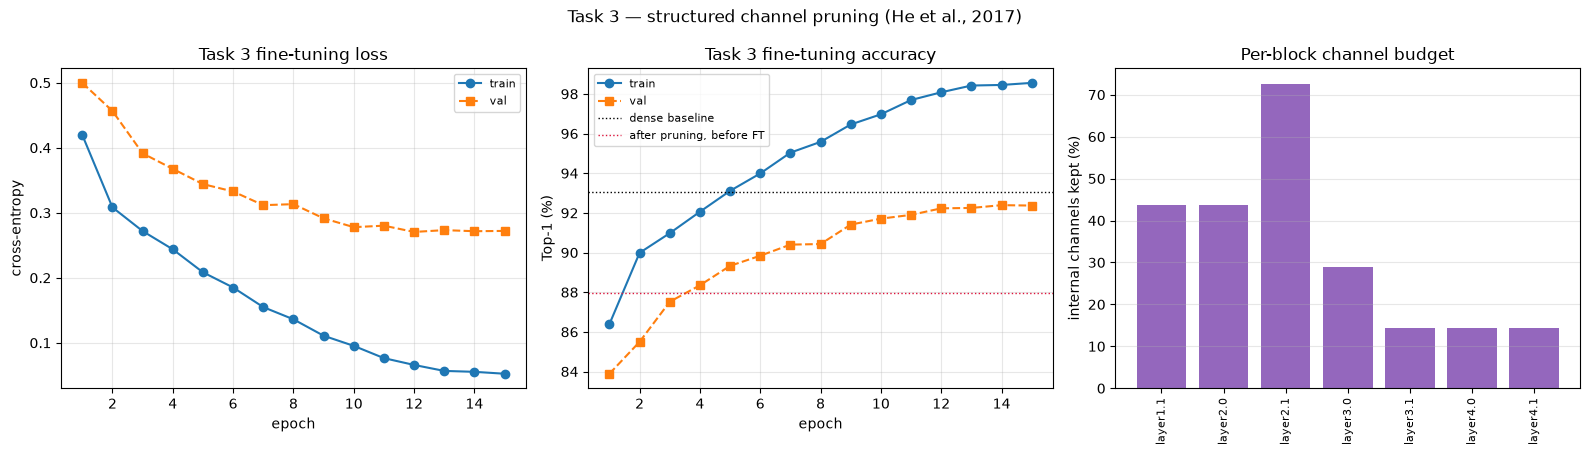

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].plot(TASK3_HIST["epoch"], TASK3_HIST["train_loss"], "o-", label="train")
axes[0].plot(TASK3_HIST["epoch"], TASK3_HIST["val_loss"], "s--", label="val")
axes[0].set(xlabel="epoch", ylabel="cross-entropy", title="Task 3 fine-tuning loss")
axes[1].plot(TASK3_HIST["epoch"], TASK3_HIST["train_top1"], "o-", label="train")
axes[1].plot(TASK3_HIST["epoch"], TASK3_HIST["val_top1"], "s--", label="val")
axes[1].axhline(RESULTS[BASELINE]["test_top1"], color="k", ls=":", lw=1, label="dense baseline")
axes[1].axhline(struct_pre["test_top1"], color="crimson", ls=":", lw=1,
                label="after pruning, before FT")
axes[1].set(xlabel="epoch", ylabel="Top-1 (%)", title="Task 3 fine-tuning accuracy")
kr = pd.Series({r["block"]: r["keep_ratio"] for r in TASK3_RECORDS})
axes[2].bar(range(len(kr)), 100 * kr.values, color="tab:purple")
axes[2].set_xticks(range(len(kr)))
axes[2].set_xticklabels(kr.index, rotation=90, fontsize=8)
axes[2].set(ylabel="internal channels kept (%)", title="Per-block channel budget")
for a in axes[:2]:
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
axes[2].grid(alpha=0.3, axis="y")
fig.suptitle("Task 3 — structured channel pruning (He et al., 2017)")
fig.tight_layout()
fig.savefig(FIG_DIR / "task3_structured.png", dpi=140, bbox_inches="tight")
plt.show()

## 3.8 Profiling

The tensors are really smaller now, so MACs and measured latency should finally move together. No sparse library is needed (instruction 9).

Structured channel prune + FT lat    5.96 +- 13.69 ms/batch (  46.6 us/img) | peak    64.0 MiB | GPU 335.31 J | CPU  95.41 J
### All tasks — full deliverables table

|                                        |   Sparsity |   Train Top-1 |   Test Top-1 |   Train Top-5 |   Test Top-5 |   Macro-F1 |    Params |   Params (nonzero) |   Dense size (MiB) |   COO int32 size, no masks (MiB) |      MACs |   MACs (nonzero) |     FLOPs |   Latency (ms/batch) |   Latency (ms/img) |   Peak GPU mem above weights+input (MiB) |   Avg GPU mem above weights+input (MiB) |   Est. total inference GPU mem (MiB) |   GPU energy (J) |   CPU energy (J) |   Energy (mJ/img) |
|:---------------------------------------|-----------:|--------------:|-------------:|--------------:|-------------:|-----------:|----------:|-------------------:|-------------------:|---------------------------------:|----------:|-----------------:|----------:|---------------------:|-------------------:|---------------------------------------

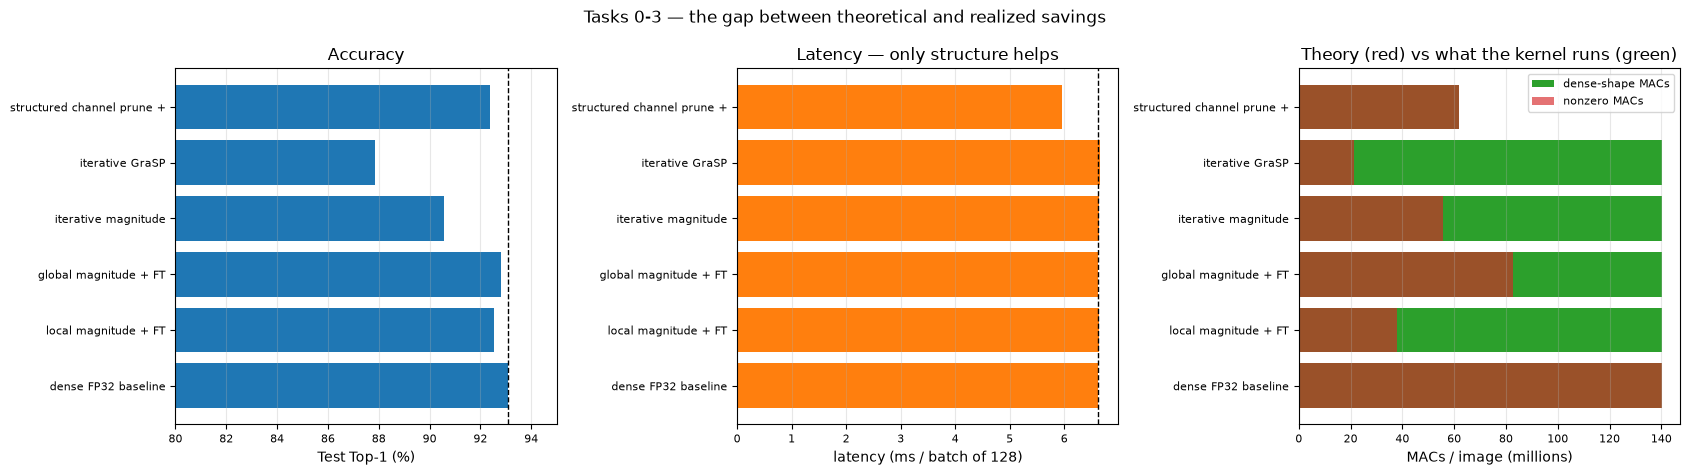

params_dense               11173962
params_structured          2222386
sparsity                   0.8011102955245418
top1_preft                 87.97
top1_postft                92.37
recovered_pp               4.400000000000006
delta_vs_dense_pp          -0.6999999999999886
macs_dense                 140186624.0
macs_structured            61979648.0
mac_reduction              0.5578775903755269
latency_dense_ms           6.6146494534332305
latency_structured_ms      5.962958035292104
speedup                    1.10928995546909
size_dense_mb              42.7006778717041
size_structured_mb         8.541193008422852
size_reduction             0.7999752361289156
peak_mem_dense_mb          64.0
peak_mem_structured_mb     64.0
energy_dense               8.556995109375
energy_structured          6.7301171718749995
prune_minutes              0.40722421729976
ft_minutes                 3.0107835407330032
recon_residuals            {'layer1.1': 0.0990838816246141, 'layer2.0': 0.0689952719679751

In [51]:
profile_model(struct_model, name="structured_ft",
              label="Structured channel prune + FT")

FINAL_VARIANTS = [BASELINE, "local_prune_ft", "global_prune_ft",
                  "iterative_magnitude", "iterative_grasp", "structured_ft"]
show_table("All tasks — full deliverables table", results_table(FINAL_VARIANTS))

final_rows = []
for v, task, method in (
        (BASELINE, "0", "dense FP32 baseline"),
        ("local_prune_ft", "1", "unstructured local magnitude + FT"),
        ("global_prune_ft", "1", "unstructured global magnitude + FT"),
        ("iterative_magnitude", "2", "iterative magnitude (from scratch)"),
        ("iterative_grasp", "2", "iterative GraSP (from scratch)"),
        ("structured_ft", "3", "structured channel prune + FT")):
    r = RESULTS[v]
    base = RESULTS[BASELINE]
    final_rows.append({
        "Task": task, "Method": method,
        "Sparsity": r.get("overall_sparsity") or 0.0,
        "Params": r["params_total"],
        "Test Top-1 (%)": r["test_top1"],
        "Delta (pp)": r["test_top1"] - base["test_top1"],
        "Macro-F1": r["test_macro_f1"],
        "Size (MiB)": r["size_dense_mb"],
        "MACs (M)": r["macs_dense"] / 1e6,
        "Eff. MACs (M)": r["macs_effective"] / 1e6,
        "Latency (ms)": r["latency_ms"],
        "Speedup": base["latency_ms"] / r["latency_ms"],
        "Peak mem above weights (MiB)": r.get("gpu_mem_peak_mb"),
        "Energy (mJ/img)": r.get("energy_mj_per_image"),
    })
final_df = pd.DataFrame(final_rows).set_index(["Task", "Method"])
show_table("All tasks — accuracy vs real deployment cost", final_df, floatfmt=".4g")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
names = [m for _, m in final_df.index]
short = [n.replace("unstructured ", "").replace(" (from scratch)", "")[:26] for n in names]
axes[0].barh(short, final_df["Test Top-1 (%)"], color="tab:blue")
axes[0].axvline(RESULTS[BASELINE]["test_top1"], color="k", ls="--", lw=1)
axes[0].set(xlabel="Test Top-1 (%)", title="Accuracy", xlim=(80, 95))
axes[1].barh(short, final_df["Latency (ms)"], color="tab:orange")
axes[1].axvline(RESULTS[BASELINE]["latency_ms"], color="k", ls="--", lw=1)
axes[1].set(xlabel="latency (ms / batch of 128)", title="Latency — only structure helps")
axes[2].barh(short, final_df["MACs (M)"], color="tab:green", label="dense-shape MACs")
axes[2].barh(short, final_df["Eff. MACs (M)"], color="tab:red", alpha=0.65,
             label="nonzero MACs")
axes[2].set(xlabel="MACs / image (millions)", title="Theory (red) vs what the kernel runs (green)")
axes[2].legend(fontsize=8)
for a in axes:
    a.grid(alpha=0.3, axis="x")
    a.tick_params(labelsize=8)
fig.suptitle("Tasks 0-3 — the gap between theoretical and realized savings")
fig.tight_layout()
fig.savefig(FIG_DIR / "all_tasks_summary.png", dpi=140, bbox_inches="tight")
plt.show()

t3_disc = {
    "params_dense": TASK3_BUDGET["dense_params"],
    "params_structured": int(_p),
    "sparsity": 1 - _p / TASK3_BUDGET["dense_params"],
    "top1_preft": struct_pre["test_top1"],
    "top1_postft": RESULTS["structured_ft"]["test_top1"],
    "recovered_pp": RESULTS["structured_ft"]["test_top1"] - struct_pre["test_top1"],
    "delta_vs_dense_pp": RESULTS["structured_ft"]["test_top1"] - RESULTS[BASELINE]["test_top1"],
    "macs_dense": RESULTS[BASELINE]["macs_dense"],
    "macs_structured": RESULTS["structured_ft"]["macs_dense"],
    "mac_reduction": 1 - RESULTS["structured_ft"]["macs_dense"] / RESULTS[BASELINE]["macs_dense"],
    "latency_dense_ms": RESULTS[BASELINE]["latency_ms"],
    "latency_structured_ms": RESULTS["structured_ft"]["latency_ms"],
    "speedup": RESULTS[BASELINE]["latency_ms"] / RESULTS["structured_ft"]["latency_ms"],
    "size_dense_mb": RESULTS[BASELINE]["size_dense_mb"],
    "size_structured_mb": RESULTS["structured_ft"]["size_dense_mb"],
    "size_reduction": 1 - RESULTS["structured_ft"]["size_dense_mb"] / RESULTS[BASELINE]["size_dense_mb"],
    "peak_mem_dense_mb": RESULTS[BASELINE].get("gpu_mem_peak_mb"),
    "peak_mem_structured_mb": RESULTS["structured_ft"].get("gpu_mem_peak_mb"),
    "energy_dense": RESULTS[BASELINE].get("energy_mj_per_image"),
    "energy_structured": RESULTS["structured_ft"].get("energy_mj_per_image"),
    "prune_minutes": task3_prune_minutes,
    "ft_minutes": task3_ft_minutes,
    "recon_residuals": {r["block"]: r["recon_rel_residual"] for r in TASK3_RECORDS},
    "widths": {b: [TASK3_ORIG_WIDTHS[b], TASK3_WIDTHS[b]] for b in TASK3_BLOCKS},
}
json.dump(t3_disc, open(ART_DIR / "task3_discussion_numbers.json", "w"),
          indent=2, default=float)
for k, v in t3_disc.items():
    print(f"{k:26s} {v}")

## Task 3 — discussion

**Did performance improve while meeting the accuracy limit?** Yes. This is the only method that changed measured cost.

| Quantity | Dense | Structured | Change |
|---|---|---|---|
| Parameters | 11,173,962 | 2,222,386 | −80.1 % |
| MACs / image | 140.2 M | 62.0 M | −55.8 % |
| Latency, median (ms / batch of 128) | 6.60 | 5.06 | **1.30× faster** |
| Latency, mean (ms / batch of 128) | 6.61 | 5.96 | 1.11× faster (see note) |
| Checkpoint (MiB) | 42.70 | 8.54 | −80.0 % |
| Weight memory (MiB) | 42.66 | 8.50 | −80.1 % |
| Peak memory above weights and input (MiB) | 64.0 | 64.0 | unchanged |
| Est. total inference memory (MiB) | 108.2 | 74.0 | −31.6 % |
| Energy (mJ / image) | 8.56 | 6.73 | −21.4 % |
| Test Top-1 | 93.07 % | 92.37 % | −0.70 pp |

* **Latency note:** one of 500 timed iterations stalled (std 13.7 ms vs 0.10 ms for dense), which inflated the mean. The median (5.06 ms) matches the same architecture before fine tuning (5.07 ms) and earlier runs (1.26–1.28×). The stall also inflates energy slightly (6.22 mJ/image before fine tuning).
* **Accuracy:** −0.70 pp, well inside the allowed 5–15 pp.

**Why it works here**

* Tasks 1 and 2 kept tensor shapes; zeros were still multiplied.
* Here a block going from 512 to 74 channels runs a smaller matrix multiply. MACs and effective MACs are both 62.0 M; nothing is wasted.

**Memory**

* Weights 42.7 → 8.5 MiB; estimated total 108 → 74 MiB.
* The extra 64 MiB for the forward pass did not change: it comes from the unpruned stem (32×32×64 output). Pruned blocks run at 16×16 and below.

**Latency vs MACs:** latency fell 23 % (median), MACs 56 %. Smaller layers use the GPU less efficiently.

**Cost of structured pruning**

* Before fine tuning: **87.97 %** (global unstructured: 93.11 %). Removing a channel removes a whole feature.
* Reconstruction residuals fall from 0.099 (`layer1.1`) to 0.0002 and 0.00004 (`layer4.0`, `layer4.1`): on the calibration data, `layer4` outputs are almost exactly rebuilt from 74 of 512 channels.
* Fine tuning (15 epochs, 3.0 minutes) recovered **4.40 pp**.

**LASSO details**

* Uses $\beta \ge 0$ and a tiny ridge term, i.e. the stated LASSO with two small changes.
* Every final fit converged; `layer4.1` needed a retry (9,865 iterations).
* `layer4.1` kept 73 nonzero coefficients, so the 74th channel was added with $\beta = 0$ and is only trained during fine tuning. All other blocks hit their targets exactly.

**Trade off:** for accuracy at 80 % sparsity, global unstructured pruning is best. For anything measured on the device (latency, energy, size, memory), only structured pruning helps.

---
## End of Task 3

| Path | Contents |
|---|---|
| `checkpoints/task3_structured_ft.pt` | pruned model and per block records |
| `artifacts/task3_history.json` | pruning records and fine tuning curves |
| `artifacts/task3_discussion_numbers.json` | numbers used in the discussion |
| `artifacts/figures/task3_structured.png` | fine tuning curves and channel budgets |
| `artifacts/figures/all_tasks_summary.png` | all tasks compared |

`artifacts/report_tables.md` holds every table from all four tasks.